# 中期答辩图表导读

**半挂车右转内轮差预警：短时转角预测方法的仿真比较与代理模型分析**

> 中期答辩临时训练：基于接触标签纠错前评分，非冻结科研资产。

本 notebook 逐张讲解 `tavotoo/` 文件夹里的 60 张图，按一篇论文的顺序编排，默认读者第一次接触这个项目。每张图都有四部分：

- **图表契约**：这张图要证明的一句话结论、每个子图提供哪部分证据、图的类型、数据口径和 n 的含义；
- **来源**：图下方打印 tavotoo 中的 PDF 与独立入口脚本、生成它的原始程序与函数、用到的数据文件；
- **读出来的结论**：关键数字由同一格代码现场从数据算出，文字与打印结果一致；
- **用法**：这张图能支持什么说法，不能支持什么说法。

| 节 | 内容 | 图 |
|---|---|---|
| 0 | 运行准备与来源核对 | — |
| 1 | 研究问题与术语 | — |
| 2 | 方法：车辆模型、四种转角预测、报警与后处理、评分 | — |
| 3 | 一个转弯看懂问题（案例） | 图 1–2 |
| 4 | 实验设计与数据 | 图 3–7 |
| 5 | 仿真结果 | 图 8–15 |
| 6 | 代理模型 | 图 16–48 |
| 7 | 讨论与局限 | — |
| 附录 A | 其余四张数据表的探索图 | 图 49–60 |
| 附录 B–D | 60 张图索引、如何重画与改图、自检 | — |

## 0 运行准备

- **内核**：选 “Python 3.14 (中期答辩)”（解释器 `C:\Users\Admin\AppData\Local\Python\pythoncore-3.14-64\python.exe`），然后 Run All，全部运行约 1–2 分钟。
- **依赖**：numpy、pandas、matplotlib、scipy、Pillow；6.2 节的复现例子另需 scikit-learn，没有时自动跳过。
- **只读**：只读取 `tavotoo/_data/` 中已保存的评分表和模型结果。不训练模型、不跑车辆仿真，也不覆盖 `tavotoo/` 里的任何 PDF/PNG：图在内存中画好后直接显示，附录 D 会核对包内文件一个都没变。
- **显示的是源程序的原图**。在 Tavotto 里做的修改保存在 `tavotoo/tavottofile/`，不会出现在这里；要看修改后的效果请在 Tavotto 中导出。
- 图很宽时 notebook 里的字偏小，请打开同名 PDF（每张图下方都打印了位置）。

In [1]:
# 0.1 环境与路径：找到 tavotoo 编辑包，载入它的公共绘图入口
import sys
sys.dont_write_bytecode = True          # 不在 tavotoo/site-packages 里生成 __pycache__

import hashlib
import io
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd

HERE = Path.cwd()
CANDIDATES = (HERE / "tavotoo", HERE.parent / "tavotoo", HERE,
              Path(r"E:\大创内轮差项目\申报与答辩\06_中期答辩临时训练\全部图表\tavotoo"))   # 最后一项：本机的默认位置
TAV = next((p for p in CANDIDATES if (p / "figure_manifest.json").exists()), None)
assert TAV is not None, "找不到 tavotoo 编辑包：请在 全部图表/ 目录中打开本 notebook"
ROOT = TAV.parents[1]                   # 06_中期答辩临时训练/
DATA = TAV / "_data"
sys.path.insert(0, str(TAV / "site-packages"))

import matplotlib
matplotlib.use("Agg")                   # 图只在内存中画，再转成 PNG 显示
import matplotlib.pyplot as plt
from IPython.display import Image, display
from PIL import Image as PILImage

from _support import draw               # tavotoo 包的公共入口：用已保存的结果构造一张 Matplotlib 图（Tavotto 渲染用的也是它）
from _plot_config import FEATURE_LABEL, HEADER, SAFETY_RECALL, TIER_A, target_label

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 80)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.precision", 3)

MANIFEST = json.loads((TAV / "figure_manifest.json").read_text(encoding="utf-8"))
ENTRY = {e["stem"]: e for e in MANIFEST["entries"]}
# 先记下包内文件的修改时间，附录 D 核对本 notebook 没有改动任何文件（Tavotto 自己的编辑记录 tavottofile/ 不计）
SNAPSHOT = {p: p.stat().st_mtime_ns for p in TAV.rglob("*") if p.is_file() and "tavottofile" not in p.parts}
print("tavotoo 编辑包：", TAV)
print("登记的图：", len(ENTRY), "张；包内文件：", len(SNAPSHOT), "个")
print(HEADER)

tavotoo 编辑包： E:\大创内轮差项目\申报与答辩\06_中期答辩临时训练\全部图表\tavotoo
登记的图： 60 张；包内文件： 261 个
中期答辩临时训练：基于接触标签纠错前评分，非冻结科研资产。


In [2]:
# 0.2 三个小工具：origin() 查一张图的来源；show() 在内存中重画并显示；load() 读包内数据表
RENDERED = {}                           # 本次运行重画过的图及耗时（附录 D 自检用）
DESC_FUNC = {"fig01": ("fig01()", "D1.csv"), "fig02": ("fig02()", "D1.csv"), "fig03": ("fig03()", "D1.csv"),
             "fig04": ("fig04()", "D1.csv"), "fig05": ("fig05()", "D2.csv、D4.csv"), "fig06": ("fig06()", "D3.csv"),
             "fig07": ("fig07()", "D5.csv"), "fig12": ("fig09()", "deepseek_paired_bounds.csv")}


def origin(stem):
    """返回（原始程序, 函数, 数据）。原始程序的逐字副本在 tavotoo/_source_reference/。"""
    g = ENTRY[stem]["group"]
    if g == "p0":
        return "P0_数据整理/build_all.py", "explore()", f"_data/{stem.rsplit('_', 1)[-1]}.csv"
    if g == "descriptive":
        func, data = DESC_FUNC[stem[:5]]
        return "描述性图表/make_figures.py", func, "_data/" + data
    if g == "case_svg":
        return ("描述性图表/make_case_figures.py", "main()",
                f"原程序用冻结 v3 预测器逐帧重算后导出 SVG；包内从 _data/case_svg/{stem}.svg 重建")
    if g == "summary":
        return "汇总/summarize.py", "work()", "_data/M*/tiers.csv"
    return f"{g}/train.py（训练）+ common/figures.py（出图）", "family_figures()", f"_data/{g}/"


def show(stem, width=1100, dpi=110):
    """在内存中重画 tavotoo 包里的一张图并显示，不写任何文件。width 为显示宽度（像素）。"""
    e = ENTRY[stem]
    target = stem.split("__", 1)[1] if "__" in stem else stem   # 模型图在包里加了 M1__ 等前缀，原图名不带
    t0 = time.time()
    fig = draw(e["group"], target)
    has_colorbar = any(a.get_label() == "<colorbar>" for a in fig.axes)
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=dpi, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    im = PILImage.open(buf).convert("RGB")
    if im.width > width:
        im = im.resize((width, round(im.height * width / im.width)), PILImage.Resampling.LANCZOS)
    if not has_colorbar:            # 没有连续色标的图用 256 色预览，减小 notebook 体积；有色标的保留真彩色，避免色标出现色阶
        im = im.quantize(colors=256, method=PILImage.Quantize.MEDIANCUT, dither=PILImage.Dither.NONE)
    out = io.BytesIO()
    im.save(out, format="PNG", optimize=True)
    RENDERED[stem] = round(time.time() - t0, 2)
    display(Image(data=out.getvalue()))
    prog, func, data = origin(stem)
    print(f"tavotoo 文件：{e['pdf']}（独立入口 {e['script']}）")
    print(f"原始程序：{prog} → {func}；数据：{data}")


def load(name):
    """读取 tavotoo/_data 中的表，例如 load("D1")、load("M3_二级处理联合/tiers")。"""
    p = DATA / name
    for cand in (p, p.with_suffix(".csv"), Path(f"{p}.csv.gz")):
        if cand.is_file():
            return pd.read_csv(cand, low_memory=False)
    raise FileNotFoundError(name)


D = {k: load(k) for k in ("D1", "D2", "D3", "D4", "D5")}
print({k: v.shape for k, v in D.items()})

{'D1': (513, 64), 'D2': (864, 64), 'D3': (7800, 72), 'D4': (576, 72), 'D5': (8064, 72)}


### 0.3 来源核对

tavotoo 包是从原始结果复制出来的编辑包。下面核对三件事：包内每个副本与登记的 SHA-256 一致；原件仍在本机且没有变化；`_source_reference/` 中的程序副本与仓库里的原程序一致（统一换行符后逐字节比较）。全部为“是”，说明这里重画的图就是原程序在原数据上画出的图。

In [3]:
def sha256(p):
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()


def kind(path):
    parts = Path(path).parts
    if parts[0] == "_source_reference":
        return "原程序副本"
    if parts[0] == "_data":
        if len(parts) == 2:
            return "评分表与区间表"
        return "案例图 SVG" if parts[1] == "case_svg" else "模型结果 " + parts[1].split("_")[0]
    return "PNG 预览" if path.endswith(".png") else "案例图原 PDF"


rows = []
for c in MANIFEST["copied_inputs"]:
    src = Path(c["source"])
    rows.append({"类别": kind(c["path"]), "包内副本一致": sha256(TAV / c["path"]) == c["sha256"],
                 "原件在本机": src.exists(), "原件一致": src.exists() and sha256(src) == c["sha256"]})
chk = pd.DataFrame(rows).groupby("类别").agg(文件数=("类别", "size"), 包内副本一致=("包内副本一致", "sum"),
                                             原件在本机=("原件在本机", "sum"), 原件一致=("原件一致", "sum"))
display(chk)

norm = lambda b: b.replace(b"\r\n", b"\n")
ref = []
for t in sorted((TAV / "_source_reference").glob("*.txt")):
    rel = t.name[:-4].replace("__", "/")
    src = ROOT / rel
    ref.append({"原程序": rel, "与 tavotoo 副本一致": src.exists() and norm(t.read_bytes()) == norm(src.read_bytes())})
display(pd.DataFrame(ref).set_index("原程序"))
print("全部一致：", bool((chk["包内副本一致"] == chk["文件数"]).all() and (chk["原件一致"] == chk["文件数"]).all()
                       and all(r["与 tavotoo 副本一致"] for r in ref)))

,文件数,包内副本一致,原件在本机,原件一致
类别,,,,
PNG 预览,60,60,60,60
原程序副本,7,7,7,7
案例图 SVG,2,2,2,2
案例图原 PDF,2,2,2,2
模型结果 M1,6,6,6,6
模型结果 M2a,6,6,6,6
模型结果 M2b,6,6,6,6
模型结果 M3,10,10,10,10
模型结果 M4,7,7,7,7


,与 tavotoo 副本一致
原程序,
common/config.py,True
common/figures.py,True
common/plotting.py,True
P0_数据整理/build_all.py,True
描述性图表/make_case_figures.py,True
描述性图表/make_figures.py,True
汇总/summarize.py,True


全部一致： True


## 1 研究问题

**内轮差**：车辆转弯时，后轮走的弧线比前轮更靠近弯心。半挂车（牵引车 + 挂车）轴距长，挂车后部会比车头更深地切进弯内。右转时站在右前方路口的行人和电动车，常常在司机以为“车头已经过去了”之后，被向内扫过来的挂车车身碰到，这是货车右转碾压事故的主要形态。

**本项目的系统**：车载 ESP32 每 20 ms 读一次车速、牵引车前轮转角 α 和牵引车—挂车铰接角 φ，用车辆运动学预测**未来 2 s 内车辆右侧会扫过的区域**（扫掠区）；雷达和视觉检测到的目标落进扫掠区就分级报警。报警必须够早：本项目把“提前不到 1 s”算作不合格，司机来不及反应。

**难点**：未来 2 s 里司机还在继续打方向，α 在变。最简单的做法是假设 α 保持当前值（**保持**，hold）。它在入弯时总是低估将要扫到的范围，报警偏晚。中期阶段的仿真实验回答四个问题：

1. 预测 α 的变化趋势（线性、衰减线性、受限二阶外推），能减少多少迟报？误报代价多大？（S1，第 5.1 节）
2. 传感器噪声和延迟会把结论改变多少？简单预处理和状态估计能否补救？（S2、S4 状态估计，第 5.2 节）
3. 报警后处理（出弯窗口、空间膨胀、确认时间）怎样改变迟报与误报的平衡？（S3，第 5.3 节）
4. 在选定方法附近细调趋势增益，还有多大空间？（S4 联合精化，第 5.4 节）

最后用机器学习**代理模型**学习“实验设置 → 评分”的关系，检验这些规律是否稳定、能否推广到没见过的轨迹（第 6 节）。

### 1.1 术语表

| 术语 | 含义 |
|---|---|
| α | 牵引车前轮转角。本阶段全部轨迹都是 90° 右转，转角峰值 10° |
| φ | 铰接角：牵引车与挂车纵轴的夹角 |
| v_B | 牵引车后轴中心 B 点的车速，2–4 m/s（约 7–14 km/h） |
| 扫掠区 / 预测区 | 真实的 / 预测的未来 2 s 内车辆右侧扫过的区域 |
| RIGHT 目标 | 会被挂车车身**右侧**先碰到的目标点；被挂车前缘（牵引销处）或前角先碰到的记为 FRONT，不参与迟报评分 |
| 有效报警、提前量 | 报警后 2 s 内目标确实被碰到才算有效报警；提前量 = 接触时刻 − 首次有效报警时刻 |
| **RIGHT 不足率** | RIGHT 目标中“窗口漏报（始终没有有效报警）或提前量 < 1 s”的比例（%）。本项目的迟报主指标，越低越好 |
| 窗口漏报率 | RIGHT 目标中始终没有有效报警的比例（%） |
| 提前量 P10 | RIGHT 目标提前量的第 10 百分位（s），看最差的一成 |
| **近场误报率** | 扫掠区外 0.05–0.5 m、实际不会被碰到的目标点中，评分时段内被报警过的比例（%）；图中写作“近场点误报率” |
| 逐帧误报率 | 把“每个目标点 × 每一帧”看成一次判断，在本不该报警的判断中报警的比例（%） |
| 共同 2 s 误报率 | 同逐帧误报率，但一律按 2 s 窗口判断“该不该报”，使出弯窗口 2 s 与 3 s 的变体能直接比较 |
| 误报预算达标 | 近场误报率 ≤ 5%，且逐帧误报率与共同 2 s 误报率都 ≤ 0.5% |
| 端点误差 | 预测的未来右缘端点与真实位置的距离（m）；纯几何量，与接触标签无关 |
| 配对差 | 同一轨迹、同一条件下，某做法减去参照（保持、无后处理或 raw）的差，记作“− 保持”等，单位 pp（百分点） |
| v3 口径 / 修正口径 | 两版评分程序。修正口径从 2 s 起统计误报和帧数；RIGHT 类指标完全不变，误报类数值略低，方法排序不变。S1、S2 用 v3，S3、S4 用修正口径 |
| 接触标签纠错前 | “目标点先被哪条边碰到”的标签在车身拐角处有已知错误，纠错尚未完成，见 2.5 节 |

## 2 方法

### 2.1 车辆模型

仿真车辆是牵引车 + 半挂车：牵引车轴距 l = 4.0 m，牵引销到牵引车后轴的距离 l_h = 1.8 m，挂车轴距 L = 13.5 m，车宽 W = 2.0 m。状态为牵引车后轴中心 B 的位置 (x_B, y_B)、航向 θ 和铰接角 φ：

$$\omega_1=\frac{v_B\tan\alpha}{l},\qquad \omega_2=\frac{v_B\sin\varphi+l_h\,\omega_1\cos\varphi}{L},\qquad \dot\varphi=\omega_1-\omega_2$$

ω₁、ω₂ 分别是牵引车和挂车的横摆角速度；l_h·ω₁ 是牵引销偏置带来的耦合项，不能省略。积分步长 0.02 s（RK4）。扫掠区是挂车车身在未来 2 s 内扫过的区域，评分看的是它的右侧边缘。

### 2.2 四种转角预测方法

在当前时刻，用过去 0.2 s 的转角做因果二次拟合，得到转角速率 α̇ 和转角加速度 α̈（分别限幅 ±32°/s、±160°/s²）；然后假设未来 u ∈ [0, 2] s 的转角 α(u)，代入 2.1 的模型向前推 2 s。记 r = clip(g·α̇, ±32°/s)，g 为趋势增益：

| 方法 | 未来转角假设 α(u) | 参数（配置名里的数字） |
|---|---|---|
| 保持 hold | α(u) = α₀ | 无 |
| 线性 linear | α(u) = α₀ + r·u | 增益 g：`linear_g075` 即 g = 0.75 |
| 衰减线性 damped_linear | α(u) = α₀ + r·τ′·(1 − e^(−u/τ′))，τ′ = max(τ, \|r\| / 160°/s²) | 衰减时间 τ：`damped_d1000` 即 τ = 1 s |
| 受限二阶 bounded_second_order | 先按 α̈ 加速至多 T_a 秒（转角速率到 ±32°/s 即停止加速），之后保持末速率 | 生效时长 T_a：`second_a0250` 即 T_a = 0.25 s |

最后都限幅 |α| ≤ 30°。直观地说：保持认为司机马上停止转方向盘；线性认为按当前速率一直转下去；衰减线性认为还会继续转但越来越慢，总增量约 r·τ；受限二阶还考虑“正在加速转”。下面用一组假设的数字演示四种假设的差别（公式与冻结 v3 预测器的 `future_alpha()` 相同）。

In [4]:
RATE, ACC, ALPHA_MAX = 32.0, 160.0, 30.0          # 转角速率限幅 °/s、加速度限幅 °/s²、转角限幅 °


def future_alpha(a0, dot, ddot, u, mode, g=1.0, tau=0.5, ta=0.25):
    """未来 u 秒的转角假设（单位：°、°/s、°/s²）。"""
    dot, ddot = np.clip(dot, -RATE, RATE), np.clip(ddot, -ACC, ACC)
    r = np.clip(g * dot, -RATE, RATE)
    if mode == "hold":
        a = a0
    elif mode == "linear":
        a = a0 + r * u
    elif mode == "damped_linear":
        tau_eff = max(tau, abs(r) / ACC)
        a = a0 + r * tau_eff * (1 - np.exp(-u / tau_eff))
    else:                                         # bounded_second_order
        bound = RATE if ddot >= 0 else -RATE
        crossing = (bound - r) / ddot if abs(ddot) > 1e-12 else np.inf
        act = min(u, ta, max(0.0, crossing))
        a = a0 + r * act + 0.5 * ddot * act ** 2 + np.clip(r + ddot * act, -RATE, RATE) * (u - act)
    return float(np.clip(a, -ALPHA_MAX, ALPHA_MAX))


a0, dot, ddot = 2.0, 4.0, 8.0                    # 假设：入弯初期，转角 2°，正以 4°/s 增大，并在加速（8°/s²）
u = [0.0, 0.5, 1.0, 1.5, 2.0]
demo = pd.DataFrame({
    "保持": [future_alpha(a0, dot, ddot, x, "hold") for x in u],
    "线性 g=0.5": [future_alpha(a0, dot, ddot, x, "linear", g=0.5) for x in u],
    "衰减线性 τ=1 s": [future_alpha(a0, dot, ddot, x, "damped_linear", tau=1.0) for x in u],
    "受限二阶 T_a=0.25 s": [future_alpha(a0, dot, ddot, x, "bounded_second_order", ta=0.25) for x in u],
}, index=pd.Index(u, name="未来时刻 u (s)")).round(2)
display(demo)

,保持,线性 g=0.5,衰减线性 τ=1 s,受限二阶 T_a=0.25 s
未来时刻 u (s),,,,
0.0,2.0,2.0,2.00,2.00
0.5,2.0,3.0,3.57,4.75
1.0,2.0,4.0,4.53,7.75
1.5,2.0,5.0,5.11,10.75
2.0,2.0,6.0,5.46,13.75


同一时刻、同样的观测，四种假设到 2 s 时相差很大：保持停在 2°，线性 g=0.5 到 6°，衰减线性到约 5.5°，受限二阶到约 13.8°。假设越激进，预测区越大，入弯时越早覆盖目标（迟报少），但转向即将停止时也越容易“预测过头”（误报多）。这就是第 5 节反复出现的迟报—误报权衡。

### 2.3 报警与后处理

每一帧把预测的未来 2 s 右缘扫掠区（逐步拼接的小四边形的并集）与目标点比较：点到扫掠区的距离 ≤ 0.05 m（再加空间膨胀 m）就判为命中。三种后处理：

- **出弯窗口 W**：观测到车辆处于回正阶段时，把预测窗口从 2 s 延长到 W（2 s 或 3 s）；
- **空间膨胀 m**：扫掠区向外放宽 m（0、0.02、0.05 m），宁可多报；
- **确认时间 c**：命中要连续保持 c（0 或 0.1 s）才报警，用来压掉闪报。

变体记作 `W2_m0.05_c0.1`（W = 2 s、膨胀 0.05 m、确认 0.1 s）；`W2_m0_c0` 是“无后处理”。

### 2.4 评分

- 只评接触时刻在 [2 s, 结束前 3 s] 内的目标：开头 2 s 没有完整的历史预测窗口，结尾 3 s 留给出弯窗口。
- RIGHT 类指标只统计 RIGHT 目标；误报类指标统计近场非接触点和逐帧判断。
- 每条轨迹 70,000 个静态目标点，三类各约三分之一：右边界邻域、扫掠区内部、近场非接触（扫掠区外 0.05–0.5 m，每条轨迹 23,333 个）。
- 观测扰动：1 倍噪声为 α、φ、v 分别加标准差 0.15°、0.25°、0.04 m/s 的噪声；纯延迟 50/100/200 ms；combined100 = 1 倍噪声 + 100 ms 延迟；带噪声的条件各有 3 个随机种子（s1–s3）。
- 目标点和帧都**不是独立的车辆试验**，最接近“独立样本”的单位是轨迹。

### 2.5 三类口径

接触标签纠错尚未完成，所以每个结论都要标明口径：

| 口径 | 是什么 | 能说到什么程度 |
|---|---|---|
| 标签无关 | 端点误差、漏覆盖面积等纯几何量 | 可以直接引用 |
| 配对差 | 同一轨迹、同一条件下两种做法相减 | 方向可信度较高，有标签区间旁证（图 15） |
| 绝对值 | 某一做法的不足率、误报率本身 | 只作描述，纠错后数值会变 |

## 3 一个转弯看懂问题

先看一个具体例子：S1 中车速最高、转向最快的一条较快入弯轨迹 `v4_r8_fast_entry`（4 m/s，基准转角速率 8°/s，入弯速率是它的 2 倍）。两张图由 `描述性图表/make_case_figures.py` 用冻结的 v3 预测器逐帧重算得到，重算出的报警时刻与原评分作业逐点一致。tavotoo 包里这两张图是从原 SVG 重建的矢量图（不重新仿真）：可以改字体、颜色和版式，不能通过改坐标轴数值来改物理范围。

In [5]:
CASE_DIR = ROOT / "描述性图表" / "source_data"      # make_case_figures.py 写出的源数据
CASE = json.loads((CASE_DIR / "fig13_fig14_case_summary.json").read_text(encoding="utf-8")) if CASE_DIR.exists() else None
print("案例源数据：", CASE_DIR if CASE else "不在本机（只影响下面的数字，不影响出图）")

案例源数据： E:\大创内轮差项目\申报与答辩\06_中期答辩临时训练\描述性图表\source_data


### 图 1　案例：同一帧里三种方法的预测区

**图表契约**
- **结论**：入弯初期，“保持”假设转角不再变化，严重低估未来 2 s 挂车右侧会扫过的区域；“衰减线性”利用转角正在增大的趋势，把漏掉的面积几乎全部补回，这片区域里的目标因此能被提前报警。
- **证据**：a 关键帧在车身坐标系中叠加真实扫掠区与三种预测区，给出漏覆盖面积和被提前覆盖的目标数（核心证据）；b 整个转弯的轨迹与 70,000 个目标点（交代 a 在转弯中的位置）；c 同一帧三种方法对未来转角的假设（差异从哪里来）；d 全程每帧的漏覆盖面积（改善发生在哪个阶段）。
- **类型**：schematic-led composite（几何示意为主，配时间序列定量）。
- **口径**：S1 clean，一条轨迹；窗口 2 s、无膨胀、无确认。a、c、d 是几何量，与接触标签无关；a 中“被提前覆盖的目标”按纠错前标签筛选。关键帧是“保持漏覆盖 − 衰减线性漏覆盖”最大的一帧，即差别最明显的一帧。

**怎么读**：a 的横轴沿当前行驶方向，纵轴向左为正。浅灰 = 真实的未来 2 s 右缘扫掠区；淡红 = 保持漏掉的部分；蓝色半透明 = 其中被衰减线性补上的部分；三条轮廓 = 三种方法的预测区（红 保持，青色虚线 线性 g=0.5，深蓝 衰减线性 τ=1 s）；蓝点 = 2 s 内会被挂车右侧扫到、只有衰减线性提前覆盖的目标。c 中黑线是已观测的转角，灰色点线是真实的未来。d 越低越好，顶部写了全程均值；图中的“入弯 / 保持 / 回正”是转弯阶段，这里的“保持”指转角保持不变的稳态段，不是保持方法。

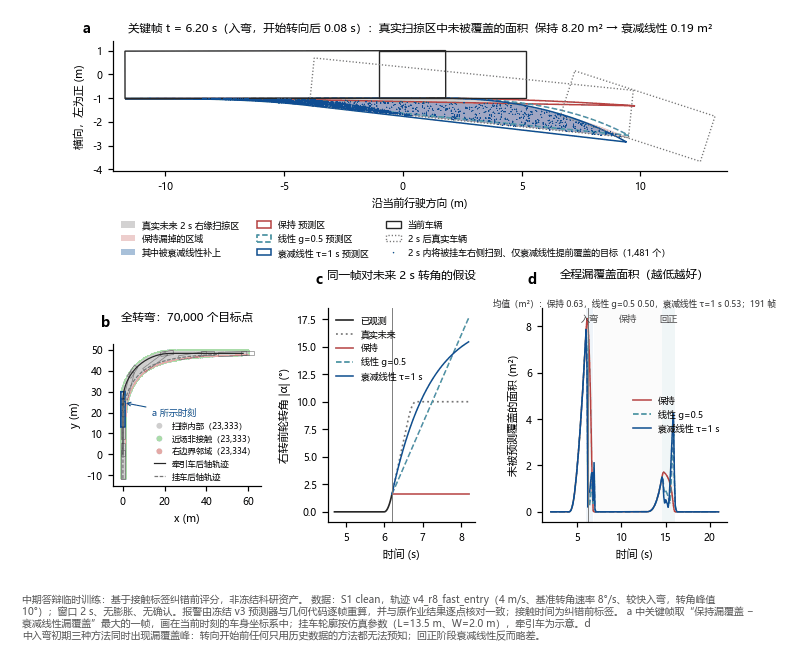

tavotoo 文件：02_描述性图表\fig13_案例_预测区叠加.pdf（独立入口 02_描述性图表\fig13_案例_预测区叠加.py）
原始程序：描述性图表/make_case_figures.py → main()；数据：原程序用冻结 v3 预测器逐帧重算后导出 SVG；包内从 _data/case_svg/fig13_案例_预测区叠加.svg 重建
轨迹 v4_r8_fast_entry：关键帧 t = 6.20 s（入弯），开始转向 6.12 s
关键帧未被覆盖的面积：保持 8.20 m² → 衰减线性 0.19 m²；补上 8.00 m²，被提前覆盖的目标 1,481 个
每帧平均未被覆盖的面积（m²）：


,保持,线性 g=0.5,衰减线性 τ=1 s
phase,,,
转向前直行,1.22,1.22,1.22
入弯,5.25,2.18,2.33
稳态转弯,0.10,0.13,0.13
回正,1.19,1.25,1.43
出弯后,0.00,0.01,0.01
全程（191 帧）,0.63,0.50,0.53


In [6]:
show("fig13_案例_预测区叠加")
if CASE:
    f13 = CASE["fig13"]
    print(f"轨迹 {CASE['case']}：关键帧 t = {f13['time_s']:.2f} s（{f13['phase']}），开始转向 {CASE['fig14']['steering_onset_s']:.2f} s")
    print(f"关键帧未被覆盖的面积：保持 {f13['missed_hold_m2']:.2f} m² → 衰减线性 {f13['missed_damped_m2']:.2f} m²；"
          f"补上 {f13['recovered_m2']:.2f} m²，被提前覆盖的目标 {f13['targets_gained']:,} 个")
    area = pd.read_csv(CASE_DIR / "fig13_missed_area_series.csv")
    cols = {"missed_hold": "保持", "missed_linear_g050": "线性 g=0.5", "missed_damped_d1000": "衰减线性 τ=1 s"}
    phase = {0: "转向前直行", 1: "入弯", 2: "稳态转弯", 3: "回正", 4: "出弯后"}
    tab = area.groupby("phase")[list(cols)].mean().rename(columns=cols, index=phase)
    tab.loc[f"全程（{len(area)} 帧）"] = area[list(cols)].mean().rename(cols)
    print("每帧平均未被覆盖的面积（m²）：")
    display(tab.round(2))

**读出来的结论**：关键帧 t = 6.20 s 处在入弯（开始转向后仅 0.08 s）。真实扫掠区中没被覆盖的面积，保持是 8.20 m²，衰减线性只有 0.19 m²，补上 8.00 m²，涉及 1,481 个目标点。按阶段平均：转向开始前三种方法完全相同（都无从预知即将开始的转弯）；入弯阶段保持漏 5.25 m²，线性和衰减线性降到 2.18 / 2.33 m²；回正阶段衰减线性反而略差（1.43 对 1.19 m²），因为回正时转角在变小，外推会预测“回正得更快”。

**用法**：用来解释趋势外推**为什么**能减少迟报。不能用来说明改善幅度的一般水平（这是最难的一条轨迹上差别最大的一帧），也不反映误报代价（见 图 10）。

### 图 2　案例：报警—接触时间轴上的改善与失败

**图表契约**
- **结论**：衰减线性能把一部分迟报变成及时报警；但对“开始转向后不到 1 s 就被碰到”的目标，任何只用历史数据的方法都来不及提前 1 s，这是剩下的迟报的主要来源。
- **证据**：a/b 改善案例的位置与时间轴（保持迟报、衰减线性及时）；c/d 失败案例的位置与时间轴（衰减线性仍迟报）；e 该轨迹全部 RIGHT 目标的提前量分布，统计改善数、仍迟报数和它们的接触时间。
- **类型**：asymmetric mixed-modality（几何案例 + 时间轴 + 分布）。
- **口径**：同 图 1 的轨迹与设置；提前量依赖纠错前接触标签。两个案例按规则选出：改善案例取“提前量增幅最接近中位数”的目标，失败案例取“仍迟报目标中提前量最接近中位数”的目标。目标点不是独立试验。

**怎么读**：a、c 画接触前 1 s 的两种预测区、接触前 1 s 和接触时的车辆，金色星号是目标。b、d 每行一种方法：色块 = 目标落在 2 s 预测区内的时段，▼ = 首次有效报警，提前量 = 接触时刻 − ▼；淡红色带是接触前需要的 1 s 反应时间，▼ 落在色带左侧才算及时。e 的纵轴是对数刻度，红色虚线是 1 s 反应阈值，圆点和叉标出两个案例。

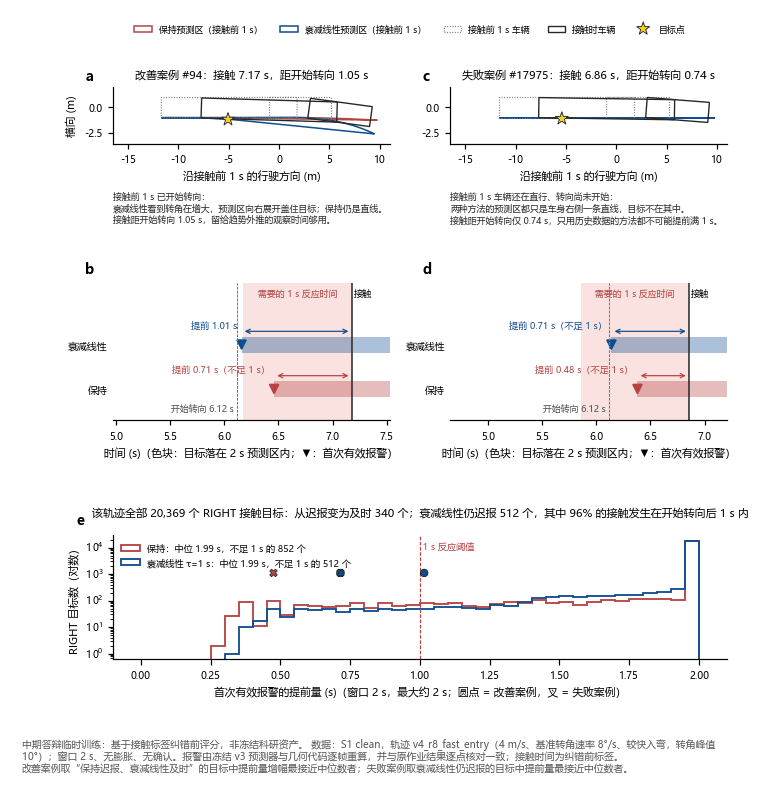

tavotoo 文件：02_描述性图表\fig14_案例_报警接触时间轴.pdf（独立入口 02_描述性图表\fig14_案例_报警接触时间轴.py）
原始程序：描述性图表/make_case_figures.py → main()；数据：原程序用冻结 v3 预测器逐帧重算后导出 SVG；包内从 _data/case_svg/fig14_案例_报警接触时间轴.svg 重建
改善案例 #94：接触 7.175 s，距开始转向 1.05 s；提前量 保持 0.71 s → 衰减线性 1.01 s
失败案例 #17975：接触 6.855 s，距开始转向 0.74 s；提前量 保持 0.48 s → 衰减线性 0.71 s
RIGHT 目标 20,369 个；提前量 < 1 s：保持 852 个 → 衰减线性 512 个；变为及时 340 个，变差 0 个
衰减线性仍迟报的 512 个中，开始转向后 1 s 内接触的占 96%
提前量中位数：保持 1.99 s，衰减线性 1.99 s
重算的报警时刻与原评分作业一致： True


In [7]:
show("fig14_案例_报警接触时间轴")
if CASE:
    f14 = CASE["fig14"]
    onset = f14["steering_onset_s"]
    for c in f14["cases"]:
        print(f"{c['case']} #{c['idx']}：接触 {c['contact_s']:.3f} s，距开始转向 {c['contact_s'] - onset:.2f} s；"
              f"提前量 保持 {c['contact_s'] - c['valid_hold']:.2f} s → 衰减线性 {c['contact_s'] - c['valid_damped_d1000']:.2f} s")
    leads = pd.read_csv(CASE_DIR / "fig14_right_target_leads.csv")
    lh, ld = leads.lead_hold, leads.lead_damped_d1000
    late = leads[ld < 1]
    print(f"RIGHT 目标 {len(leads):,} 个；提前量 < 1 s：保持 {(lh < 1).sum()} 个 → 衰减线性 {(ld < 1).sum()} 个；"
          f"变为及时 {((lh < 1) & (ld >= 1)).sum()} 个，变差 {((lh >= 1) & (ld < 1)).sum()} 个")
    print(f"衰减线性仍迟报的 {len(late)} 个中，开始转向后 1 s 内接触的占 {((late.contact_s - onset) < 1).mean():.0%}")
    print(f"提前量中位数：保持 {lh.median():.2f} s，衰减线性 {ld.median():.2f} s")
    print("重算的报警时刻与原评分作业一致：", all(x["match"] for x in f14["checks"]))

**读出来的结论**：改善案例 #94 在 7.175 s 接触，提前量从 0.71 s 增到 1.01 s，越过 1 s 阈值。失败案例 #17975 接触时距开始转向只有 0.74 s：接触前 1 s 车还在直行，两种方法都无从预知，提前量只从 0.48 s 增到 0.71 s。全轨迹 20,369 个 RIGHT 目标中，提前量不足 1 s 的从保持的 852 个降到衰减线性的 512 个（340 个变为及时，没有一个变差）；仍迟报的 512 个里 96% 在开始转向后 1 s 内接触。两种方法的提前量中位数都是 1.99 s：大多数目标本来就报得足够早，差别集中在入弯初期的少数目标上。

**用法**：说明方法改善的是提前量，以及剩余失败的物理原因（转向开始得太晚，信息不可得）。只来自一条轨迹，不代表一般的失败率；整体比较见第 5 节。

## 4 实验设计与数据

### 4.1 轨迹与目标点

- **开发集 27 条**：车速 v_B ∈ {2, 3, 4} m/s × 基准转角速率 r ∈ {2, 4, 8} °/s × 3 种动作模板：对称（入弯、回正速率都是 r）、较快入弯（入弯 2r）、较快回正（回正 2r）。命名如 `v3_r4_fast_entry`。
- **选择集 12 条**：v_B ∈ {2.5, 3.5} × r ∈ {3, 6} × 3 模板，以 `sel_` 开头；用于调参（S4）和代理模型的外部检验（M3）。
- 全部是 90° 右转、转角峰值 10°：**只有一种转弯几何**。
- 每条轨迹 70,000 个静态目标点（见 2.4 节）。

In [8]:
traj = D["D3"].drop_duplicates("case_id")[["case_id", "partition", "v_B_mps", "base_rate_deg_s", "entry_rate_deg_s",
                                         "return_rate_deg_s", "template", "alpha_peak_deg"]]
grid = traj.groupby("partition").agg(轨迹数=("case_id", "size"), 车速=("v_B_mps", lambda s: sorted(s.unique())),
                                     基准转角速率=("base_rate_deg_s", lambda s: sorted(s.unique())),
                                     动作模板=("template", lambda s: sorted(s.unique())),
                                     转角峰值=("alpha_peak_deg", lambda s: sorted(s.unique())))
display(grid)
print("同一车速、同一基准速率 r = 4°/s 下三种模板的入弯 / 回正速率：")
display(traj[(traj.v_B_mps == 3) & (traj.base_rate_deg_s == 4)].set_index("case_id")[["template", "entry_rate_deg_s", "return_rate_deg_s"]])
cnt = D["D1"].groupby("case_id")[["negative_count", "right_contacts"]].first()
print(f"每条轨迹的近场非接触点 {cnt.negative_count.min():,}–{cnt.negative_count.max():,} 个；"
      f"S1 clean 中 RIGHT 接触目标 {cnt.right_contacts.min():,.0f}–{cnt.right_contacts.max():,.0f} 个（中位数 {cnt.right_contacts.median():,.0f}）")

,轨迹数,车速,基准转角速率,动作模板,转角峰值
partition,,,,,
development_v2_n70000,27,"[2.0, 3.0, 4.0]","[2.0, 4.0, 8.0]","[fast_entry, fast_return, symmetric]",[10.0]
selection_v2,12,"[2.5, 3.5]","[3.0, 6.0]","[fast_entry, fast_return, symmetric]",[10.0]


同一车速、同一基准速率 r = 4°/s 下三种模板的入弯 / 回正速率：


,template,entry_rate_deg_s,return_rate_deg_s
case_id,,,
v3_r4_fast_entry,fast_entry,8.0,4.0
v3_r4_fast_return,fast_return,4.0,8.0
v3_r4_symmetric,symmetric,4.0,4.0


每条轨迹的近场非接触点 23,333–23,333 个；S1 clean 中 RIGHT 接触目标 20,042–24,614 个（中位数 22,320）


### 4.2 四个实验阶段与五张数据表

| 阶段 | 问的问题 | 设计 | 数据表 | 口径 |
|---|---|---|---|---|
| S1 方法对照 | 哪种预测方法和参数迟报最少，代价多少 | 27 条开发轨迹 × 19 个配置（保持 + 线性 6 档 g + 衰减线性 6 档 τ + 受限二阶 6 档 T_a）；clean，无后处理 | D1 | v3 |
| S2 观测扰动 | 噪声、延迟会把结论改变多少；简单预处理能否补救 | 6 条代表轨迹 × 3 方法（保持、线性 g=0.5、衰减线性 τ=1 s）× 16 种观测条件 × 3 种预处理（raw、仅转角低通、按测量年龄前推） | D2 | v3 |
| S3 二级处理 | 出弯窗口、膨胀、确认怎样改变迟报—误报平衡 | 39 条轨迹 × 2 方法（线性 g=0.5、衰减线性 g=1 τ=1 s）× 8 种观测条件 × 12 种后处理变体，另加保持基线 | D3 | 修正 |
| S4 状态估计 | φ 的 EKF 和 α 低通能否压误报 | 6 条轨迹 × 3 方法 × 8 种条件 × 4 种输入处理 | D4 | 修正 |
| S4 联合精化 | 在选定方法附近细调增益还有多大空间 | 12 条选择轨迹 × 7 配置（线性 g 0.375/0.5/0.625、衰减线性 g 0.75/1/1.25、保持）× 8 种条件 × 12 种变体 | D5 | 修正 |

8 种观测条件 = clean、delay100、noise100 × 3 种子、combined100 × 3 种子；S2 的 16 种另含 delay50/200 和 noise050/200。一行 = 一条轨迹 × 一个配置 × 一种观测条件 ×（一种输入处理或后处理变体）的评分；同一个仿真作业的 12 个后处理变体共用一条预测。

In [9]:
rows = []
for k, d in D.items():
    rows.append({"表": k, "行": len(d), "轨迹": d.case_id.nunique(), "仿真作业": d.job_id.nunique(), "配置": d.config_id.nunique(),
                 "观测条件": d.condition.nunique(), "输入处理": d.processor.nunique(), "后处理变体": d.variant.nunique(),
                 "评分口径": "、".join(sorted(map(str, d.score_version.unique()))), "轨迹集": "、".join(sorted(d.partition.unique()))})
display(pd.DataFrame(rows).set_index("表"))

,行,轨迹,仿真作业,配置,观测条件,输入处理,后处理变体,评分口径,轨迹集
表,,,,,,,,,
D1,513,27,513,19,1,1,1,v3,development_v2_n70000
D2,864,6,864,3,16,3,1,v3,development_v2_n70000
D3,7800,39,936,3,8,1,12,repaired,development_v2_n70000、selection_v2
D4,576,6,576,3,8,4,1,repaired,development_v2_n70000
D5,8064,12,672,7,8,1,12,repaired,selection_v2


### 4.3 数据长什么样（以最大的 D3 为例）

图 3–图 7 都由 `P0_数据整理/build_all.py` 的 `explore()` 画出，只描述数据，不涉及模型。其余四张表的同类图放在附录 A。下面先定义几个计算用的小函数，与 `explore()` 的算法一致。

In [10]:
TARGETS = ["right_pct", "right_miss_rate", "right_lead_p10_s", "negative_fp_pct", "frame_fpr_pct", "common_2s_fpr_pct",
           "geom_2.0_mean", "geom_2.0_p95"]
INPUTS = ["v_B_mps", "entry_rate_deg_s", "return_rate_deg_s", "gain_eff", "decay_eff_s", "accel_eff_s", "noise_level",
          "delay_ms", "EXIT_W_s", "margin_m", "confirmation_s"]


def dist_table(df):
    """每个指标的中位数、P90、最大值、取 0 的比例；端点误差按作业去重。"""
    out = {}
    for t in TARGETS:
        v = (df.drop_duplicates("job_id")[t] if t.startswith("geom") else df[t]).dropna()
        out[target_label(t)] = {"n": len(v), "中位数": v.median(), "P90": v.quantile(0.9), "最大": v.max(), "取 0 的比例": (v == 0).mean()}
    return pd.DataFrame(out).T.round(3)


def input_corr(df):
    """变化的输入 + 方法/输入处理哑变量的 Spearman 相关矩阵（同 02_输入相关矩阵）。"""
    X = df[[c for c in INPUTS if df[c].nunique() > 1]].copy()
    for col, pre in (("method", "方法="), ("processor", "输入处理=")):
        if df[col].nunique() > 1:
            for v in sorted(df[col].unique()):
                X[pre + v] = (df[col] == v).astype(int)
    return X.rename(columns=FEATURE_LABEL).corr(method="spearman")


def output_corr(df):
    """有变化的输出指标之间的 Spearman 相关矩阵（同 03_输出相关矩阵）。"""
    outs = [t for t in TARGETS if df[t].nunique() > 1]
    return df[outs].rename(columns=target_label).corr(method="spearman")


def strong_pairs(corr, thr=0.3):
    c = corr.columns
    rows = [(c[i], c[j], corr.iat[i, j]) for i in range(len(c)) for j in range(i + 1, len(c)) if abs(corr.iat[i, j]) >= thr]
    return pd.DataFrame(rows, columns=["变量 1", "变量 2", "Spearman ρ"]).sort_values("Spearman ρ", key=abs, ascending=False).round(2)


def pick_pairs(corr, pairs):
    return pd.DataFrame([(target_label(a), target_label(b), corr.at[target_label(a), target_label(b)]) for a, b in pairs],
                        columns=["指标 1", "指标 2", "Spearman ρ"]).round(2)

### 图 3　D3 的 8 个主要指标分布

**图表契约**
- **结论**：各指标的量级和形状差别很大：迟报类指标大多接近 0，少数困难工况拖出长尾；误报类指标分布宽。所以后面比较方法时用配对差和按轨迹分组的统计，不只看总平均。
- **证据**：8 个子图依次是 RIGHT 不足率、窗口漏报率、提前量 P10、近场误报率、逐帧误报率、共同 2 s 误报率、2 s 端点误差均值和 P95 的直方图（40 个区间）。
- **类型**：quantitative grid。
- **口径**：D3 = S3 修正评分 + 保持基线，7,800 行、39 条轨迹（含 12 条选择轨迹）；绝对值只作描述；端点误差按作业去重（同一作业的 12 个后处理变体共用一条预测，几何误差相同）。n = 评分行，不是独立试验。

**怎么读**：横轴是指标取值，纵轴是行数。下表给出各指标的中位数、P90、最大值和取 0 的比例。

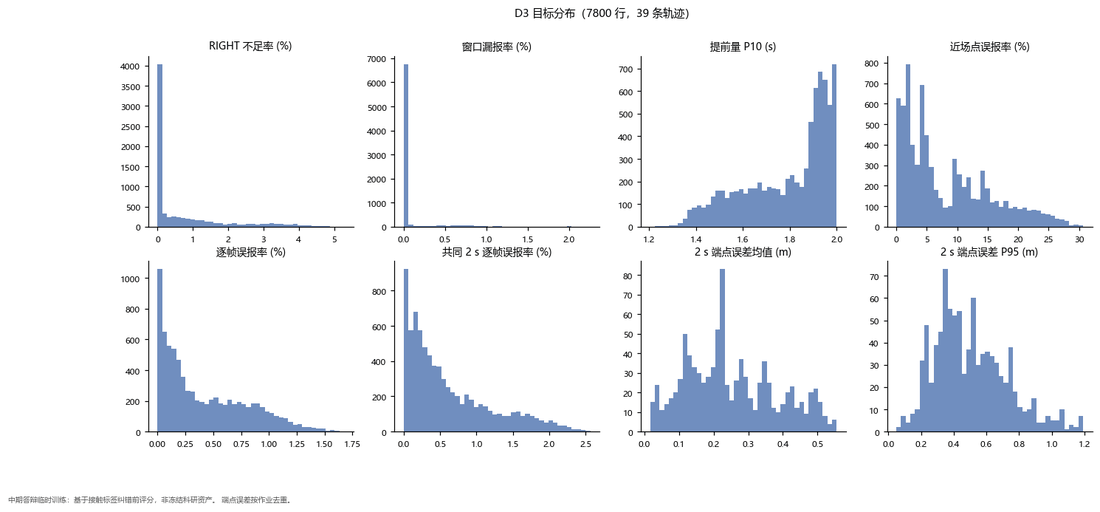

tavotoo 文件：01_数据探索\01_目标分布_D3.pdf（独立入口 01_数据探索\01_目标分布_D3.py）
原始程序：P0_数据整理/build_all.py → explore()；数据：_data/D3.csv


,n,中位数,P90,最大,取 0 的比例
RIGHT 不足率 (%),7800.0,0.091,2.869,5.282,0.401
窗口漏报率 (%),7800.0,0.000,0.434,2.261,0.814
提前量 P10 (s),7800.0,1.865,1.980,2.000,0.000
近场点误报率 (%),7800.0,5.479,19.510,30.613,0.000
逐帧误报率 (%),7800.0,0.294,0.981,1.675,0.000
共同 2 s 逐帧误报率 (%),7800.0,0.425,1.561,2.566,0.000
2 s 端点误差均值 (m),936.0,0.226,0.452,0.555,0.000
2 s 端点误差 P95 (m),936.0,0.466,0.788,1.192,0.000


出现窗口漏报的行占 18.6%；误报预算达标的行占 39.6%；S1 clean 的 2 s 端点误差中位数 0.058 m


In [11]:
show("01_目标分布_D3")
display(dist_table(D["D3"]))
print(f"出现窗口漏报的行占 {D['D3'].any_window_miss.mean():.1%}；误报预算达标的行占 {D['D3'].fp_budget_pass.mean():.1%}；"
      f"S1 clean 的 2 s 端点误差中位数 {D['D1']['geom_2.0_mean'].median():.3f} m")

**读出来的结论**：40% 的评分行 RIGHT 不足率为 0，中位数只有 0.09%，P90 为 2.87%，最大 5.28%；81% 的行没有窗口漏报（出现窗口漏报的行占 18.6%）。近场误报率中位数 5.48%，P90 19.5%，最大 30.6%。2 s 端点误差（按 936 个作业）中位数 0.23 m，比 S1 clean 的 0.06 m 大得多，因为这里包含噪声和延迟条件。误报预算达标的行占 39.6%。

**用法**：了解各指标的量级和分布形状。不能用来比较方法：这里不同方法、条件、变体混在一起。

### 图 4　D3 输入之间的相关性

**图表契约**
- **结论**：除了编码上天然绑定的变量，各实验因素之间几乎不相关（全因子设计），后面可以分开估计每个因素的作用。
- **证据**：单面板：变化的输入和方法类别哑变量之间的 Spearman 相关矩阵，格子里是相关系数。
- **类型**：quantitative grid（相关矩阵）。
- **口径**：D3 全部 7,800 行；方法专属参数在不适用时记 0，所以与方法类别天然相关。

**怎么读**：红 = 正相关，蓝 = 负相关，颜色越深越强；只看非对角线。下表列出 |ρ| ≥ 0.3 的变量对。

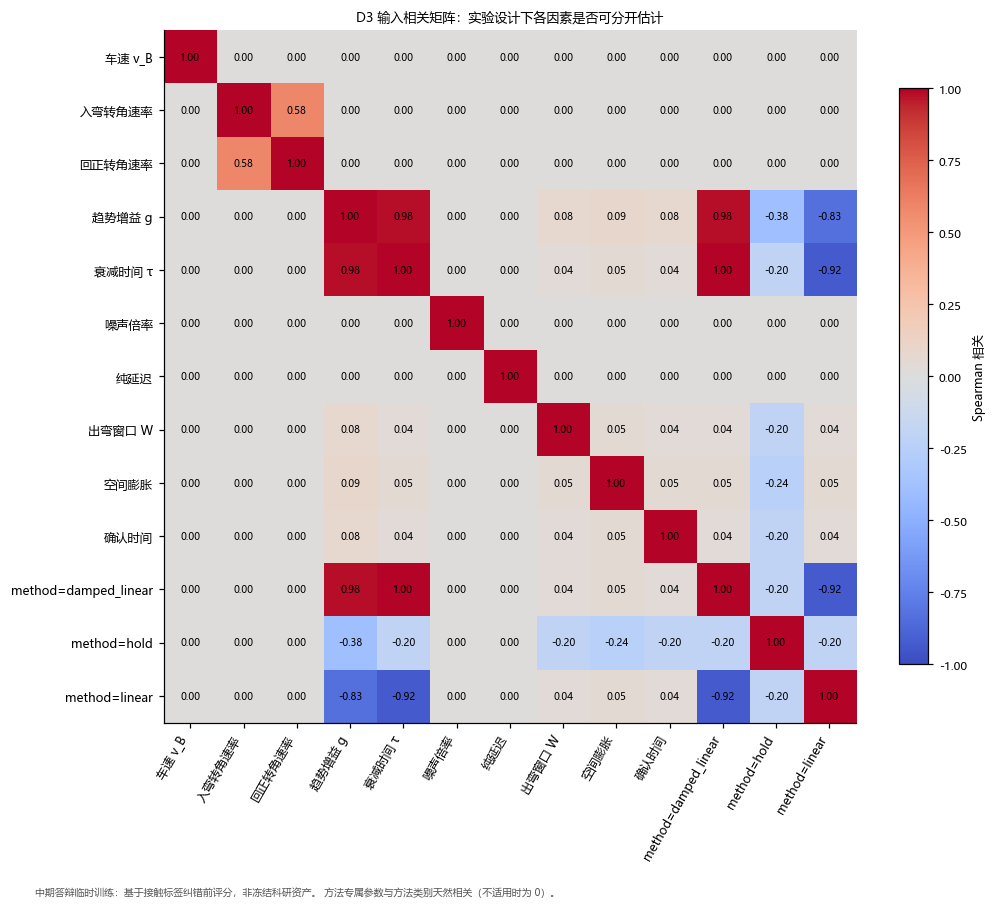

tavotoo 文件：01_数据探索\02_输入相关矩阵_D3.pdf（独立入口 01_数据探索\02_输入相关矩阵_D3.py）
原始程序：P0_数据整理/build_all.py → explore()；数据：_data/D3.csv


,变量 1,变量 2,Spearman ρ
5,衰减时间 τ,方法=damped_linear,1.00
1,趋势增益 g,衰减时间 τ,0.98
2,趋势增益 g,方法=damped_linear,0.98
6,衰减时间 τ,方法=linear,-0.92
7,方法=damped_linear,方法=linear,-0.92
4,趋势增益 g,方法=linear,-0.83
0,入弯转角速率,回正转角速率,0.58
3,趋势增益 g,方法=hold,-0.38


In [12]:
show("02_输入相关矩阵_D3")
display(strong_pairs(input_corr(D["D3"])))

**读出来的结论**：|ρ| ≥ 0.3 的变量对全部来自两种编码绑定。一是方法类别及其参数：D3 的两种方法各只有一组参数，衰减时间与“是否衰减线性”ρ = 1.00，增益与之 0.98，方法哑变量之间也天然负相关（−0.92）。二是入弯与回正转角速率（0.58）：三种模板都由同一个基准速率 r 构造。车速、噪声、延迟、出弯窗口、膨胀、确认两两之间都不到 0.3，它们的作用可以分开估计。

**用法**：说明实验设计是平衡的。方法参数之间的高相关是编码造成的，不是设计缺陷，但它意味着在 D3 里分不开“方法类别”和“参数取值”的作用（S1 和 S4 联合精化专门改变了参数）。

### 图 5　D3 输出指标之间的相关性

**图表契约**
- **结论**：迟报与误报此消彼长，所以不能把它们合成一个分数，也不存在同时最优的设置；几何误差与依赖标签的指标几乎无关。
- **证据**：单面板：8 个输出指标之间的 Spearman 相关矩阵。
- **类型**：quantitative grid（相关矩阵）。
- **口径**：D3 全部行；绝对值之间的相关，只作描述。

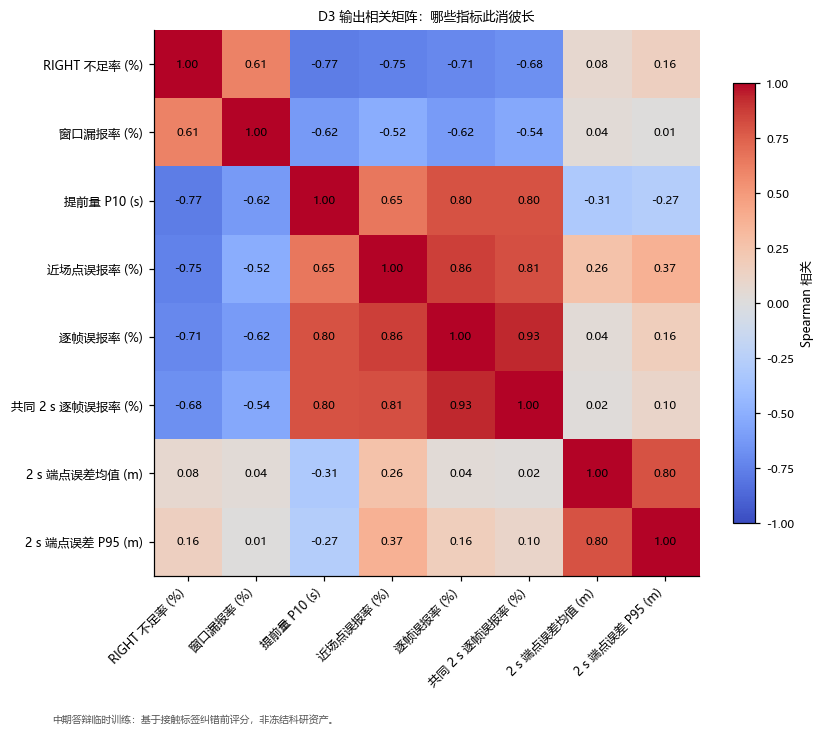

tavotoo 文件：01_数据探索\03_输出相关矩阵_D3.pdf（独立入口 01_数据探索\03_输出相关矩阵_D3.py）
原始程序：P0_数据整理/build_all.py → explore()；数据：_data/D3.csv


,指标 1,指标 2,Spearman ρ
0,RIGHT 不足率 (%),近场点误报率 (%),-0.75
1,RIGHT 不足率 (%),逐帧误报率 (%),-0.71
2,RIGHT 不足率 (%),提前量 P10 (s),-0.77
3,RIGHT 不足率 (%),窗口漏报率 (%),0.61
4,近场点误报率 (%),逐帧误报率 (%),0.86
5,2 s 端点误差均值 (m),RIGHT 不足率 (%),0.08
6,2 s 端点误差均值 (m),近场点误报率 (%),0.26


In [13]:
show("03_输出相关矩阵_D3")
c3 = output_corr(D["D3"])
display(pick_pairs(c3, [("right_pct", "negative_fp_pct"), ("right_pct", "frame_fpr_pct"), ("right_pct", "right_lead_p10_s"),
                        ("right_pct", "right_miss_rate"), ("negative_fp_pct", "frame_fpr_pct"), ("geom_2.0_mean", "right_pct"),
                        ("geom_2.0_mean", "negative_fp_pct")]))

**读出来的结论**：RIGHT 不足率与近场误报率 ρ = −0.75，与逐帧误报率 −0.71，与提前量 P10 −0.77：在 D3 里，让迟报减少的设置几乎总让误报增加。这个负相关主要来自后处理（确认时间、膨胀，见 图 7、图 13）；在没有后处理变化的 D1 里两者反而正相关（+0.67，附录 A）。2 s 端点误差与 RIGHT 不足率几乎无关（0.08）：后处理会大幅改变迟报，却不改变几何误差。

**用法**：说明为什么要同时报告迟报和误报、为什么要谈“权衡”。相关不等于因果。

### 图 6　39 条轨迹之间的相似度

**图表契约**
- **结论**：不同轨迹对同一组设置的反应高度一致，这是代理模型能推广到没见过的轨迹的前提；少数低速慢转和最难的轨迹最不典型。
- **证据**：两个面板分别按 RIGHT 不足率、近场误报率：每条轨迹用 2 方法 × 8 条件 × 12 变体 = 192 个评分组成的向量表示，两两求 Spearman 相关，按层次聚类排序。
- **类型**：quantitative grid（相似度矩阵）。
- **口径**：D3 去掉保持行；sel_ 开头的是选择集；绝对值的排序相关，只作描述。

**怎么读**：越亮越相似，对角线恒为 1；聚类把相似的轨迹排在一起。轨迹名字号很小，请看 PDF。

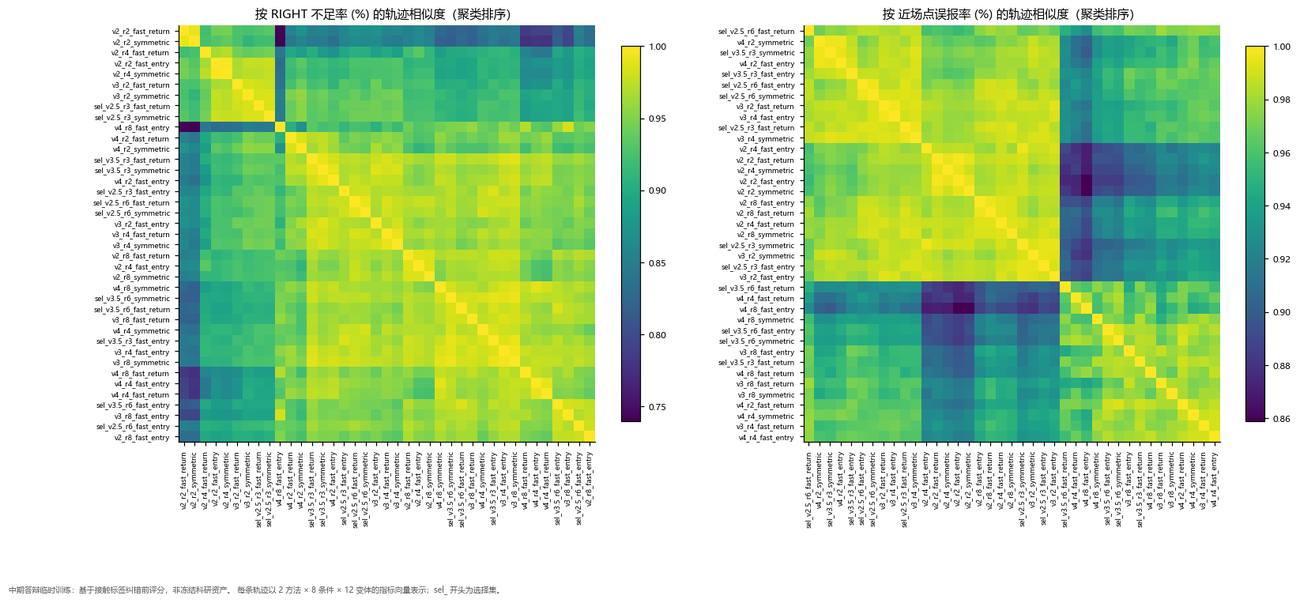

tavotoo 文件：01_数据探索\04_轨迹相似度_D3.pdf（独立入口 01_数据探索\04_轨迹相似度_D3.py）
原始程序：P0_数据整理/build_all.py → explore()；数据：_data/D3.csv
按RIGHT 不足率 (%)：两两相似度中位数 0.95，最低 0.74；最不典型 v2_r2_symmetric（0.85）、v2_r2_fast_return（0.86）、v2_r4_fast_return（0.90）、v4_r8_fast_entry（0.91）；选择集中最相似轨迹属于开发集的 2/12 条
按近场点误报率 (%)：两两相似度中位数 0.97，最低 0.86；最不典型 v4_r8_fast_entry（0.92）、v4_r4_fast_return（0.93）、sel_v3.5_r6_fast_return（0.93）、v4_r8_symmetric（0.94）；选择集中最相似轨迹属于开发集的 7/12 条


In [14]:
show("04_轨迹相似度_D3", width=1300)
sub = D["D3"][D["D3"].method != "hold"]
for t in ("right_pct", "negative_fp_pct"):
    piv = sub.pivot_table(index="case_id", columns=["config_id", "condition", "variant"], values=t)
    sim = piv.T.corr(method="spearman")
    off = sim.where(~np.eye(len(sim), dtype=bool))
    vals = off.stack()
    nn = off.idxmax()
    sel = [c for c in off.index if c.startswith("sel_")]
    least = off.mean().sort_values().head(4)
    print(f"按{target_label(t)}：两两相似度中位数 {vals.median():.2f}，最低 {vals.min():.2f}；"
          f"最不典型 " + "、".join(f"{k}（{v:.2f}）" for k, v in least.items()) +
          f"；选择集中最相似轨迹属于开发集的 {sum(not nn[c].startswith('sel_') for c in sel)}/{len(sel)} 条")

**读出来的结论**：两两相似度很高，按 RIGHT 不足率中位数 0.95（最低 0.74），按近场误报率中位数 0.97。最不典型的是低速慢转的 v2_r2 系列（迟报本来就很少，小数值的排序容易乱）和最难的 v4_r8_fast_entry（左图中最暗的一行一列）。按近场误报率，轨迹大致分成两大块：低速或慢转的一块，高速快转的一块。选择集轨迹没有单独成簇，而是按车速和转向速率穿插在开发集轨迹之间；它们最相似的轨迹常是另一条选择集轨迹（多为同车速、同速率的兄弟轨迹），最相似轨迹属于开发集的，按 RIGHT 不足率有 2/12 条，按近场误报率有 7/12 条。所以 M3 的外部检验是同一种转弯几何内部的内插。

**用法**：支持“规律在轨迹之间稳定”的说法，并提示哪些轨迹是离群的。它只覆盖同一种转弯几何内部，不说明对新路口几何的推广性。

### 图 7　各输入与迟报、误报的单因素关系

**图表契约**
- **结论**：单看每个输入，后处理的作用最大而且方向相反：确认时间抬高迟报、压低误报；膨胀压低迟报、抬高误报；噪声主要抬高误报。
- **证据**：2 行（RIGHT 不足率、近场误报率）× 8 列（车速、入弯转角速率、噪声、延迟、出弯窗口、膨胀、确认、方法）的箱线图，不画离群点。
- **类型**：quantitative grid。
- **口径**：D3 的 27 条开发轨迹，去掉保持；绝对值只作描述；每个箱子都混合了其他所有因素，是边际关系，不是因果效应。

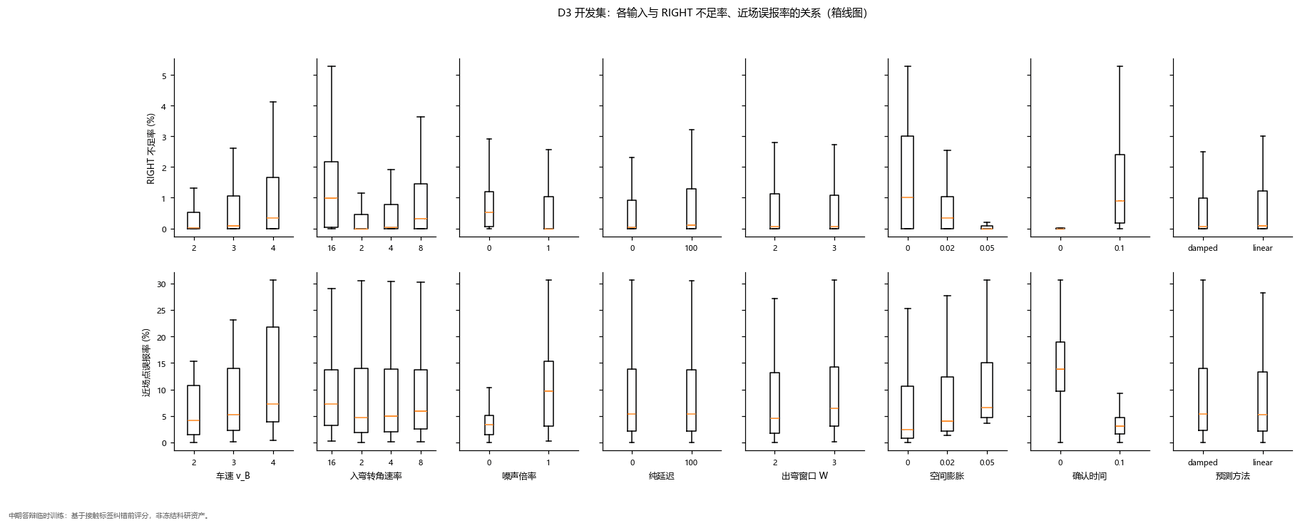

tavotoo 文件：01_数据探索\05_特征与目标关系_D3.pdf（独立入口 01_数据探索\05_特征与目标关系_D3.py）
原始程序：P0_数据整理/build_all.py → explore()；数据：_data/D3.csv


RIGHT 不足率中位数 (%)  近场误报率中位数 (%)    行数
输入     取值                                                 
车速 v_B 2.0                       0.005         4.116  1728
       3.0                       0.091         5.229  1728
       4.0                       0.330         7.329  1728
入弯转角速率 2.0                       0.000         4.663  1152
       4.0                       0.025         5.027  1728
       8.0                       0.318         5.893  1728
       16.0                      0.980         7.271   576
噪声倍率   0.0                       0.522         3.319  1296
       1.0                       0.000         9.649  3888
纯延迟    0.0                       0.040         5.370  2592
       100.0                     0.095         5.366  2592
出弯窗口 W 2.0                       0.061         4.577  2592
       3.0                       0.059         6.523  2592
空间膨胀   0.0                       0.999         2.456  1728
       0.02                      0.328         3.994  1728
       0.05                      0.000         6.600  1728
确认时间   0.0                       0.000        13.796  2592
       0.1                       0.886         3.135  2592
预测方法   damped_linear             0.050         5.447  2592
       linear                    0.077         5.302  2592

In [15]:
show("05_特征与目标关系_D3", width=1300)
dev = D["D3"][(D["D3"].partition == "development_v2_n70000") & (D["D3"].method != "hold")]
rows = []
for f in ["v_B_mps", "entry_rate_deg_s", "noise_level", "delay_ms", "EXIT_W_s", "margin_m", "confirmation_s", "method"]:
    for lvl, g in dev.groupby(f):
        rows.append({"输入": FEATURE_LABEL.get(f, f), "取值": lvl, "RIGHT 不足率中位数 (%)": g.right_pct.median(),
                     "近场误报率中位数 (%)": g.negative_fp_pct.median(), "行数": len(g)})
display(pd.DataFrame(rows).set_index(["输入", "取值"]).round(3))

**读出来的结论**（中位数，见下表）：确认 0.1 s 把 RIGHT 不足率从 0 抬到 0.89%，同时把近场误报从 13.8% 压到 3.1%；膨胀从 0 到 0.05 m 把迟报从 1.00% 压到 0，误报从 2.5% 抬到 6.6%；1 倍噪声把误报从 3.3% 抬到 9.6%，迟报反而从 0.52% 降到 0，这是噪声让预测区抖动、更早碰到目标造成的“提前”，是用误报换来的，不是改进。车速和入弯速率越高，迟报和误报都越高。出弯窗口 3 s 让误报中位数从 4.6% 升到 6.5%，迟报几乎不变。两种方法之间差别很小。

**用法**：给出各因素的方向和量级，帮助理解后面的配对分析和代理模型的重要性排序。边际中位数会混入其他因素的影响，定量比较以 图 13 的配对差为准。

## 5 仿真结果

图 8–图 15 都由 `描述性图表/make_figures.py` 直接从评分数据画出，不依赖任何模型。

### 5.1 S1：哪种转角预测方法迟报最少

S1 在 27 条开发轨迹上比较 19 个配置（clean，无后处理，v3 口径）。配置名与参数的对应如下（不适用的参数记 0）：

In [16]:
s1 = D["D1"]
CONFIG_ORDER = (["hold"] + [f"linear_g{g}" for g in ("050", "075", "100", "125", "150", "200")]
                + [f"damped_d{d}" for d in ("0125", "0250", "0500", "1000", "2000", "4000")]
                + [f"second_a{a}" for a in ("0050", "0100", "0200", "0250", "0500", "1000")])
cfg = (s1.drop_duplicates("config_id").set_index("config_id").loc[CONFIG_ORDER, ["method", "gain_eff", "decay_eff_s", "accel_eff_s"]]
       .rename(columns={"method": "方法", "gain_eff": "增益 g", "decay_eff_s": "衰减时间 τ (s)", "accel_eff_s": "二阶生效时长 T_a (s)"}))
display(cfg.T)

config_id,hold,linear_g050,linear_g075,linear_g100,linear_g125,linear_g150,linear_g200,damped_d0125,damped_d0250,damped_d0500,damped_d1000,damped_d2000,damped_d4000,second_a0050,second_a0100,second_a0200,second_a0250,second_a0500,second_a1000
方法,hold,linear,linear,linear,linear,linear,linear,damped_linear,damped_linear,damped_linear,damped_linear,damped_linear,damped_linear,bounded_second_order,bounded_second_order,bounded_second_order,bounded_second_order,bounded_second_order,bounded_second_order
增益 g,0.0,0.5,0.75,1.0,1.25,1.5,2.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
衰减时间 τ (s),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.125,0.25,0.5,1.0,2.0,4.0,0.0,0.0,0.0,0.0,0.0,0.0
二阶生效时长 T_a (s),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.05,0.1,0.2,0.25,0.5,1.0


### 图 8　各预测配置的 2 s 端点误差

**图表契约**
- **结论**：适度的趋势外推让 2 s 端点误差最小，外推过强误差反而回升；这个结论与接触标签无关。
- **证据**：单面板：19 个配置在 27 条轨迹上的 2 s 右缘端点误差均值的箱线图，颜色区分方法。
- **类型**：quantitative grid（分组分布）。
- **口径**：S1 clean；端点误差与评分版本、接触标签都无关；n = 每个配置 27 条轨迹。

**怎么读**：箱体是 27 条轨迹的四分位范围，横线是中位数，须线不含离群点，越低越好。灰 = 保持，青 = 线性，蓝 = 衰减线性，红 = 受限二阶。

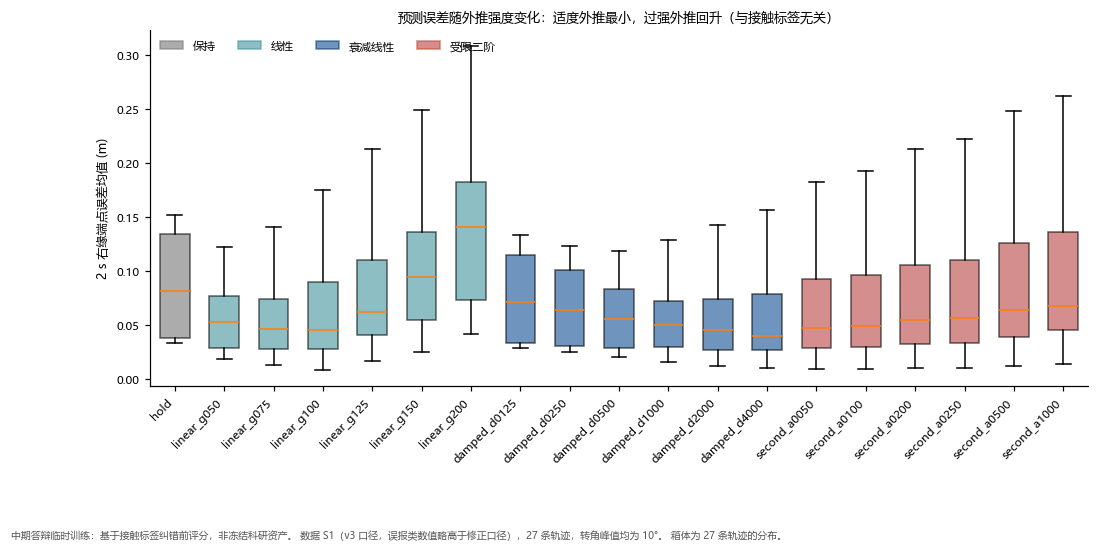

tavotoo 文件：02_描述性图表\fig01_端点误差_各配置.pdf（独立入口 02_描述性图表\fig01_端点误差_各配置.py）
原始程序：描述性图表/make_figures.py → fig01()；数据：_data/D1.csv


config_id,hold,linear_g050,linear_g075,linear_g100,linear_g125,linear_g150,linear_g200,damped_d0125,damped_d0250,damped_d0500,damped_d1000,damped_d2000,damped_d4000,second_a0050,second_a0100,second_a0200,second_a0250,second_a0500,second_a1000
均值,0.086,0.057,0.053,0.060,0.081,0.102,0.143,0.075,0.067,0.059,0.054,0.053,0.056,0.062,0.065,0.071,0.074,0.085,0.094
中位数,0.082,0.053,0.046,0.045,0.062,0.094,0.141,0.071,0.064,0.055,0.050,0.045,0.040,0.047,0.049,0.054,0.057,0.063,0.067
相对保持,0.000,-0.342,-0.380,-0.296,-0.053,0.190,0.663,-0.132,-0.219,-0.314,-0.371,-0.379,-0.354,-0.276,-0.245,-0.172,-0.138,-0.005,0.099


In [17]:
show("fig01_端点误差_各配置")
geom = s1.groupby("config_id")["geom_2.0_mean"].agg(均值="mean", 中位数="median").loc[CONFIG_ORDER]
geom["相对保持"] = geom["均值"] / geom.at["hold", "均值"] - 1
display(geom.T.round(4))

**读出来的结论**：保持的均值 0.0859 m。误差最小的是 linear_g075（0.0532 m）和 damped_d2000（0.0533 m），比保持小约 38%；衰减线性 τ = 1 s 为 0.0540 m。外推过强时误差回升：linear_g200 为 0.1428 m，second_a1000 为 0.0944 m，都比保持还大。

**用法**：这是本阶段最“干净”的证据，不受标签纠错影响，可以直接引用。但端点误差小不等于报警好，报警还取决于预测区何时覆盖目标，见 图 9、图 10。

### 图 9　与保持基线的配对迟报差

**图表契约**
- **结论**：在同一条轨迹上配对比较，几乎所有趋势外推配置在全部 27 条轨迹上都比保持迟报少。
- **证据**：单面板：18 个非保持配置的“RIGHT 不足率 − 保持”（pp）；柱为 27 条轨迹的均值，误差线为最小–最大；柱上方的数字是优于保持的轨迹数（红字表示不足 27）。
- **类型**：quantitative grid（配对差）。
- **口径**：S1 clean，v3；配对差，方向有标签区间旁证（图 15）；n = 27 条轨迹。

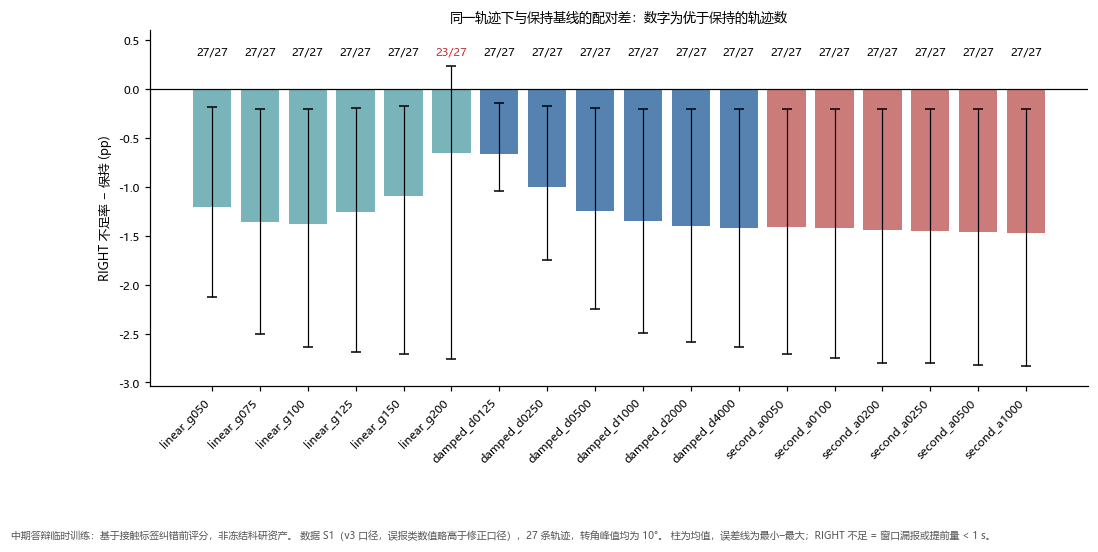

tavotoo 文件：02_描述性图表\fig02_配对迟报差_相对保持.pdf（独立入口 02_描述性图表\fig02_配对迟报差_相对保持.py）
原始程序：描述性图表/make_figures.py → fig02()；数据：_data/D1.csv


config_id,linear_g050,linear_g075,linear_g100,linear_g125,linear_g150,linear_g200,damped_d0125,damped_d0250,damped_d0500,damped_d1000,damped_d2000,damped_d4000,second_a0050,second_a0100,second_a0200,second_a0250,second_a0500,second_a1000
均值 (pp),-1.205,-1.365,-1.380,-1.261,-1.096,-0.657,-0.671,-1.005,-1.248,-1.356,-1.405,-1.420,-1.408,-1.421,-1.443,-1.449,-1.461,-1.469
最小,-2.131,-2.505,-2.639,-2.684,-2.704,-2.764,-1.048,-1.751,-2.250,-2.495,-2.585,-2.634,-2.704,-2.749,-2.799,-2.799,-2.824,-2.834
最大,-0.191,-0.209,-0.209,-0.199,-0.177,0.237,-0.147,-0.173,-0.196,-0.209,-0.209,-0.209,-0.209,-0.209,-0.209,-0.209,-0.209,-0.209
优于保持的轨迹数,27.000,27.000,27.000,27.000,27.000,23.000,27.000,27.000,27.000,27.000,27.000,27.000,27.000,27.000,27.000,27.000,27.000,27.000


In [18]:
show("fig02_配对迟报差_相对保持")
d = s1[s1.method != "hold"]
g = d.groupby("config_id")["d_hold_right_pct"]
pair = pd.DataFrame({"均值 (pp)": g.mean(), "最小": g.min(), "最大": g.max(),
                     "优于保持的轨迹数": g.apply(lambda x: int((x < 0).sum()))}).loc[CONFIG_ORDER[1:]]
display(pair.T.round(3))

**读出来的结论**：17 个配置在 27/27 条轨迹上都优于保持，唯一的例外是外推最强的 linear_g200（23/27）。平均降低 0.66–1.47 pp：最多的是 second_a1000（−1.47 pp），衰减线性 τ = 1 s 为 −1.36 pp，最少的是 linear_g200（−0.66 pp）和 damped_d0125（−0.67 pp）。

**用法**：本阶段的核心结论“趋势外推减少迟报”主要依据这张图（配对差、逐轨迹一致）。数值是 v3 口径、纠错前标签下的；方向稳健，具体 pp 数纠错后可能变化。

### 图 10　迟报与误报的权衡

**图表契约**
- **结论**：适度外推在迟报和误报两方面都优于保持；但在外推配置之间迟报与误报此消彼长，没有同时最优的配置。
- **证据**：单面板：19 个配置的 RIGHT 不足率均值（纵轴）对近场误报率均值（横轴），同一方法沿参数增大连线，部分配置标了名字。
- **类型**：quantitative grid（权衡散点）。
- **口径**：S1 clean，v3 口径（误报数值略高于修正口径）；绝对值只作描述；每个点是 27 条轨迹的平均。

**怎么读**：越靠左下越好。

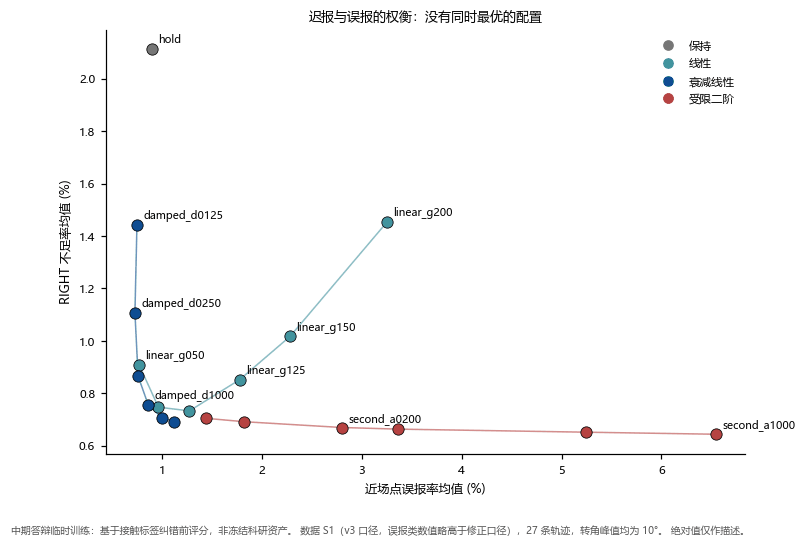

tavotoo 文件：02_描述性图表\fig03_迟报误报权衡.pdf（独立入口 02_描述性图表\fig03_迟报误报权衡.py）
原始程序：描述性图表/make_figures.py → fig03()；数据：_data/D1.csv


config_id,hold,linear_g050,linear_g075,linear_g100,linear_g125,linear_g150,linear_g200,damped_d0125,damped_d0250,damped_d0500,damped_d1000,damped_d2000,damped_d4000,second_a0050,second_a0100,second_a0200,second_a0250,second_a0500,second_a1000
RIGHT 不足率 (%),2.112,0.908,0.747,0.733,0.852,1.017,1.455,1.442,1.107,0.865,0.756,0.707,0.692,0.704,0.691,0.669,0.663,0.651,0.644
近场误报率 (%),0.892,0.767,0.960,1.271,1.774,2.279,3.255,0.745,0.725,0.757,0.858,0.995,1.115,1.433,1.820,2.799,3.359,5.248,6.549


迟报最低： second_a1000 ；误报最低： damped_d0250


In [19]:
show("fig03_迟报误报权衡")
tr = s1.groupby("config_id").agg(**{"RIGHT 不足率 (%)": ("right_pct", "mean"), "近场误报率 (%)": ("negative_fp_pct", "mean")}).loc[CONFIG_ORDER]
display(tr.T.round(3))
print("迟报最低：", tr["RIGHT 不足率 (%)"].idxmin(), "；误报最低：", tr["近场误报率 (%)"].idxmin())

**读出来的结论**：保持的 RIGHT 不足率 2.11%、近场误报 0.89%。适度外推两方面都更好，例如衰减线性 τ = 1 s 为 0.76% / 0.86%，线性 g = 0.5 为 0.91% / 0.77%。外推配置之间则此消彼长：迟报最低的 second_a1000（0.64%）误报升到 6.55%；误报最低的 damped_d0250（0.73%）迟报为 1.11%；外推过强的 linear_g200 两头都差（1.46% / 3.26%）。后续阶段保留了线性 g = 0.5 和衰减线性 τ = 1 s 两种方法。

**用法**：说明为什么不选“迟报最低”的配置：受限二阶的长生效时长用很高的误报换来很小的迟报改进。绝对数值只作描述。

### 图 11　趋势外推的收益随车速和转向速率的变化

**图表契约**
- **结论**：趋势外推的收益随车速和转向速率增大而增大：越快、越急的转弯越需要预测转角趋势。
- **证据**：3 个面板（对称、较快入弯、较快回正），每个面板是车速 × 基准转角速率的 3 × 3 热图，格子里是“衰减线性 τ=1 s − 保持”的 RIGHT 不足率配对差（pp）。
- **类型**：quantitative grid（热图）。
- **口径**：S1 clean，v3；配对差；每格 1 条轨迹。

**怎么读**：越负（绿色越深）收益越大。

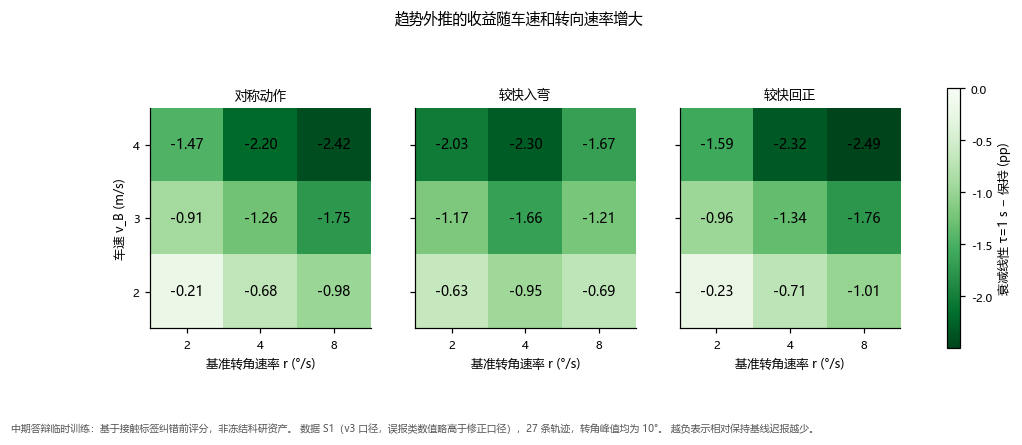

tavotoo 文件：02_描述性图表\fig04_驾驶因素_配对收益热图.pdf（独立入口 02_描述性图表\fig04_驾驶因素_配对收益热图.py）
原始程序：描述性图表/make_figures.py → fig04()；数据：_data/D1.csv


base_rate_deg_s        2.0    4.0    8.0
template    v_B_mps                     
fast_entry  2.0     -0.635 -0.954 -0.695
            3.0     -1.174 -1.661 -1.212
            4.0     -2.029 -2.305 -1.669
fast_return 2.0     -0.226 -0.710 -1.008
            3.0     -0.959 -1.335 -1.763
            4.0     -1.586 -2.323 -2.495
symmetric   2.0     -0.209 -0.682 -0.981
            3.0     -0.908 -1.260 -1.748
            4.0     -1.468 -2.195 -2.416

收益最小：v2_r2_symmetric（-0.209 pp）；收益最大：v4_r8_fast_return（-2.495 pp）


In [20]:
show("fig04_驾驶因素_配对收益热图")
dd = s1[s1.config_id == "damped_d1000"]
piv = dd.pivot_table(index=["template", "v_B_mps"], columns="base_rate_deg_s", values="d_hold_right_pct")
display(piv.round(3))
lo, hi = dd.loc[dd.d_hold_right_pct.idxmax()], dd.loc[dd.d_hold_right_pct.idxmin()]
print(f"收益最小：{lo.case_id}（{lo.d_hold_right_pct:+.3f} pp）；收益最大：{hi.case_id}（{hi.d_hold_right_pct:+.3f} pp）")

**读出来的结论**：27 格全部为负。收益最小的是 −0.21 pp（v = 2 m/s、r = 2°/s、对称），最大的是 −2.50 pp（v = 4 m/s、r = 8°/s、较快回正）。同一模板内，车速和转向速率越大收益越大（较快入弯在 r = 8°/s 时略有回落）。代理模型 M1 也把车速排为这个配对差最重要的输入（图 20）。

**用法**：说明在哪些工况下方法最有价值。每格只有 1 条轨迹，单格数值不宜过度解读，看整体趋势。

### 5.2 S2 与 S4 状态估计：噪声、延迟会把结论改变多少

### 图 12　噪声、延迟与状态估计

**图表契约**
- **结论**：观测噪声主要推高误报，纯延迟主要推高迟报；α 低通能减轻噪声误报；φ 状态估计（EKF）能把误报降一半以上，但会带来窗口漏报。
- **证据**：a S2 噪声倍率 → 近场误报率（三种预处理，阴影为最小–最大，红色虚线为 5% 研究预算）；b S2 纯延迟 → RIGHT 不足率；c S4 四种状态估计的近场误报率（蓝柱）与窗口漏报率（红柱，右轴），红字为出现窗口漏报的评分行数。
- **类型**：quantitative grid（三面板）。
- **口径**：a、b 为 S2，v3 口径，6 条轨迹 × 3 方法，噪声各 3 个种子；c 为 S4 状态估计，修正口径，同 6 条轨迹 × 3 方法 × 8 条件。绝对值只作描述；a 与 c 的口径不同，误报数值不能直接比。

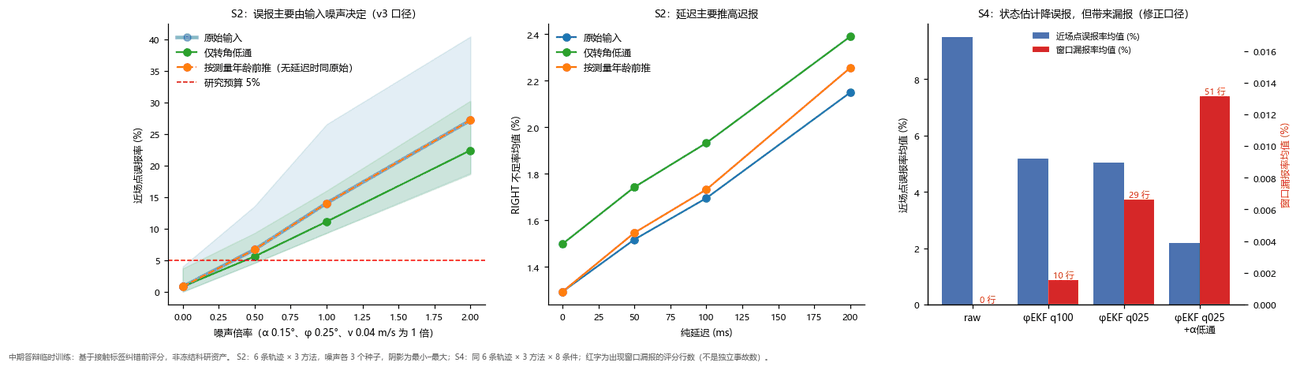

tavotoo 文件：02_描述性图表\fig05_噪声延迟与状态估计.pdf（独立入口 02_描述性图表\fig05_噪声延迟与状态估计.py）
原始程序：描述性图表/make_figures.py → fig05()；数据：_data/D2.csv、D4.csv
a  S2 近场误报率 (%)，无延迟：


noise_level,0.0,0.5,1.0,2.0
processor,,,,
age_hold,0.851,6.729,14.068,27.201
alpha_lp,0.857,5.637,11.145,22.439
raw,0.851,6.729,14.068,27.201


b  S2 RIGHT 不足率 (%)，无噪声：


delay_ms,0.0,50.0,100.0,200.0
processor,,,,
age_hold,1.293,1.546,1.732,2.255
alpha_lp,1.498,1.742,1.932,2.390
raw,1.293,1.517,1.695,2.149


S2 出现窗口漏报的行：


,case_id,condition,processor,config_id
470,v3_r4_fast_entry,delay200,age_hold,damped_d1000
517,v3_r4_fast_entry,delay200,alpha_lp,linear_g050
518,v3_r4_fast_entry,delay200,age_hold,linear_g050
564,v3_r4_fast_entry,delay200,raw,hold
565,v3_r4_fast_entry,delay200,alpha_lp,hold
566,v3_r4_fast_entry,delay200,age_hold,hold


c  S4 状态估计：


,近场误报率均值 (%),窗口漏报率均值 (%),出现窗口漏报的行,行数
processor,,,,
raw,9.494,0.000,0,144
phi_ekf_q100,5.183,0.002,10,144
phi_ekf_q025,5.049,0.007,29,144
phi_ekf_q025_alphaLP050,2.194,0.013,51,144


In [21]:
show("fig05_噪声延迟与状态估计", width=1300)
s2, s4p = D["D2"], D["D4"]
print("a  S2 近场误报率 (%)，无延迟：")
display(s2[s2.delay_ms == 0].groupby(["processor", "noise_level"])["negative_fp_pct"].mean().unstack().round(3))
print("b  S2 RIGHT 不足率 (%)，无噪声：")
display(s2[s2.noise_level == 0].groupby(["processor", "delay_ms"])["right_pct"].mean().unstack().round(3))
print("S2 出现窗口漏报的行：")
display(s2[s2.any_window_miss > 0][["case_id", "condition", "processor", "config_id"]])
print("c  S4 状态估计：")
order = ["raw", "phi_ekf_q100", "phi_ekf_q025", "phi_ekf_q025_alphaLP050"]
display(s4p.groupby("processor").agg(**{"近场误报率均值 (%)": ("negative_fp_pct", "mean"), "窗口漏报率均值 (%)": ("right_miss_rate", "mean"),
                                        "出现窗口漏报的行": ("any_window_miss", "sum"), "行数": ("any_window_miss", "size")}).reindex(order).round(3))

**读出来的结论**：a：raw 的近场误报率在噪声 0 / 0.5 / 1 / 2 倍时为 0.85 / 6.73 / 14.07 / 27.20%，0.5 倍噪声就已超过 5% 预算；α 低通降到 0.86 / 5.64 / 11.15 / 22.44%（无延迟时“按测量年龄前推”与 raw 完全相同）。b：raw 的 RIGHT 不足率在延迟 0 / 50 / 100 / 200 ms 时为 1.29 / 1.52 / 1.70 / 2.15%；α 低通的代价是迟报略增（无延迟时 1.50%）。S2 中出现窗口漏报的只有 6 行，全是 v3_r4_fast_entry 在 200 ms 延迟下。c：近场误报率 raw 9.49% → φEKF q100 5.18%、q025 5.05%、q025 + α 低通 2.19%，但出现窗口漏报的行从 0 增到 10 / 29 / 51 行（每种处理各 144 行）。

**用法**：说明真实传感器条件下的主要矛盾在误报，以及状态估计“降误报换漏报”的代价。结论来自 6 条轨迹，稳健性有限。

### 5.3 S3：报警后处理怎样改变迟报—误报平衡

### 图 13　后处理三因素的交互

**图表契约**
- **结论**：后处理是最强的旋钮，而且各有代价：确认 0.1 s 把近场误报压低约 9 pp，但 RIGHT 不足率升高约 2.7 pp，并出现窗口漏报；膨胀 0.05 m 正好相反；两者合用接近折中；出弯窗口 3 s 只增加误报，对迟报几乎没有帮助。
- **证据**：2 行（W = 2 s / 3 s）× 4 列（RIGHT 不足率、窗口漏报率、近场误报率、共同 2 s 误报率的变化），每格是膨胀 × 确认组合相对“无后处理”的平均变化（pp）。
- **类型**：quantitative grid（热图）。
- **口径**：S3 修正口径，27 条开发轨迹 × 2 方法 × 8 观测条件求均值；配对差（相对同一作业的无后处理）；左上“参照”格恒为 0。

**怎么读**：绿色更好，红色更差（迟报、漏报、误报都是越低越好）。

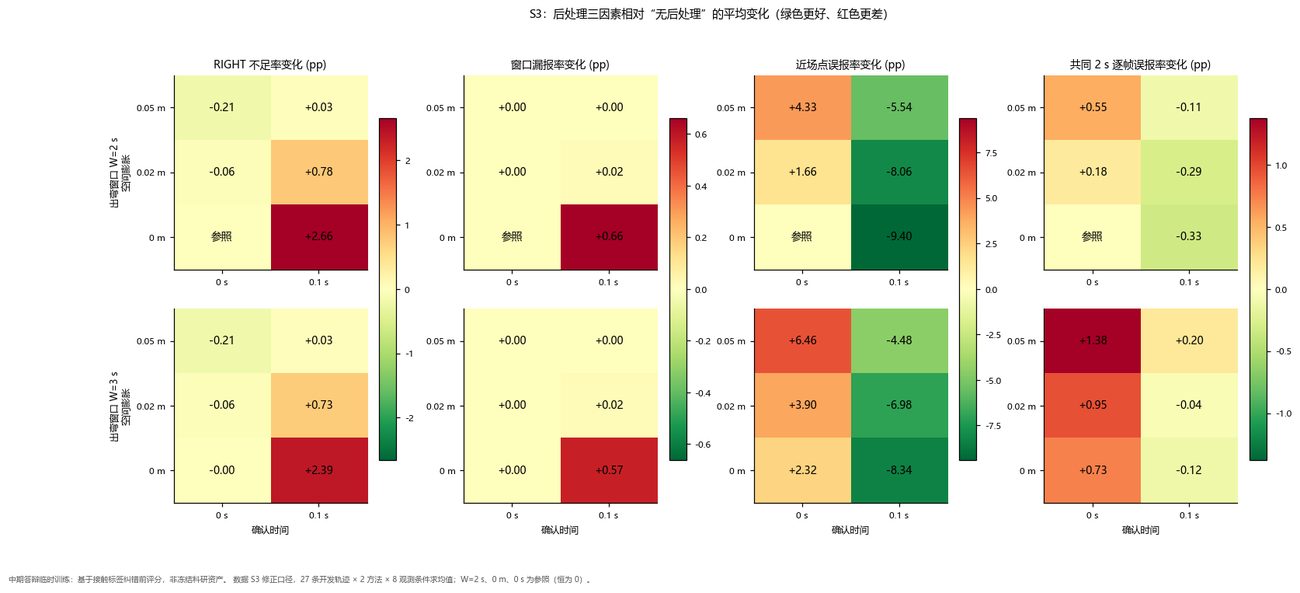

tavotoo 文件：02_描述性图表\fig06_后处理三因素交互.pdf（独立入口 02_描述性图表\fig06_后处理三因素交互.py）
原始程序：描述性图表/make_figures.py → fig06()；数据：_data/D3.csv


RIGHT 不足率  窗口漏报率  近场误报率  共同 2 s 误报率
EXIT_W_s margin_m confirmation_s                                     
2.0      0.00     0.0                   NaN    NaN    NaN         NaN
                  0.1                 2.661  0.663 -9.402      -0.331
         0.02     0.0                -0.057  0.000  1.656       0.176
                  0.1                 0.779  0.020 -8.056      -0.290
         0.05     0.0                -0.205  0.000  4.327       0.549
                  0.1                 0.032  0.000 -5.544      -0.107
3.0      0.00     0.0                -0.000  0.000  2.322       0.734
                  0.1                 2.390  0.573 -8.335      -0.118
         0.02     0.0                -0.057  0.000  3.903       0.953
                  0.1                 0.733  0.016 -6.981      -0.045
         0.05     0.0                -0.205  0.000  6.456       1.378
                  0.1                 0.029  0.000 -4.484       0.199

出现窗口漏报的行占比（行：膨胀 m；列：确认 s）：


confirmation_s,0.0,0.1
margin_m,,
0.00,0.0,0.750
0.02,0.0,0.403
0.05,0.0,0.000


In [22]:
show("fig06_后处理三因素交互", width=1300)
d3 = D["D3"]
dev = d3[(d3.partition == "development_v2_n70000") & (d3.method != "hold")]
cols = {"d_post_right_pct": "RIGHT 不足率", "d_post_right_miss_rate": "窗口漏报率",
        "d_post_negative_fp_pct": "近场误报率", "d_post_common_2s_fpr_pct": "共同 2 s 误报率"}
eff = dev.groupby(["EXIT_W_s", "margin_m", "confirmation_s"])[list(cols)].mean().rename(columns=cols)
display(eff.round(3))
print("出现窗口漏报的行占比（行：膨胀 m；列：确认 s）：")
display(dev.groupby(["margin_m", "confirmation_s"])["any_window_miss"].mean().unstack().round(3))

**读出来的结论**（下表，单位 pp）：确认 0.1 s：RIGHT 不足率 +2.66、窗口漏报 +0.66、近场误报 −9.40。膨胀 0.05 m：RIGHT −0.21、近场误报 +4.33。两者合用（W2_m0.05_c0.1）：RIGHT +0.03、近场误报 −5.54，接近折中。出弯窗口 3 s（W3_m0_c0）：RIGHT 不变、近场误报 +2.32、共同 2 s 误报 +0.73。确认 0.1 s 时出现窗口漏报的行占比随膨胀 0 / 0.02 / 0.05 m 依次为 75% / 40% / 0%；不加确认时没有窗口漏报。

**用法**：给后处理参数的选择提供依据：确认时间压误报最有效，但必须配膨胀，否则会漏报。这里是配对差，方向可信度较高。

### 5.4 S4 联合精化：细调趋势增益还有多大空间

### 图 14　趋势增益细调

**图表契约**
- **结论**：在选定方法附近细调趋势增益，迟报只变化约 0.1 pp，误报变化更大；后处理的影响远大于增益细调。
- **证据**：3 个面板（RIGHT 不足率、窗口漏报率、近场误报率）对趋势增益 g；青 = 线性，蓝 = 衰减线性；实线 / 虚线 / 点线 = 无后处理 / 膨胀 0.05 m / 确认 0.1 s；灰色水平线是保持在三种后处理下的水平。
- **类型**：quantitative grid。
- **口径**：S4 联合精化，修正口径，12 条选择轨迹 × 8 观测条件求均值；绝对值只作描述；这 12 条轨迹同时是调参数据。

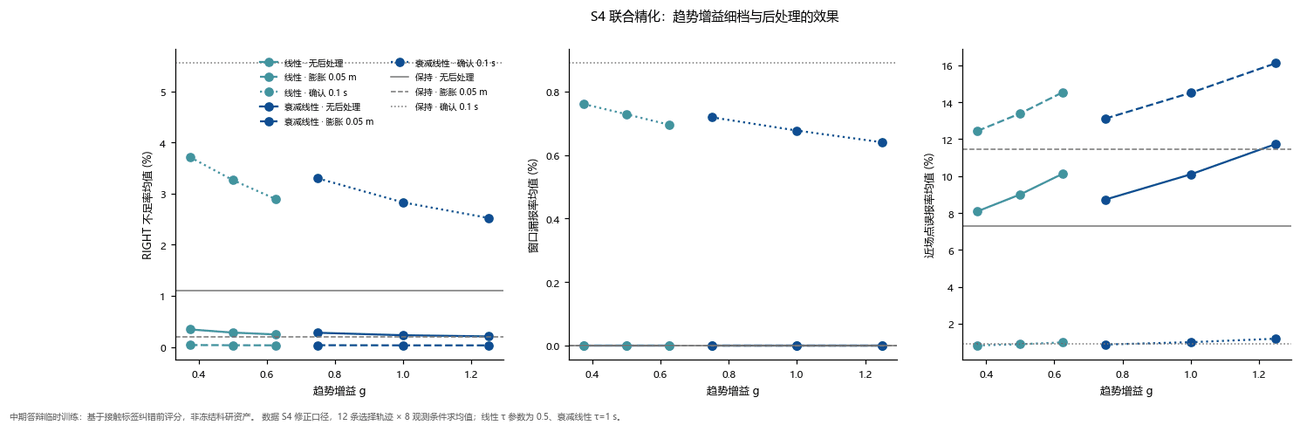

tavotoo 文件：02_描述性图表\fig07_趋势增益曲线.pdf（独立入口 02_描述性图表\fig07_趋势增益曲线.py）
原始程序：描述性图表/make_figures.py → fig07()；数据：_data/D5.csv
RIGHT 不足率 (%)：


variant,无后处理,膨胀 0.05 m,确认 0.1 s
config_id,,,
hold,1.102,0.188,5.552
linear_g0375_d0500,0.342,0.037,3.713
linear_g0500_d0500,0.281,0.033,3.265
linear_g0625_d0500,0.244,0.031,2.896
damped_linear_g0750_d1000,0.277,0.033,3.298
damped_linear_g1000_d1000,0.229,0.031,2.827
damped_linear_g1250_d1000,0.206,0.030,2.524


窗口漏报率 (%)：


variant,无后处理,膨胀 0.05 m,确认 0.1 s
config_id,,,
hold,0.0,0.0,0.889
linear_g0375_d0500,0.0,0.0,0.760
linear_g0500_d0500,0.0,0.0,0.728
linear_g0625_d0500,0.0,0.0,0.695
damped_linear_g0750_d1000,0.0,0.0,0.719
damped_linear_g1000_d1000,0.0,0.0,0.677
damped_linear_g1250_d1000,0.0,0.0,0.640


近场点误报率 (%)：


variant,无后处理,膨胀 0.05 m,确认 0.1 s
config_id,,,
hold,7.284,11.445,0.913
linear_g0375_d0500,8.092,12.453,0.816
linear_g0500_d0500,9.003,13.395,0.880
linear_g0625_d0500,10.132,14.548,0.978
damped_linear_g0750_d1000,8.726,13.120,0.864
damped_linear_g1000_d1000,10.093,14.514,0.990
damped_linear_g1250_d1000,11.741,16.124,1.180


In [23]:
show("fig07_趋势增益曲线", width=1300)
d5 = D["D5"]
names = {"W2_m0_c0": "无后处理", "W2_m0.05_c0": "膨胀 0.05 m", "W2_m0_c0.1": "确认 0.1 s"}
order = ["hold", "linear_g0375_d0500", "linear_g0500_d0500", "linear_g0625_d0500",
         "damped_linear_g0750_d1000", "damped_linear_g1000_d1000", "damped_linear_g1250_d1000"]
for col in ("right_pct", "right_miss_rate", "negative_fp_pct"):
    t = d5[d5.variant.isin(names)].groupby(["config_id", "variant"])[col].mean().unstack()[list(names)].rename(columns=names).loc[order]
    print(target_label(col) + "：")
    display(t.round(3))

**读出来的结论**：无后处理时，RIGHT 不足率线性 0.34 / 0.28 / 0.24%（g = 0.375 / 0.5 / 0.625），衰减线性 0.28 / 0.23 / 0.21%（g = 0.75 / 1 / 1.25），保持 1.10%；增益每升一档迟报只降约 0.02–0.06 pp，而近场误报升 0.9–1.7 pp（线性 8.09 / 9.00 / 10.13%，衰减线性 8.73 / 10.09 / 11.74%，保持 7.28%）。确认 0.1 s 时迟报整体升到 2.5–3.7%（保持 5.55%），误报降到约 1%；膨胀 0.05 m 时迟报约 0.03%（保持 0.19%），误报升到 12.5–16.1%（保持 11.4%）。

**用法**：说明增益不必精调，继续优化的重点在后处理与观测质量。数据只来自 12 条选择轨迹，且是调参数据本身。

### 5.5 标签不确定性会不会推翻配对结论

### 图 15　标签不确定性下的配对差区间

**图表契约**
- **结论**：在已核验的一条轨迹上，clean 和延迟 100 ms 时“趋势外推优于保持”的方向不受标签不确定性影响；加噪声后多数区间含 0 或恰为 0，方向不能确定。
- **证据**：单面板：16 个配对（8 种观测条件 × 2 种方法）的 RIGHT 不足率配对差（方法 − 保持）的上下界；绿色 = 区间全在 0 以下，灰色 = 区间含 0；区间宽度为 0 的标“恰为 0”。
- **类型**：quantitative grid（区间图）。
- **口径**：DeepSeek 正向区间评分：在接触标签不确定的范围内求配对差的上下界；只有轨迹 v2_r2_symmetric 一条、70,000 点、1,854 帧；独立核验尚未进行。

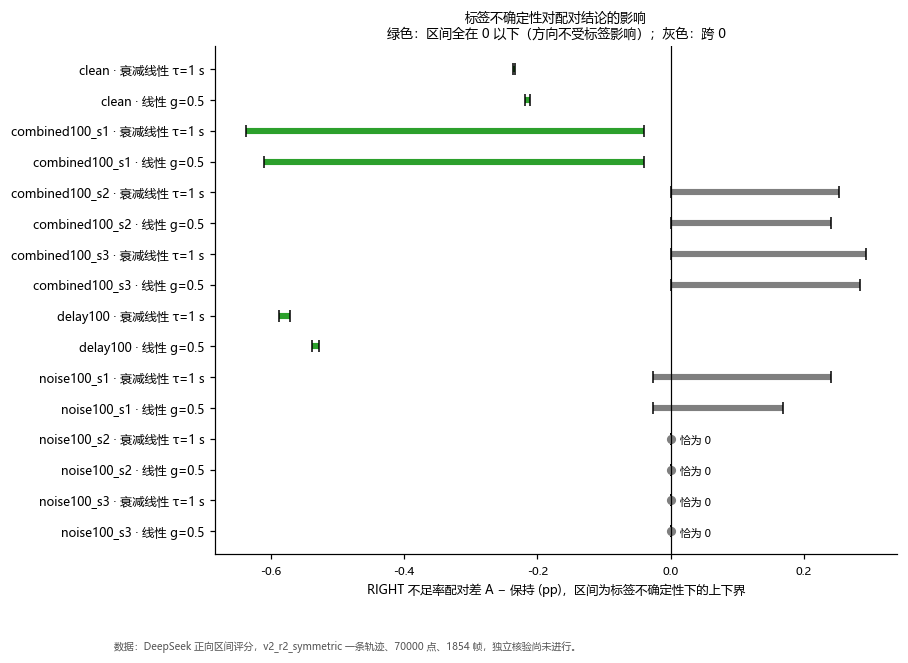

tavotoo 文件：02_描述性图表\fig12_标签区间旁证.pdf（独立入口 02_描述性图表\fig12_标签区间旁证.py）
原始程序：描述性图表/make_figures.py → fig09()；数据：_data/deepseek_paired_bounds.csv


,观测条件,方法,下界,上界,区间宽度 (pp),判读
0,clean,damped_linear_g1000_d1000,-0.236,-0.233,0.003,全在 0 以下：方向确定
1,clean,linear_g0500_d0500,-0.218,-0.211,0.007,全在 0 以下：方向确定
2,combined100_s1,damped_linear_g1000_d1000,-0.637,-0.040,0.597,全在 0 以下：方向确定
3,combined100_s1,linear_g0500_d0500,-0.610,-0.040,0.571,全在 0 以下：方向确定
4,combined100_s2,damped_linear_g1000_d1000,0.000,0.253,0.253,含 0：方向不确定
5,combined100_s2,linear_g0500_d0500,0.000,0.240,0.240,含 0：方向不确定
6,combined100_s3,damped_linear_g1000_d1000,0.000,0.293,0.293,含 0：方向不确定
7,combined100_s3,linear_g0500_d0500,0.000,0.284,0.284,含 0：方向不确定
8,delay100,damped_linear_g1000_d1000,-0.587,-0.571,0.017,全在 0 以下：方向确定
9,delay100,linear_g0500_d0500,-0.538,-0.527,0.011,全在 0 以下：方向确定


In [24]:
show("fig12_标签区间旁证")
b = pd.read_csv(DATA / "deepseek_paired_bounds.csv")
lh = b.paired_pct.str.split(r"\.\.", regex=True, expand=True).astype(float)
b["下界"], b["上界"] = lh[0], lh[1]
b["判读"] = np.select([b["上界"] < 0, (b["下界"].abs() < 1e-12) & (b["上界"].abs() < 1e-12)],
                    ["全在 0 以下：方向确定", "恰为 0"], "含 0：方向不确定")
display(b[["condition", "method_A", "下界", "上界", "paired_width_pp", "判读"]].rename(columns={"condition": "观测条件", "method_A": "方法", "paired_width_pp": "区间宽度 (pp)"}))

**读出来的结论**：clean 下两种方法的区间宽度只有 0.003 / 0.007 pp，全在 0 以下；delay100 为 −0.587..−0.571 和 −0.538..−0.527，全在 0 以下；combined100_s1 也全在 0 以下。combined100_s2/s3 下界为 0、区间含 0；noise100_s1 为 −0.027..+0.240（衰减线性）；noise100_s2/s3 恰为 0。注意 v2_r2_symmetric 是车速最低、转向最慢的轨迹，S1 中它的收益本来就最小（图 11 中最浅的一格），所以这是偏保守的旁证。

**用法**：支持“clean 与延迟条件下配对差的方向不受标签纠错影响”。噪声条件下的方向、以及其他轨迹，都还需要纠错完成后再确认。“恰为 0”不代表两种方法的报警完全相同，只表示在 RIGHT 不足这个判据上没有一个点改变归类。

## 6 代理模型：仿真里的规律能否被学出来、推广到新轨迹

### 6.1 为什么做、怎么做

每个评分行都是“一组实验设置 → 一组评分”。代理模型用设置（车速、转向速率、动作模板、方法及参数、噪声、延迟、输入处理、后处理）去预测评分，有三个用途：

1. **检验规律是否稳定**：如果连没见过的轨迹都能预测准，说明评分随设置的变化有规律，不是噪声；
2. **量化各因素的作用**：置换重要性给出排序，部分依赖给出方向；
3. **为后续实验挑选值得仿真的设置**。

代理模型只是电脑端的分析工具，不进车载预测器，也不作为安全结论。五个模型族对应五张数据表：

| 模型族 | 数据 | 任务数 | 主验证方案 | 其他验证 |
|---|---|---:|---|---|
| M1 核心预测方法 | D1：27 条开发轨迹 | 9 | 按轨迹 5 折 | 留一动作模板 |
| M2a 观测扰动与预处理 | D2：6 条轨迹 | 7 | 留一轨迹 | — |
| M2b 状态估计筛选 | D4：6 条轨迹 | 10 | 留一轨迹 | — |
| M3 二级处理联合（主模型） | D3：27 条开发轨迹训练 | 19 | 按轨迹 5 折（内层调参） | 留一动作模板、留一观测族、12 条选择轨迹外部检验 |
| M4 趋势增益精化 | D5：12 条选择轨迹 | 19 | 按轨迹 4 折 | 留一动作模板 |

- **按轨迹分组验证**：同一条轨迹的所有行要么都在训练折，要么都在测试折，模型永远在没见过的轨迹上被评估。
- **候选模型**：基线（训练折的均值或先验概率）、Ridge（分类为逻辑回归，含两两交互项）、随机森林、梯度提升。只有 M3 在主方案内做了内层分组调参。
- **skill**：相对基线的改善比例。回归 skill = 1 − MAE模型 / MAE基线，其中 MAE 先在每条轨迹内平均、再对轨迹等权平均；分类 skill = 1 − Brier模型 / Brier基线。0 表示不比“猜均值”好，1 表示完全准确。
- **临时模型表现分档**（只衡量对纠错前评分的预测能力，不是科研准入）：A 档 = 主方案 skill ≥ 0.3、R² ≥ 0.5（分类 AUC ≥ 0.75），且所有验证方案都优于基线；B 档 = 优于基线但未达 A 档；C 档 = 不优于基线。
- **乐观偏差**：主方案成绩中的“最优模型类别”是按同一组外层成绩选出来的，略偏乐观；M3 的外部检验（12 条选择轨迹不参与训练、调参、阈值选择和学习曲线，每个任务只评一次）没有这项偏差。

In [25]:
print("A 档阈值：", TIER_A, "；安全优先阈值的目标召回：", SAFETY_RECALL)
FAMILIES = ["M1_核心预测方法", "M2a_观测扰动与预处理", "M2b_状态估计筛选", "M3_二级处理联合", "M4_趋势增益精化"]
FAMS = json.loads((DATA / "families.json").read_text(encoding="utf-8"))
SEG_NAME = {"condition": "观测条件", "template": "动作模板", "variant": "后处理变体", "config_id": "配置"}


def family_overview(folder):
    """一个模型族的全部任务：最优模型、分档、各验证方案的 skill。"""
    t = load(f"{folder}/tiers")
    fam = FAMS[folder]
    tiers = " / ".join(f"{k} {v}" for k, v in t.tier.value_counts().sort_index().items())
    print(f"{fam['name']} {fam['title']}：{len(t)} 个任务，分档 {tiers}；主验证方案 {fam['main_scheme']}")
    print("口径：", fam["score_note"])
    cols = {"target_label": "目标", "label_dep": "口径", "model": "最优模型", "tier": "档", "main_skill": "主方案 skill",
            "main_R2": "R²", "main_AUC": "AUC"}
    tab = t.rename(columns=cols)[list(cols.values()) + [c for c in t.columns if c.startswith("skill[")]]
    display(tab.drop(columns=[f"skill[{fam['main_scheme']}]"]).dropna(axis=1, how="all").set_index("目标").round(3))


def family_details(folder):
    """关键任务：最重要的三个输入、残差偏度、最难预测的分段。"""
    t = load(f"{folder}/tiers").set_index("task")
    imp, seg = load(f"{folder}/permutation_importance"), load(f"{folder}/segment_errors")
    oof = load(f"{folder}/oof_best_and_baseline")
    main = FAMS[folder]["main_scheme"]
    rows = []
    for task in [x["target"] for x in FAMS[folder]["tasks"] if x["key"]]:
        s = imp[imp.task == task].sort_values("importance_mean", ascending=False).head(3)
        row = {"任务": target_label(task), "档": t.at[task, "tier"],
               "最重要的三个输入（置换后误差增加量）": "；".join(f"{a} {b:.3g}" for a, b in zip(s.label, s.importance_mean))}
        if t.at[task, "kind"] == "reg":
            o = oof[(oof.task == task) & (oof.scheme == main)]
            row["R²"] = round(t.at[task, "main_R2"], 3)
            row["残差偏度"] = round(float((o.y_true - o.y_pred).skew()), 2)
            hard = []
            for sname, label in SEG_NAME.items():
                d = seg[(seg.task == task) & (seg.segment == sname)]
                if d.value.nunique() > 1:
                    top = d.sort_values("MAE").iloc[-1]
                    hard.append(f"{label} {top.value}")
            row["MAE 最大的分段"] = "；".join(hard)
            worst = seg[(seg.task == task) & (seg.segment == "最难预测前10（轨迹×条件）")]
            row["最难预测（轨迹 | 条件）"] = worst.value.iloc[0] if len(worst) else ""
        rows.append(row)
    display(pd.DataFrame(rows).set_index("任务"))

A 档阈值： {'skill': 0.3, 'r2': 0.5, 'auc': 0.75} ；安全优先阈值的目标召回： 0.9


### 6.2 一个可复现的小例子：skill 是怎么算出来的

以 M1 的“2 s 端点误差均值”为例。先用保存的折外预测复算 skill（不需要 scikit-learn），再用同样的设置重新训练一次（需要 scikit-learn，几秒钟），检验能否得到同一个数。

In [26]:
o = load("M1_核心预测方法/oof_best_and_baseline")
o = o[(o.task == "geom_2.0_mean") & (o.scheme == "按轨迹5折")].reset_index(drop=True)


def mae_group_equal(y, p, groups):
    """先在每条轨迹内求 MAE，再对轨迹等权平均。"""
    return pd.Series(np.abs(np.asarray(y) - np.asarray(p))).groupby(np.asarray(groups)).mean().mean()


m_model, m_base = mae_group_equal(o.y_true, o.y_pred, o.case_id), mae_group_equal(o.y_true, o.y_base, o.case_id)
ref = load("M1_核心预测方法/scores")
ref = ref[(ref.task == "geom_2.0_mean") & (ref.scheme == "按轨迹5折") & (ref.model == "梯度提升")].iloc[0]
print(f"折外预测 {len(o)} 行、{o.case_id.nunique()} 条轨迹")
print(f"MAE（每轨迹等权）：梯度提升 {m_model:.5f} m，基线 {m_base:.5f} m → skill = 1 − {m_model:.5f} / {m_base:.5f} = {1 - m_model / m_base:.4f}")
print(f"scores.csv 中记录的 skill：{ref.skill:.4f}（R² {ref.R2:.3f}）")

折外预测 513 行、27 条轨迹
MAE（每轨迹等权）：梯度提升 0.00892 m，基线 0.04197 m → skill = 1 − 0.00892 / 0.04197 = 0.7874
scores.csv 中记录的 skill：0.7874（R² 0.945）


In [27]:
try:
    from sklearn.base import clone
    from sklearn.compose import ColumnTransformer
    from sklearn.dummy import DummyRegressor
    from sklearn.ensemble import GradientBoostingRegressor
    from sklearn.model_selection import GroupKFold
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import OneHotEncoder
except ImportError:
    print("没有安装 scikit-learn，跳过重新训练；上一格已用保存的折外预测复算了同一个 skill。")
else:
    num = ["v_B_mps", "entry_rate_deg_s", "return_rate_deg_s", "gain_eff", "decay_eff_s", "accel_eff_s"]   # 与 M1/train.py 相同
    cat = ["template", "method"]
    df = D["D1"].dropna(subset=["geom_2.0_mean"]).reset_index(drop=True)
    X, y, g = df[num + cat], df["geom_2.0_mean"].to_numpy(float), df["case_id"].to_numpy()
    pre = ColumnTransformer([("num", "passthrough", num), ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat)])
    models = {"基线": Pipeline([("pre", pre), ("m", DummyRegressor())]),
              "梯度提升": Pipeline([("pre", pre), ("m", GradientBoostingRegressor(n_estimators=300, max_depth=3, learning_rate=0.05,
                                                                                 subsample=0.8, random_state=20261022))])}
    pred = {k: np.full(len(df), np.nan) for k in models}
    t0 = time.time()
    for tr, te in GroupKFold(n_splits=5).split(X, y, groups=g):            # 按轨迹 5 折：测试折的轨迹不在训练折中
        for k, m in models.items():
            pred[k][te] = clone(m).fit(X.iloc[tr], y[tr]).predict(X.iloc[te])
    s = 1 - mae_group_equal(y, pred["梯度提升"], g) / mae_group_equal(y, pred["基线"], g)
    print(f"重新训练（{time.time() - t0:.1f} s）：skill = {s:.4f}；与保存的折外预测逐点一致：{np.allclose(pred['梯度提升'], o.y_pred)}")

重新训练（1.3 s）：skill = 0.7874；与保存的折外预测逐点一致：True


两种算法得到同一个 skill（约 0.79）：模型在没见过的轨迹上，把“猜均值”的误差减少了约 79%。其他任务、其他模型族的成绩都按同一个流程得到，只是输入、验证方案和候选模型不同。

### 6.3 模型图怎么读

| 图 | 看什么 | 好的样子 |
|---|---|---|
| fig01 模型对比与分档 | 每个任务三种模型在主方案下的 skill 柱；黑色记号是最优模型在其他验证方案上的 skill；横轴标签颜色 = 分档（绿 A / 橙 B / 红 C） | 柱越高越好；黑色记号与柱接近，说明换一种分组方式也站得住 |
| fig02 预测 vs 实际（折外） | 主方案下每个点都来自训练时没见过的轨迹；虚线为完美预测 | 越贴近对角线越好；成片偏离说明某类工况学不到 |
| fig03 残差诊断 | 上：残差对预测值；下：残差直方图和偏度 | 围绕 0、没有趋势；偏度大说明有少数极端工况 |
| fig04 分段误差 | 按观测条件、动作模板、后处理变体、配置分段的折外 MAE | 找出最难预测的工况 |
| fig05 置换重要性 | 打乱一个输入（橙色：一组相关输入）后误差增加多少；误差线为跨折标准差 | 只解释 A 档任务；描述模型依赖什么，不等于因果 |
| fig06 混淆矩阵 | 分类任务在默认阈值 0.5 和“安全优先”阈值下的 2 × 2 表：行 = 实际，列 = 预测 | 右下（真阳性）和左上（真阴性）大 |
| fig07 ROC / PR | ROC 曲线（含 AUC）和精确率–召回曲线 | ROC 靠左上、PR 靠右上 |
| fig08 外部检验 | 仅 M3：12 条选择轨迹上的预测 vs 实际，颜色区分轨迹 | 推广性最可信的证据 |
| fig09 学习曲线 | 每折训练用 5 / 10 / 15 / 20 / 全部轨迹时的留出误差，虚线为基线 | 变平说明再加同类轨迹收益有限 |
| fig10 部分依赖 | 其他输入保持数据分布、只改一个后处理参数时，模型预测的平均变化；最右列为膨胀 × 确认的二维图 | 描述模型学到的规律，不等于因果效应 |

“安全优先”阈值的目标是召回至少 90%（抓住至少九成正例）。阈值从不在被评估的同一批预测上选：有外部集时只用开发集折外预测确定；没有外部集时交叉拟合（每折的阈值只用其余折确定）。所以实际召回可能低于 90%，这是诚实估计的结果。

### 6.4 M1 核心预测方法

用 S1（D1：513 行、27 条开发轨迹、clean、v3 口径）训练。输入是车速、入弯 / 回正转角速率、动作模板、方法类别及参数（g、τ、T_a）。9 个任务：4 个端点误差（标签无关）、3 个相对保持的配对差、2 个绝对值。主验证按轨迹 5 折，另做留一动作模板（每次留出一种模板的 9 条轨迹）。

In [28]:
family_overview("M1_核心预测方法")
family_details("M1_核心预测方法")

M1 核心预测方法：9 个任务，分档 A 9；主验证方案 按轨迹5折
口径： 数据 S1（v3 评分口径，误报类数值略高于修正口径），27 条轨迹，转角峰值均为 10°。


,口径,最优模型,档,主方案 skill,R²,skill[留一动作模板]
目标,,,,,,
0.3 s 端点误差均值 (m),标签无关,梯度提升,A,0.859,0.979,0.832
1 s 端点误差均值 (m),标签无关,梯度提升,A,0.739,0.908,0.750
2 s 端点误差均值 (m),标签无关,梯度提升,A,0.787,0.945,0.794
2 s 端点误差 P95 (m),标签无关,Ridge,A,0.768,0.932,0.508
RIGHT 不足率 − 保持 (pp),配对差,梯度提升,A,0.732,0.879,0.752
提前量 P10 − 保持 (s),配对差,梯度提升,A,0.569,0.762,0.611
近场点误报率 − 保持 (pp),配对差,梯度提升,A,0.719,0.899,0.763
RIGHT 不足率 (%),绝对值,梯度提升,A,0.699,0.877,0.748
近场点误报率 (%),绝对值,梯度提升,A,0.696,0.883,0.728


,档,最重要的三个输入（置换后误差增加量）,R²,残差偏度,MAE 最大的分段,最难预测（轨迹 | 条件）
任务,,,,,,
2 s 端点误差均值 (m),A,车速 v_B 0.0333；[组] 方法及参数 0.0184；[组] 转向动作 0.0178,0.945,0.87,动作模板 fast_entry；配置 second_a0250,v4_r8_fast_return | clean
RIGHT 不足率 − 保持 (pp),A,车速 v_B 0.455；[组] 转向动作 0.197；[组] 方法及参数 0.161,0.879,0.15,动作模板 fast_entry；配置 linear_g200,v4_r8_fast_entry | clean
近场点误报率 − 保持 (pp),A,[组] 方法及参数 1.28；二阶生效时长 0.918；[组] 转向动作 0.641,0.899,0.39,动作模板 fast_entry；配置 second_a0250,v2_r8_fast_entry | clean
RIGHT 不足率 (%),A,车速 v_B 0.41；[组] 转向动作 0.35；入弯转角速率 0.292,0.877,0.95,动作模板 fast_entry；配置 linear_g200,v4_r8_fast_entry | clean


### 图 16　M1 模型对比与分档

- **结论**：S1 的 9 个评分任务都能从实验设置预测出来（全部 A 档），换成留一动作模板也站得住。
- **证据**：每个任务三种模型在按轨迹 5 折下的 skill；黑色菱形为最优模型在留一动作模板下的 skill。**类型**：quantitative grid。**口径**：D1、v3，开发集交叉验证，略偏乐观。

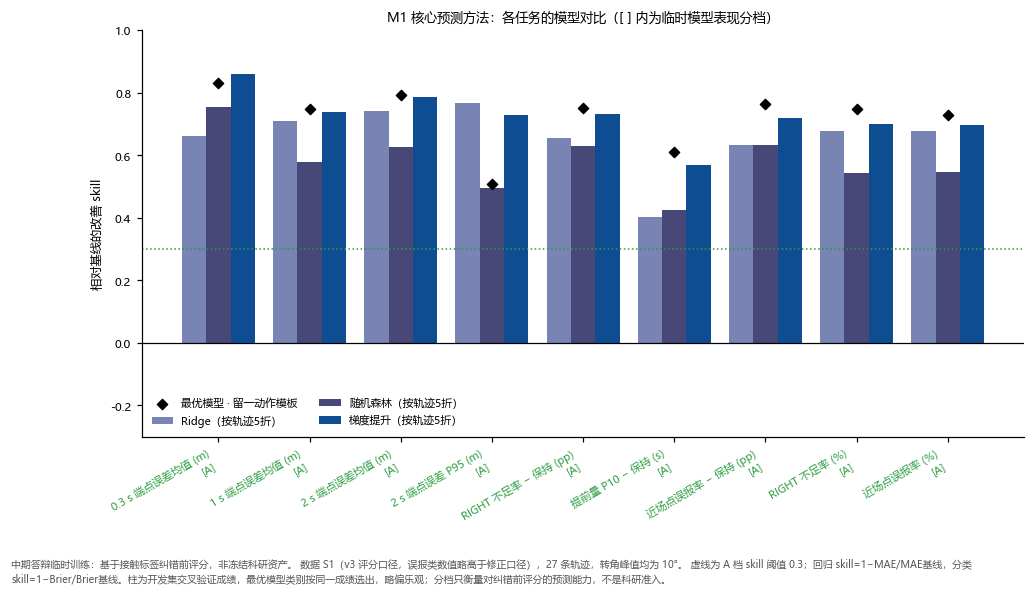

tavotoo 文件：03_M1_核心预测方法\M1__fig01_模型对比与分档.pdf（独立入口 03_M1_核心预测方法\M1__fig01_模型对比与分档.py）
原始程序：M1_核心预测方法/train.py（训练）+ common/figures.py（出图） → family_figures()；数据：_data/M1_核心预测方法/


In [29]:
show("M1__fig01_模型对比与分档")

**读出来的结论**：9 个任务全部 A 档，主方案 skill 0.57–0.86；最优模型 8 个是梯度提升，1 个是 Ridge（2 s 端点误差 P95）。留一动作模板时多数任务 skill 不降反升，只有 P95 降到 0.51：尾部误差对没见过的动作模板更敏感。

**用法**：说明 S1 的结果有规律可循。各方法的优劣以 图 9 等描述性图为准，代理模型只证明这些规律稳定。

### 图 17　M1 折外预测与仿真值

- **结论**：4 个关键任务的折外预测都紧贴对角线。
- **证据**：4 个面板依次为 2 s 端点误差、RIGHT 不足率 − 保持、近场误报率 − 保持、RIGHT 不足率；每个点是一条轨迹 × 一个配置，来自训练时没见过的轨迹。**类型**：quantitative grid。**口径**：D1，按轨迹 5 折折外预测。

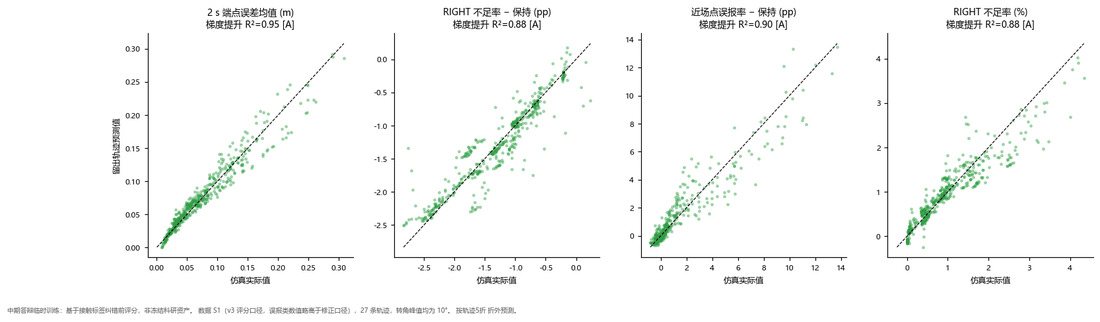

tavotoo 文件：03_M1_核心预测方法\M1__fig02_预测vs实际_折外.pdf（独立入口 03_M1_核心预测方法\M1__fig02_预测vs实际_折外.py）
原始程序：M1_核心预测方法/train.py（训练）+ common/figures.py（出图） → family_figures()；数据：_data/M1_核心预测方法/


In [30]:
show("M1__fig02_预测vs实际_折外")

**读出来的结论**：R² 依次为 0.945、0.879、0.899、0.877。偏离最大的点来自 v4_r8 等最快、最急的轨迹（见 6.4 开头表格的“最难预测”列）。

**用法**：与 fig01 的 skill 互相印证；读者可以直接看到“预测准”是什么样子。

### 图 18　M1 残差诊断

- **结论**：残差大体围绕 0，没有明显的系统偏差；右偏说明少数困难工况被低估。
- **证据**：上排为残差对预测值，下排为残差直方图（横轴标题给出偏度）。**类型**：quantitative grid。**口径**：同上。

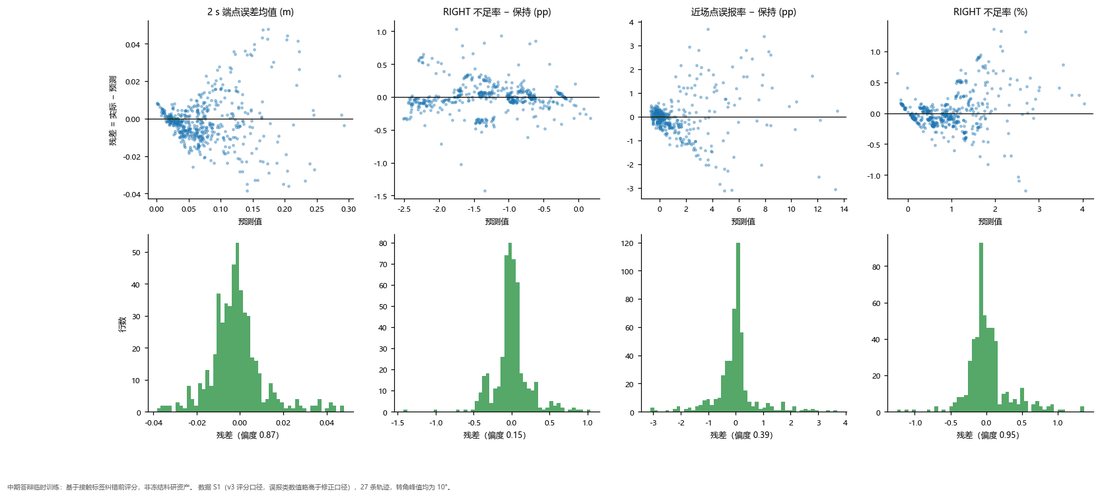

tavotoo 文件：03_M1_核心预测方法\M1__fig03_残差诊断.pdf（独立入口 03_M1_核心预测方法\M1__fig03_残差诊断.py）
原始程序：M1_核心预测方法/train.py（训练）+ common/figures.py（出图） → family_figures()；数据：_data/M1_核心预测方法/


In [31]:
show("M1__fig03_残差诊断")

**读出来的结论**：偏度在 0.15（RIGHT 不足率 − 保持）到 0.95（RIGHT 不足率）之间，都是右偏：实际值偶尔明显高于预测，即模型对个别最难的工况估计偏乐观。

**用法**：提醒读者代理模型对“最难工况”的预测偏低，用它筛选设置时要留余量。

### 图 19　M1 分段误差

- **结论**：最难预测的是较快入弯模板，以及外推最强或二阶生效时长较长的配置。
- **证据**：4 行（4 个关键任务）× 2 列（按动作模板、按配置）的折外 MAE 条形图。**类型**：quantitative grid。**口径**：同上；S1 只有 clean 一种条件、没有后处理变体，所以只有这两种分段。

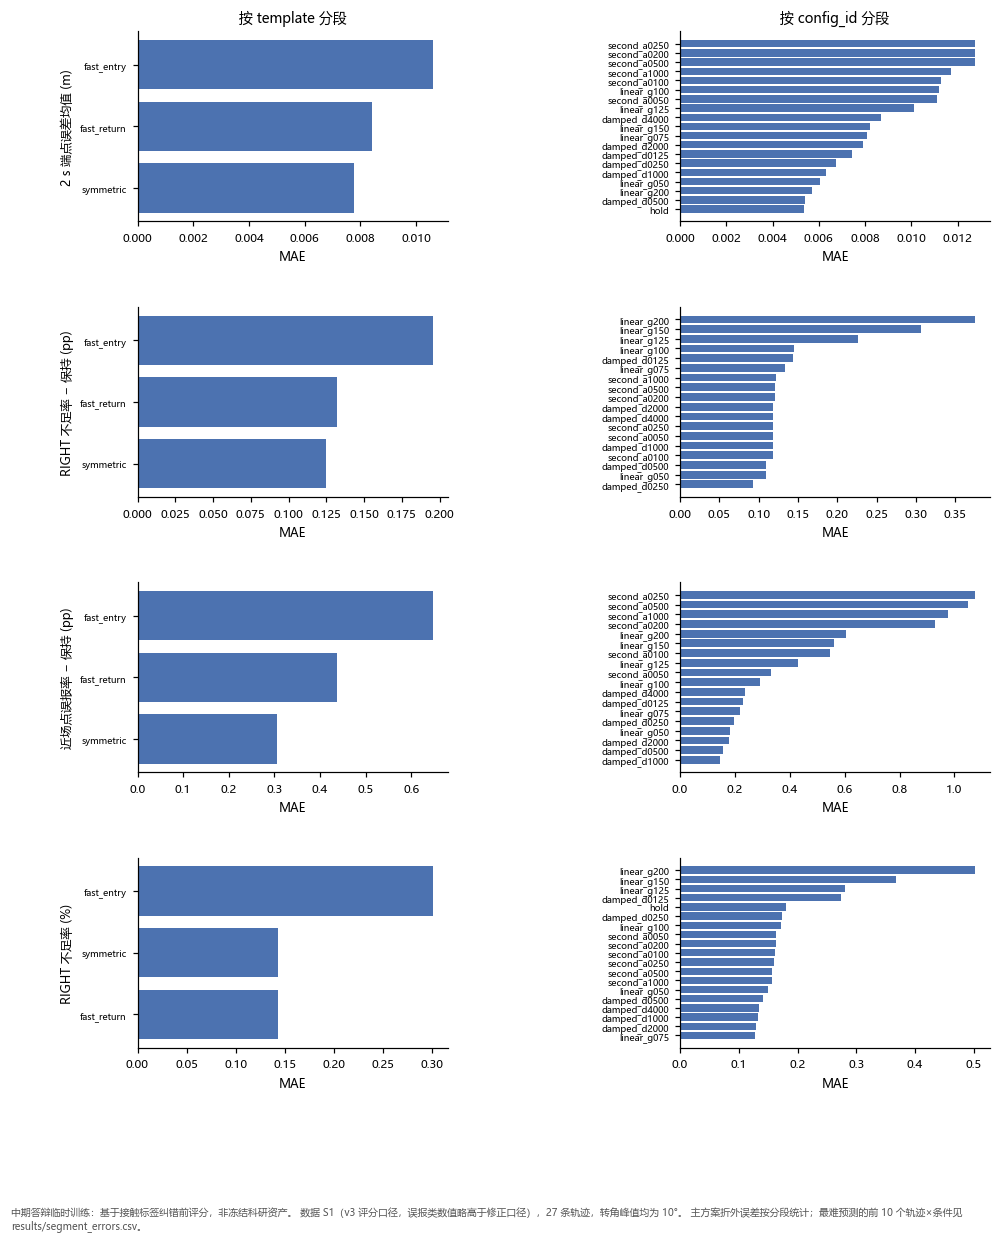

tavotoo 文件：03_M1_核心预测方法\M1__fig04_分段误差.pdf（独立入口 03_M1_核心预测方法\M1__fig04_分段误差.py）
原始程序：M1_核心预测方法/train.py（训练）+ common/figures.py（出图） → family_figures()；数据：_data/M1_核心预测方法/


In [32]:
show("M1__fig04_分段误差")

**读出来的结论**：4 个任务都是较快入弯的 MAE 最大；按配置，RIGHT 类任务误差最大的是 linear_g200，端点误差和误报差误差最大的是 second_a0250。这些正是 图 10 中偏离主趋势的配置。

**用法**：告诉读者代理模型在哪里不够准，对应的工况需要直接看仿真结果。

### 图 20　M1 置换重要性

- **结论**：车速是迟报相关任务最重要的输入；误报代价主要由方法参数决定。
- **证据**：4 个面板为 4 个关键任务，条形为打乱该输入后折外误差的增加量，橙色为成组置换，误差线为跨折标准差。**类型**：quantitative grid。**口径**：同上，4 个任务都是 A 档，可以解释。

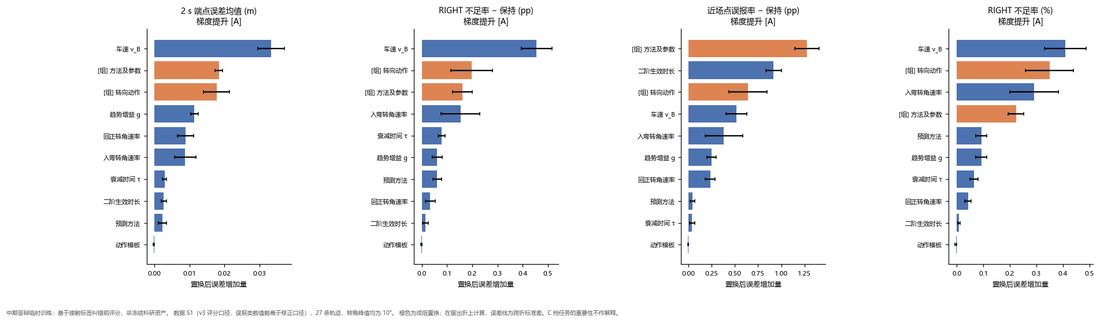

tavotoo 文件：03_M1_核心预测方法\M1__fig05_置换重要性.pdf（独立入口 03_M1_核心预测方法\M1__fig05_置换重要性.py）
原始程序：M1_核心预测方法/train.py（训练）+ common/figures.py（出图） → family_figures()；数据：_data/M1_核心预测方法/


In [33]:
show("M1__fig05_置换重要性")

**读出来的结论**：RIGHT 不足率 − 保持：车速 0.455 > 转向动作组 0.197 > 方法及参数组 0.161，与 图 11“收益随车速增大”一致。近场误报率 − 保持：方法及参数组 1.28，其中二阶生效时长 0.918，对应 图 10 中受限二阶的误报随 T_a 增大。2 s 端点误差：车速 0.033 m 最重要。

**用法**：说明“哪些因素决定方法的收益和代价”。重要性描述的是模型的依赖关系，不等于因果。

### 6.5 M2a 观测扰动与预处理

用 S2（D2：864 行、6 条代表轨迹、v3 口径）训练，输入在 M1 的基础上增加噪声倍率、纯延迟和输入处理。只有 6 条轨迹，所以用留一轨迹验证（6 折），结论的稳健性有限。

In [34]:
family_overview("M2a_观测扰动与预处理")
family_details("M2a_观测扰动与预处理")

M2a 观测扰动与预处理：7 个任务，分档 A 4 / B 3；主验证方案 留一轨迹
口径： 数据 S2（v3 评分口径），只有 6 条轨迹，结论稳健性有限。


,口径,最优模型,档,主方案 skill,R²
目标,,,,,
2 s 端点误差均值 (m),标签无关,梯度提升,A,0.693,0.900
2 s 端点误差 P95 (m),标签无关,梯度提升,B,0.309,0.346
RIGHT 不足率 (%),绝对值,随机森林,B,0.347,0.391
近场点误报率 (%),绝对值,随机森林,A,0.841,0.969
逐帧误报率 (%),绝对值,随机森林,A,0.574,0.788
RIGHT 不足率 − 保持 (pp),配对差,梯度提升,B,0.216,0.083
近场点误报率 − 保持 (pp),配对差,梯度提升,A,0.652,0.844


,档,最重要的三个输入（置换后误差增加量）,R²,残差偏度,MAE 最大的分段,最难预测（轨迹 | 条件）
任务,,,,,,
2 s 端点误差 P95 (m),B,[组] 观测扰动 0.046；噪声倍率 0.0343；纯延迟 0.019,0.346,1.11,观测条件 delay200；动作模板 fast_entry；配置 hold,v4_r8_fast_entry | delay50
近场点误报率 (%),A,噪声倍率 8.35；[组] 观测扰动 8.14；[组] 方法及参数 1.04,0.969,0.21,观测条件 noise200_s3；动作模板 fast_return；配置 damped_d1000,v4_r2_fast_return | noise200_s3
RIGHT 不足率 − 保持 (pp),B,[组] 观测扰动 0.16；噪声倍率 0.103；纯延迟 0.0269,0.083,-1.18,观测条件 combined100_s2；动作模板 fast_entry；配置 damped_d1000,v4_r8_fast_entry | combined100_s3
近场点误报率 − 保持 (pp),A,噪声倍率 2.04；[组] 观测扰动 2.04；输入处理 1.15,0.844,-0.27,观测条件 noise200_s3；动作模板 fast_return；配置 damped_d1000,v4_r2_fast_return | noise200_s3


### 图 21　M2a 模型对比与分档

- **结论**：误报类任务容易预测，迟报类任务只有 6 条轨迹时学不好。
- **证据**：7 个任务三种模型在留一轨迹下的 skill。**类型**：quantitative grid。**口径**：D2、v3。

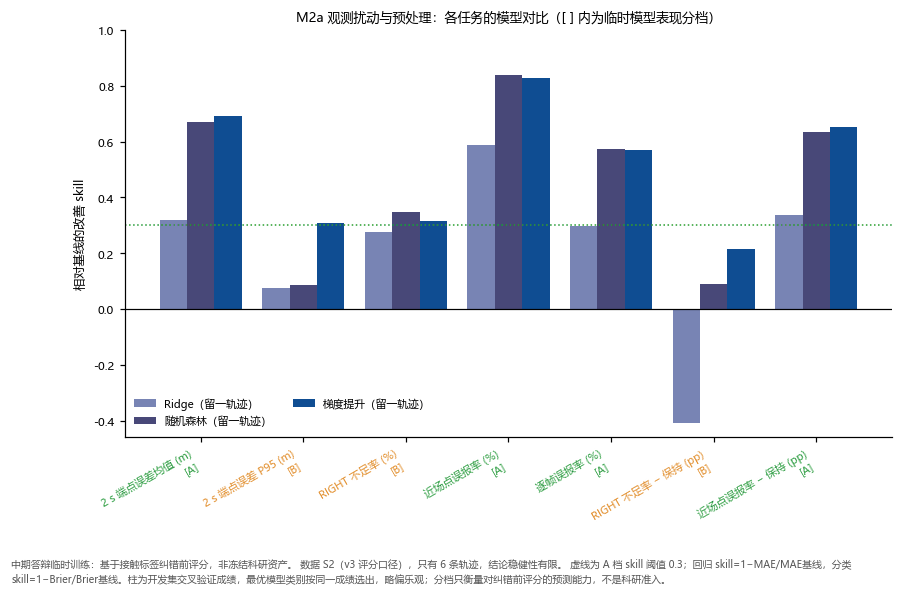

tavotoo 文件：04_M2a_观测扰动与预处理\M2a__fig01_模型对比与分档.pdf（独立入口 04_M2a_观测扰动与预处理\M2a__fig01_模型对比与分档.py）
原始程序：M2a_观测扰动与预处理/train.py（训练）+ common/figures.py（出图） → family_figures()；数据：_data/M2a_观测扰动与预处理/


In [35]:
show("M2a__fig01_模型对比与分档")

**读出来的结论**：A 4 / B 3。A 档：2 s 端点误差均值（0.69）、近场误报率（0.84）、逐帧误报率（0.57）、近场误报率 − 保持（0.65）。B 档：2 s 端点误差 P95（0.31，R² 0.35）、RIGHT 不足率（0.35，R² 0.39）、RIGHT 不足率 − 保持（0.22，R² 0.08）。误报由噪声主导，规律简单；迟报只在少数轨迹 × 条件上出现，6 条轨迹不够学。

**用法**：B 档任务的结论只看描述性图（图 12），不要引用它们的重要性或部分依赖。

### 图 22　M2a 折外预测与仿真值

- **结论**：误报类任务贴近对角线，迟报配对差和端点误差 P95 散得很开。
- **证据**：4 个面板依次为 2 s 端点误差 P95、近场误报率、RIGHT 不足率 − 保持、近场误报率 − 保持。**类型**：quantitative grid。**口径**：留一轨迹折外预测。

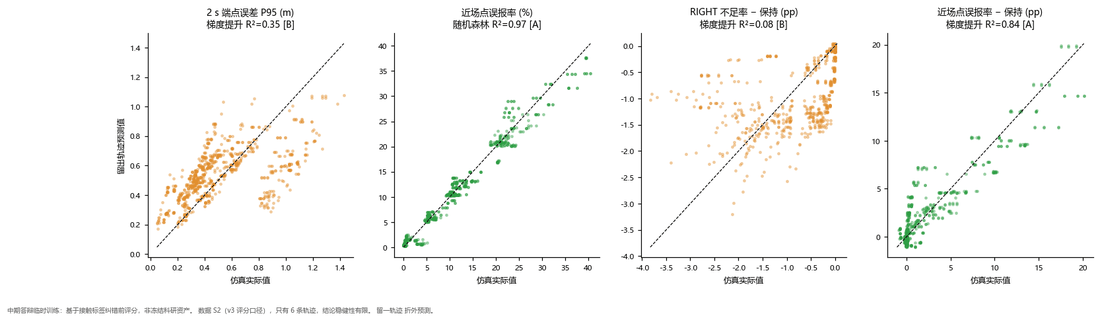

tavotoo 文件：04_M2a_观测扰动与预处理\M2a__fig02_预测vs实际_折外.pdf（独立入口 04_M2a_观测扰动与预处理\M2a__fig02_预测vs实际_折外.py）
原始程序：M2a_观测扰动与预处理/train.py（训练）+ common/figures.py（出图） → family_figures()；数据：_data/M2a_观测扰动与预处理/


In [36]:
show("M2a__fig02_预测vs实际_折外")

**读出来的结论**：R² 依次为 0.35、0.97、0.08、0.84。RIGHT 不足率 − 保持的点几乎不随实际值变化：模型基本只能给出平均水平。

**用法**：直观展示 B 档“学不好”是什么样子。

### 图 23　M2a 残差诊断

- **结论**：B 档任务的残差分布偏斜明显，说明误差集中在少数工况。
- **证据**：上排残差对预测值，下排残差直方图与偏度。**类型**：quantitative grid。**口径**：同上。

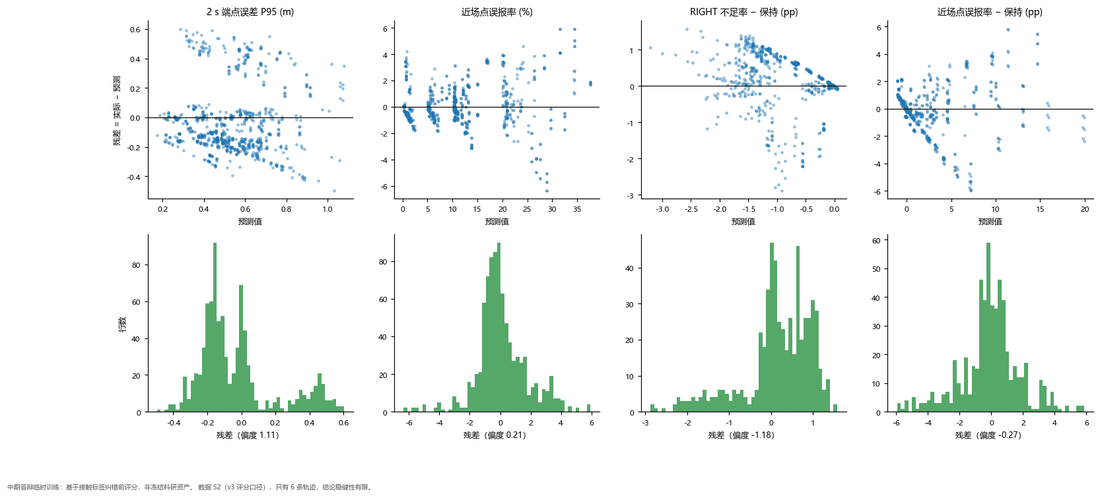

tavotoo 文件：04_M2a_观测扰动与预处理\M2a__fig03_残差诊断.pdf（独立入口 04_M2a_观测扰动与预处理\M2a__fig03_残差诊断.py）
原始程序：M2a_观测扰动与预处理/train.py（训练）+ common/figures.py（出图） → family_figures()；数据：_data/M2a_观测扰动与预处理/


In [37]:
show("M2a__fig03_残差诊断")

**读出来的结论**：端点误差 P95 的残差偏度 1.11，RIGHT 不足率 − 保持为 −1.18：前者被少数大误差拉向右，后者被少数“改善特别多”的工况拉向左。误报类任务的偏度都在 ±0.3 以内。

**用法**：与 fig02 一起说明 B 档的原因。

### 图 24　M2a 分段误差

- **结论**：最难预测的是 2 倍噪声、combined 条件和较快入弯 / 回正模板。
- **证据**：4 行 × 3 列（按观测条件、动作模板、配置）的折外 MAE。**类型**：quantitative grid。**口径**：同上。

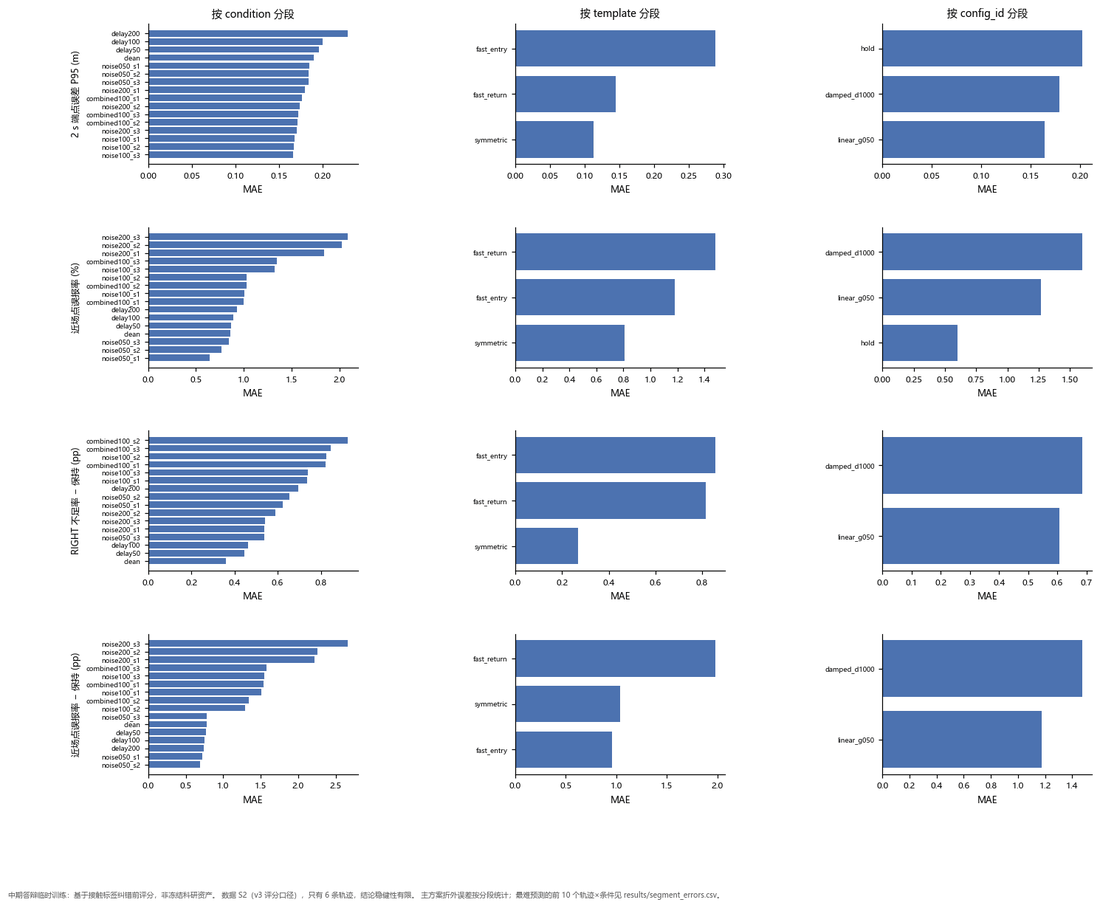

tavotoo 文件：04_M2a_观测扰动与预处理\M2a__fig04_分段误差.pdf（独立入口 04_M2a_观测扰动与预处理\M2a__fig04_分段误差.py）
原始程序：M2a_观测扰动与预处理/train.py（训练）+ common/figures.py（出图） → family_figures()；数据：_data/M2a_观测扰动与预处理/


In [38]:
show("M2a__fig04_分段误差")

**读出来的结论**：近场误报率及其配对差在 noise200_s3 上误差最大，模板以较快回正最难；RIGHT 不足率 − 保持在 combined100_s2、较快入弯上最难；端点误差 P95 在 delay200、较快入弯上最难。

**用法**：指出噪声越强、动作越急，代理模型越不可靠。

### 图 25　M2a 置换重要性

- **结论**：近场误报率几乎完全由噪声倍率决定。
- **证据**：4 个关键任务的置换重要性。**类型**：quantitative grid。**口径**：同上；B 档任务（端点误差 P95、RIGHT 不足率 − 保持）的重要性不作解释。

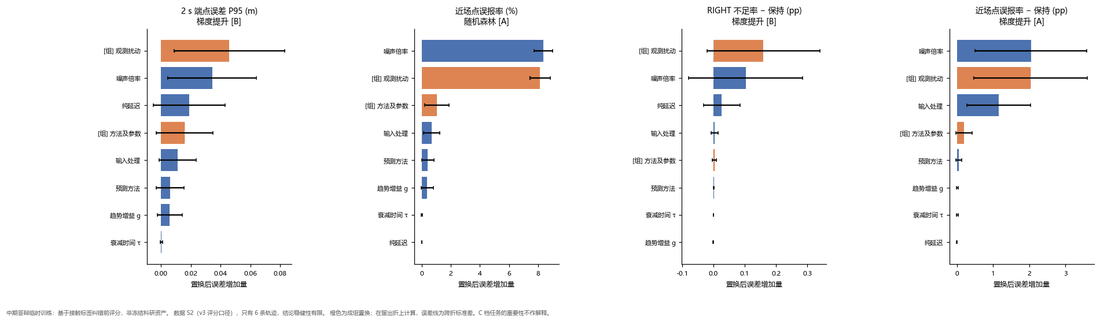

tavotoo 文件：04_M2a_观测扰动与预处理\M2a__fig05_置换重要性.pdf（独立入口 04_M2a_观测扰动与预处理\M2a__fig05_置换重要性.py）
原始程序：M2a_观测扰动与预处理/train.py（训练）+ common/figures.py（出图） → family_figures()；数据：_data/M2a_观测扰动与预处理/


In [39]:
show("M2a__fig05_置换重要性")

**读出来的结论**：近场误报率：噪声倍率 8.35（包含它的观测扰动组 8.14），其余输入都在 1.1 以下；近场误报率 − 保持：噪声 2.04、输入处理 1.15。与 图 12 a 一致：噪声是误报的主因，预处理只能部分补救。

**用法**：支持“真实传感器条件下首先要解决噪声”的说法。

### 6.6 M2b 状态估计筛选

用 S4 状态估计（D4：576 行、6 条轨迹、修正口径）训练，输入处理有 4 种：raw、φEKF q100、φEKF q025、φEKF q025 + α 低通。留一轨迹验证。

In [40]:
family_overview("M2b_状态估计筛选")
family_details("M2b_状态估计筛选")

M2b 状态估计筛选：10 个任务，分档 A 6 / B 4；主验证方案 留一轨迹
口径： 数据 S4 状态估计筛选（修正评分口径），只有 6 条轨迹，结论稳健性有限。


,口径,最优模型,档,主方案 skill,R²
目标,,,,,
2 s 端点误差均值 (m),标签无关,随机森林,A,0.636,0.827
2 s 端点误差 P95 (m),标签无关,梯度提升,B,0.119,-0.019
RIGHT 不足率 (%),绝对值,随机森林,A,0.469,0.593
窗口漏报率 (%),绝对值,随机森林,B,0.367,0.309
近场点误报率 (%),绝对值,随机森林,A,0.762,0.906
逐帧误报率 (%),绝对值,梯度提升,A,0.563,0.729
RIGHT 不足率 − 保持 (pp),配对差,随机森林,B,0.363,0.389
RIGHT 不足率 − raw (pp),配对差,随机森林,A,0.502,0.533
窗口漏报率 − raw (pp),配对差,随机森林,B,0.341,0.291


,档,最重要的三个输入（置换后误差增加量）,R²,残差偏度,MAE 最大的分段,最难预测（轨迹 | 条件）
任务,,,,,,
窗口漏报率 (%),B,[组] 方法及参数 0.00255；输入处理 0.00234；噪声倍率 0.00135,0.309,3.49,观测条件 noise100_s1；动作模板 fast_return；配置 hold,v2_r8_fast_return | noise100_s1
近场点误报率 (%),A,输入处理 2.12；噪声倍率 1.89；[组] 观测扰动 1.84,0.906,0.26,观测条件 combined100_s1；动作模板 fast_return；配置 damped_linear_g1000_d1000,v4_r2_fast_return | combined100_s1
RIGHT 不足率 − raw (pp),A,[组] 方法及参数 0.298；[组] 观测扰动 0.139；噪声倍率 0.13,0.533,-0.46,观测条件 combined100_s3；动作模板 fast_entry；配置 hold,v4_r8_fast_entry | combined100_s3
近场点误报率 − raw (pp),A,噪声倍率 2.54；[组] 观测扰动 2.38；输入处理 1.02,0.934,-0.33,观测条件 noise100_s1；动作模板 fast_return；配置 damped_linear_g1000_d1000,v4_r8_fast_entry | combined100_s2


### 图 26　M2b 模型对比与分档

- **结论**：误报和相对 raw 的变化能预测，稀有的窗口漏报和尾部量预测不好。
- **证据**：10 个任务三种模型在留一轨迹下的 skill。**类型**：quantitative grid。**口径**：D4、修正口径。

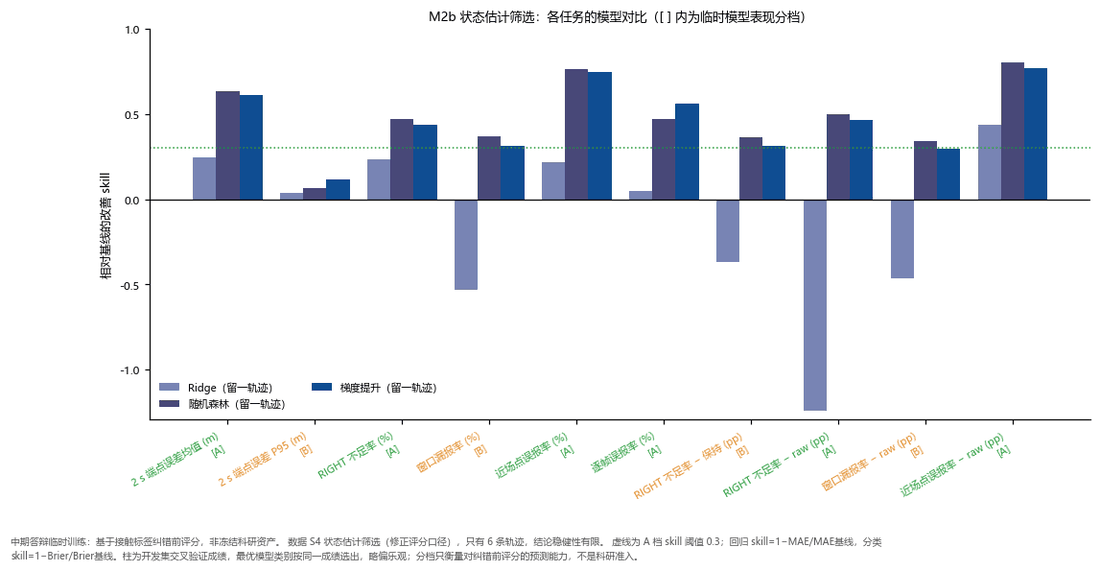

tavotoo 文件：05_M2b_状态估计筛选\M2b__fig01_模型对比与分档.pdf（独立入口 05_M2b_状态估计筛选\M2b__fig01_模型对比与分档.py）
原始程序：M2b_状态估计筛选/train.py（训练）+ common/figures.py（出图） → family_figures()；数据：_data/M2b_状态估计筛选/


In [41]:
show("M2b__fig01_模型对比与分档")

**读出来的结论**：A 6 / B 4。B 档是 2 s 端点误差 P95（0.12）、窗口漏报率（0.37）、RIGHT 不足率 − 保持（0.36）、窗口漏报率 − raw（0.34），都是只在少数行出现的稀有事件或尾部量。A 档中近场误报率 − raw 最高（0.80）。

**用法**：状态估计“降多少误报”可以引用代理模型的规律；“带来多少漏报”只看 图 12 c。

### 图 27　M2b 折外预测与仿真值

- **结论**：窗口漏报率的折外预测几乎无法区分有无漏报；误报类任务贴近对角线。
- **证据**：4 个面板依次为窗口漏报率、近场误报率、RIGHT 不足率 − raw、近场误报率 − raw。**类型**：quantitative grid。**口径**：留一轨迹折外预测。

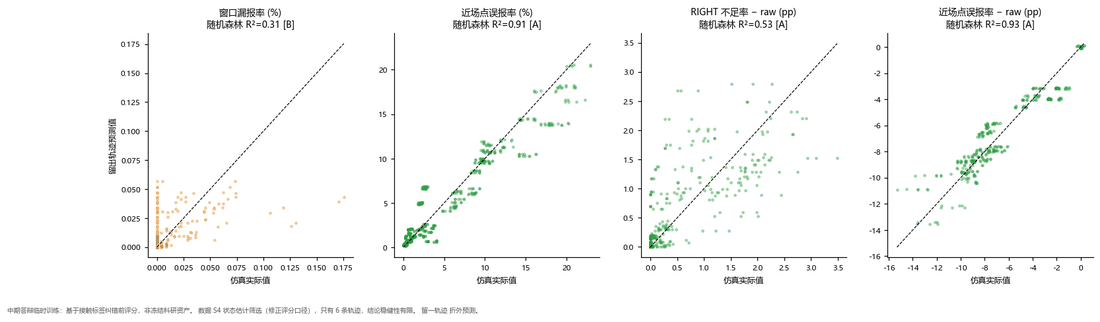

tavotoo 文件：05_M2b_状态估计筛选\M2b__fig02_预测vs实际_折外.pdf（独立入口 05_M2b_状态估计筛选\M2b__fig02_预测vs实际_折外.py）
原始程序：M2b_状态估计筛选/train.py（训练）+ common/figures.py（出图） → family_figures()；数据：_data/M2b_状态估计筛选/


In [42]:
show("M2b__fig02_预测vs实际_折外")

**读出来的结论**：R² 依次为 0.31、0.91、0.53、0.93。窗口漏报率的实际值大多为 0，少数非零值预测不到。

**用法**：说明稀有事件需要更多轨迹才能学。

### 图 28　M2b 残差诊断

- **结论**：窗口漏报率的残差极度右偏。
- **证据**：上排残差对预测值，下排残差直方图与偏度。**类型**：quantitative grid。**口径**：同上。

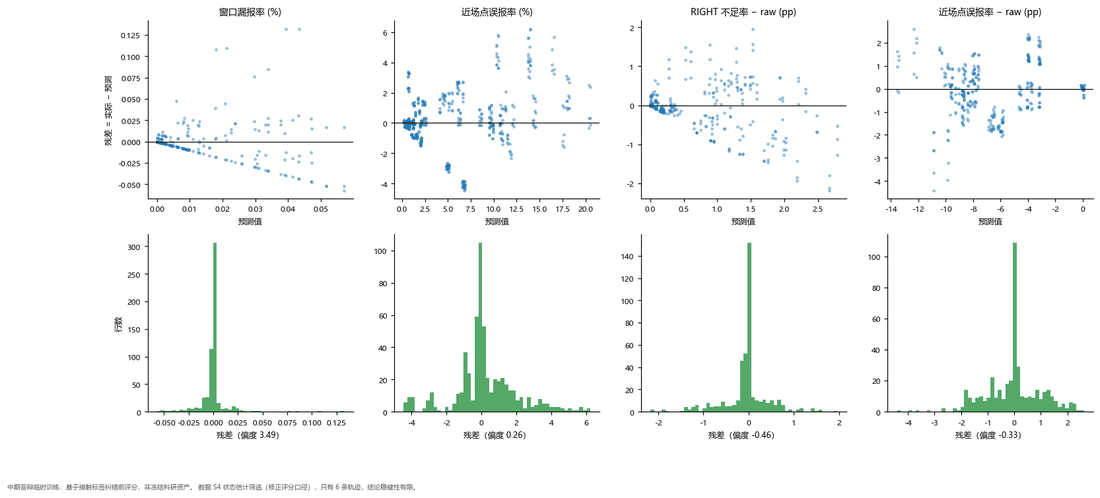

tavotoo 文件：05_M2b_状态估计筛选\M2b__fig03_残差诊断.pdf（独立入口 05_M2b_状态估计筛选\M2b__fig03_残差诊断.py）
原始程序：M2b_状态估计筛选/train.py（训练）+ common/figures.py（出图） → family_figures()；数据：_data/M2b_状态估计筛选/


In [43]:
show("M2b__fig03_残差诊断")

**读出来的结论**：窗口漏报率的残差偏度 3.49：绝大多数行误差接近 0，少数漏报行误差很大。其余三个任务偏度在 ±0.5 以内。

**用法**：同 fig02。

### 图 29　M2b 分段误差

- **结论**：误差集中在带噪声的条件和较快回正模板上。
- **证据**：4 行 × 3 列（按观测条件、动作模板、配置）的折外 MAE。**类型**：quantitative grid。**口径**：同上。

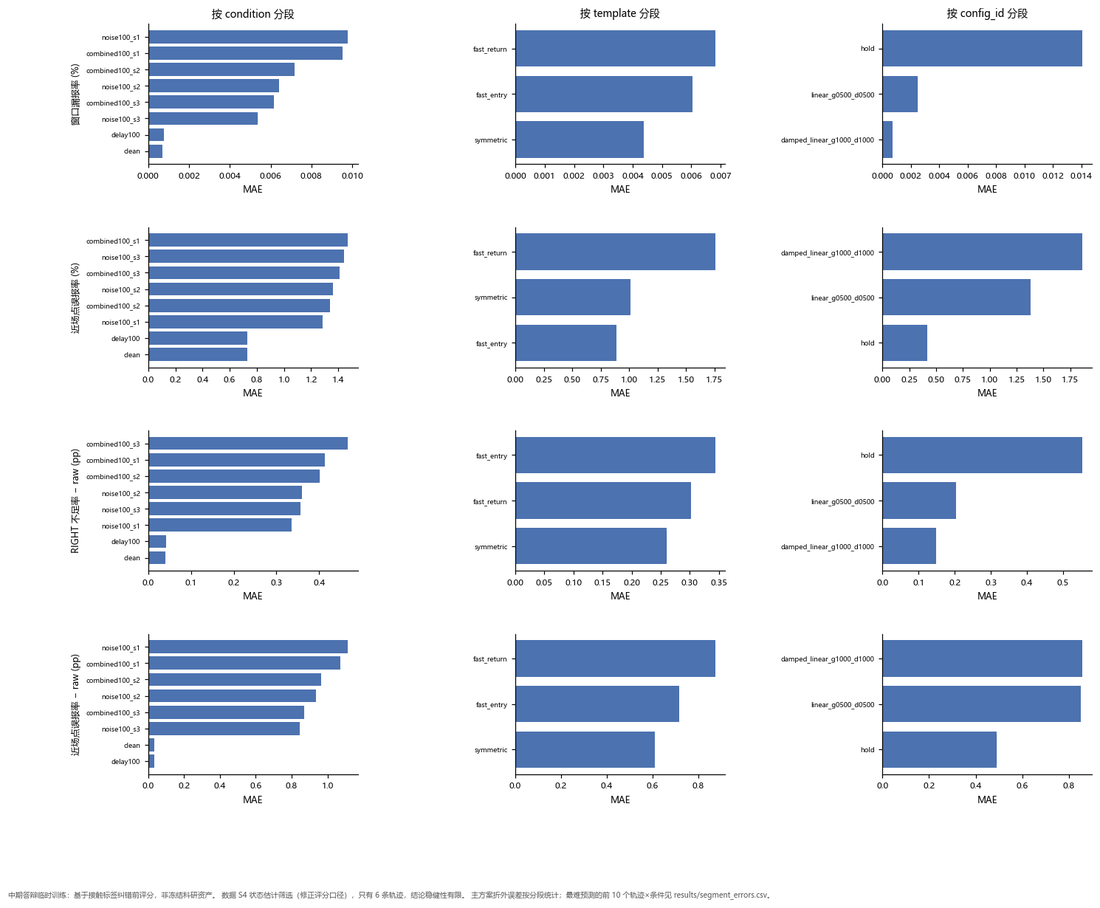

tavotoo 文件：05_M2b_状态估计筛选\M2b__fig04_分段误差.pdf（独立入口 05_M2b_状态估计筛选\M2b__fig04_分段误差.py）
原始程序：M2b_状态估计筛选/train.py（训练）+ common/figures.py（出图） → family_figures()；数据：_data/M2b_状态估计筛选/


In [44]:
show("M2b__fig04_分段误差")

**读出来的结论**：近场误报率在 combined100_s1、较快回正上最难；近场误报率 − raw 在 noise100_s1 上最难；RIGHT 不足率 − raw 在 combined100_s3、较快入弯上最难。误差最小的都是 clean 或 delay100 这类不带噪声的条件。

**用法**：同 M2a：噪声越强，代理模型越不可靠。

### 图 30　M2b 置换重要性

- **结论**：输入处理是近场误报率最重要的输入；相对 raw 能降多少误报，主要看噪声有多大。
- **证据**：4 个关键任务的置换重要性。**类型**：quantitative grid。**口径**：同上；窗口漏报率是 B 档，不作解释。

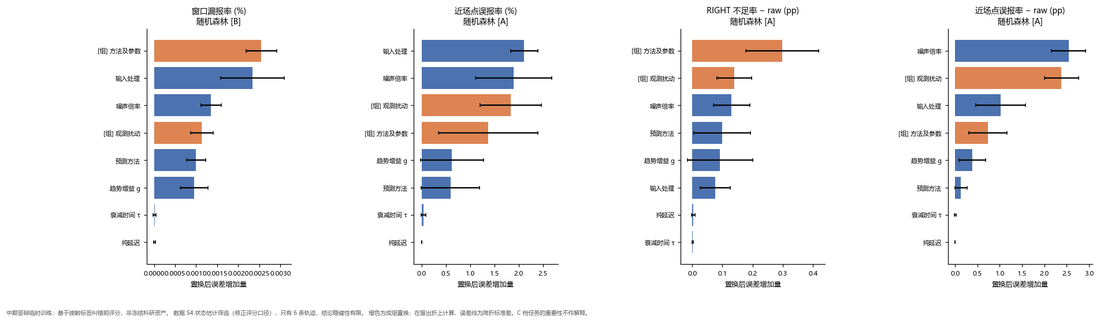

tavotoo 文件：05_M2b_状态估计筛选\M2b__fig05_置换重要性.pdf（独立入口 05_M2b_状态估计筛选\M2b__fig05_置换重要性.py）
原始程序：M2b_状态估计筛选/train.py（训练）+ common/figures.py（出图） → family_figures()；数据：_data/M2b_状态估计筛选/


In [45]:
show("M2b__fig05_置换重要性")

**读出来的结论**：近场误报率：输入处理 2.12、噪声 1.89；近场误报率 − raw：噪声 2.54、输入处理 1.02：噪声越大，状态估计降误报越多。RIGHT 不足率 − raw：方法及参数组 0.30 最重要。

**用法**：支持“状态估计是降误报的有效手段，在噪声大时更有价值”。

### 6.7 M3 二级处理联合（主模型）

用 S3 修正评分中 27 条开发轨迹的 5,400 行训练（2 方法 × 8 条件 × 12 后处理变体，加保持基线行），输入为驾驶因素、方法及参数、观测扰动和后处理三参数；19 个任务（16 个回归、3 个分类）。主验证按轨迹 5 折，主方案内做内层分组调参；另做留一动作模板、留一观测族；最后在 12 条选择轨迹（2,400 行）上做一次外部检验。外部检验的轨迹不参与训练、调参、阈值选择和学习曲线。

In [46]:
family_overview("M3_二级处理联合")
family_details("M3_二级处理联合")

M3 二级处理联合（主模型）：19 个任务，分档 A 19；主验证方案 按轨迹5折
口径： 数据 S3（修正评分口径），训练 27 条开发轨迹，外部检验 12 条选择轨迹，转角峰值均为 10°。


,口径,最优模型,档,主方案 skill,R²,AUC,skill[留一动作模板],skill[留一观测族],skill[外部检验(12条选择轨迹)]
目标,,,,,,,,,
RIGHT 不足率 (%),绝对值,随机森林,A,0.783,0.908,NaN,0.829,0.781,0.711
窗口漏报率 (%),绝对值,随机森林,A,0.744,0.779,NaN,0.750,0.759,0.754
提前量 P10 (s),绝对值,随机森林,A,0.905,0.983,NaN,0.903,0.545,0.830
近场点误报率 (%),绝对值,随机森林,A,0.906,0.987,NaN,0.918,0.942,0.761
逐帧误报率 (%),绝对值,随机森林,A,0.926,0.992,NaN,0.930,0.753,0.733
共同 2 s 逐帧误报率 (%),绝对值,随机森林,A,0.927,0.992,NaN,0.923,0.775,0.805
RIGHT 不足率 − 保持 (pp),配对差,梯度提升,A,0.724,0.925,NaN,0.747,0.669,0.564
提前量 P10 − 保持 (s),配对差,随机森林,A,0.806,0.954,NaN,0.867,0.784,0.781
近场点误报率 − 保持 (pp),配对差,随机森林,A,0.900,0.986,NaN,0.910,0.931,0.712


,档,最重要的三个输入（置换后误差增加量）,R²,残差偏度,MAE 最大的分段,最难预测（轨迹 | 条件）
任务,,,,,,
RIGHT 不足率 (%),A,[组] 后处理 0.747；确认时间 0.502；空间膨胀 0.472,0.908,0.35,观测条件 delay100；动作模板 fast_entry；后处理变体 W2_m0_c0.1；配置 hold,v4_r8_fast_entry | delay100
近场点误报率 (%),A,[组] 后处理 5.74；确认时间 4.69；噪声倍率 2.36,0.987,0.32,观测条件 combined100_s2；动作模板 fast_return；后处理变体 W3_m0_c0；配置 damped_linear_g1000_d1000,v4_r8_fast_entry | combined100_s2
RIGHT 不足率 − 无后处理 (pp),A,[组] 后处理 0.837；空间膨胀 0.525；确认时间 0.432,0.931,0.09,观测条件 combined100_s2；动作模板 fast_entry；后处理变体 W2_m0_c0.1；配置 linear_g0500_d0500,v4_r8_fast_entry | noise100_s1
近场点误报率 − 无后处理 (pp),A,[组] 后处理 6.06；确认时间 4.86；噪声倍率 2.59,0.986,0.28,观测条件 combined100_s1；动作模板 fast_return；后处理变体 W3_m0_c0.1；配置 damped_linear_g1000_d1000,v4_r2_fast_return | combined100_s1
出现窗口漏报,A,[组] 后处理 0.218；确认时间 0.162；空间膨胀 0.121,NaN,NaN,NaN,NaN
接触前完全无报警,A,[组] 后处理 0.202；确认时间 0.146；空间膨胀 0.121,NaN,NaN,NaN,NaN
误报预算达标,A,[组] 后处理 0.399；确认时间 0.272；空间膨胀 0.124,NaN,NaN,NaN,NaN


### 图 31　M3 模型对比与分档

- **结论**：19 个任务全部 A 档，而且在 12 条没见过的选择轨迹上依然准确（外部 skill 0.48–0.86）。
- **证据**：每个任务三种模型在按轨迹 5 折下的 skill；黑色记号为最优模型在留一动作模板、留一观测族和外部检验下的 skill。**类型**：quantitative grid。**口径**：D3、修正口径。

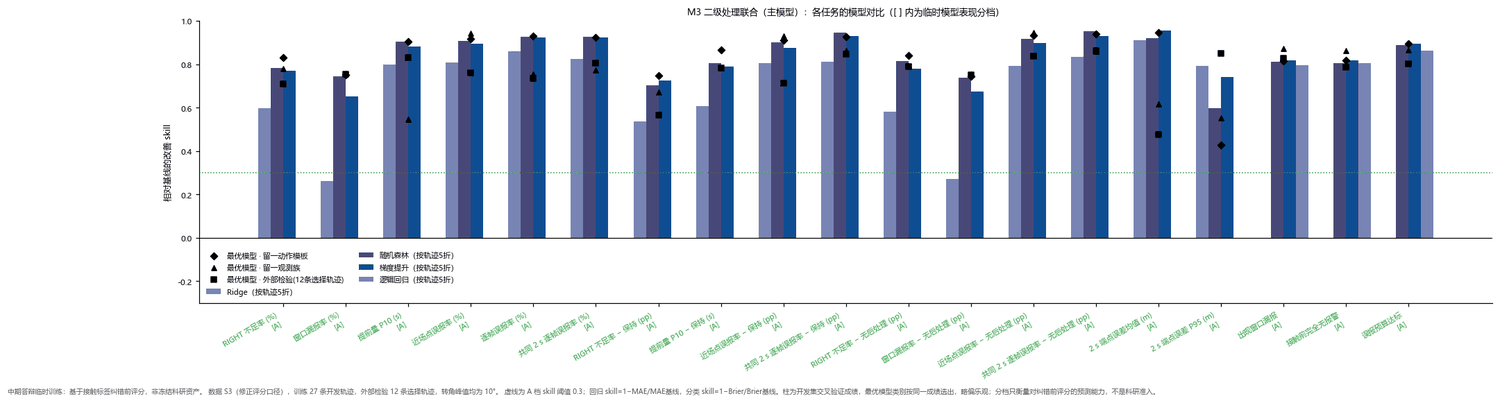

tavotoo 文件：06_M3_二级处理联合\M3__fig01_模型对比与分档.pdf（独立入口 06_M3_二级处理联合\M3__fig01_模型对比与分档.py）
原始程序：M3_二级处理联合/train.py（训练）+ common/figures.py（出图） → family_figures()；数据：_data/M3_二级处理联合/


In [47]:
show("M3__fig01_模型对比与分档", width=1500)

**读出来的结论**：外部检验 skill：RIGHT 不足率 0.71（R² 0.87），近场误报率 0.76（0.90），相对无后处理的 RIGHT 变化 0.79、误报变化 0.84；最低的是 2 s 端点误差均值（0.48，R² 0.78）和 RIGHT 不足率 − 保持（0.56）。留一观测族时提前量 P10 降到 0.55，留一动作模板时端点误差 P95 降到 0.43：尾部指标对没见过的条件和模板更敏感。

**用法**：本阶段代理模型最有说服力的一张图：规律能推广到同一几何内的新轨迹。外部 skill 普遍低于主方案，正好说明主方案略偏乐观。

### 图 32　M3 折外预测与仿真值

- **结论**：4 个关键回归任务的折外预测都紧贴对角线。
- **证据**：4 个面板依次为 RIGHT 不足率、近场误报率、相对无后处理的 RIGHT 变化与误报变化。**类型**：quantitative grid。**口径**：按轨迹 5 折折外预测。

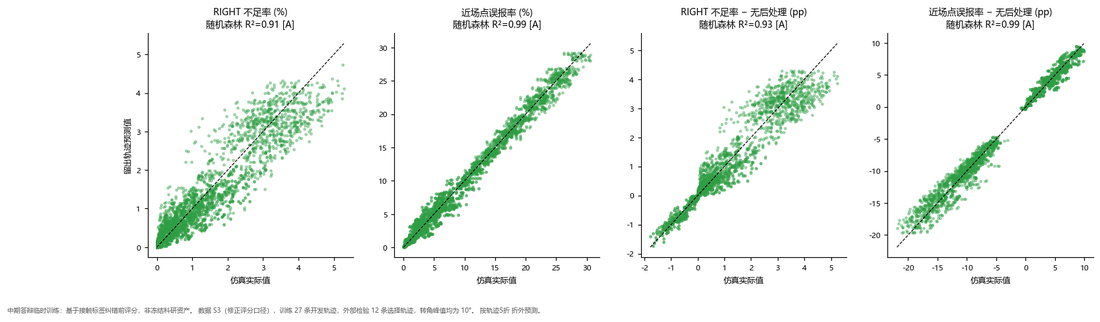

tavotoo 文件：06_M3_二级处理联合\M3__fig02_预测vs实际_折外.pdf（独立入口 06_M3_二级处理联合\M3__fig02_预测vs实际_折外.py）
原始程序：M3_二级处理联合/train.py（训练）+ common/figures.py（出图） → family_figures()；数据：_data/M3_二级处理联合/


In [48]:
show("M3__fig02_预测vs实际_折外")

**读出来的结论**：R² 依次为 0.908、0.987、0.931、0.986。

**用法**：与 fig08（外部检验）对照：外部检验同样四个任务的散点会更散一些。

### 图 33　M3 残差诊断

- **结论**：残差围绕 0、偏度小，没有系统偏差。
- **证据**：上排残差对预测值，下排残差直方图与偏度。**类型**：quantitative grid。**口径**：同上。

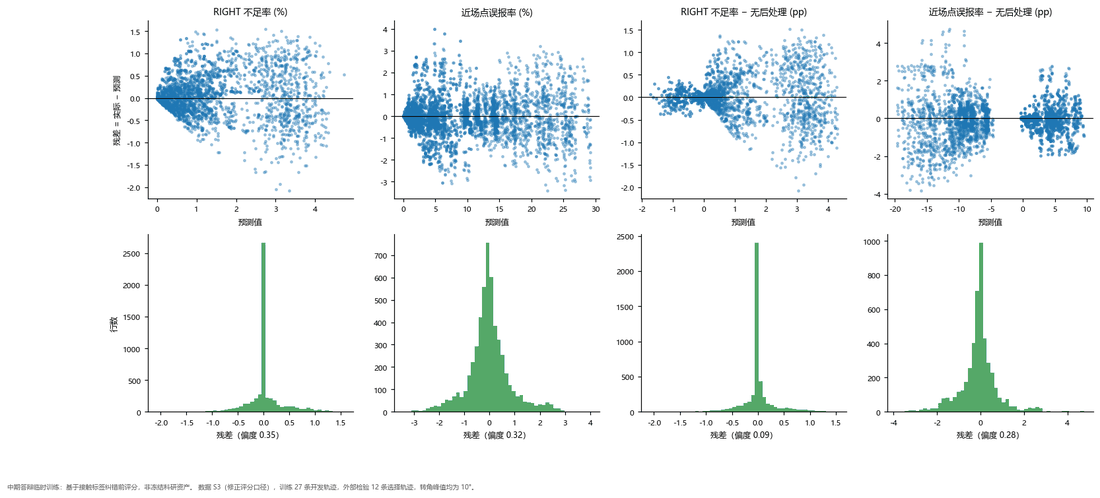

tavotoo 文件：06_M3_二级处理联合\M3__fig03_残差诊断.pdf（独立入口 06_M3_二级处理联合\M3__fig03_残差诊断.py）
原始程序：M3_二级处理联合/train.py（训练）+ common/figures.py（出图） → family_figures()；数据：_data/M3_二级处理联合/


In [49]:
show("M3__fig03_残差诊断")

**读出来的结论**：4 个任务的残差偏度在 0.09–0.35 之间，比 M1、M2 都小。残差的散布随预测值增大而变宽：迟报、误报越高的工况越难预测准。相对无后处理的误报变化分成左右两团，对应有无确认时间。

**用法**：说明 M3 的预测没有系统偏差；但对高迟报、高误报的工况，预测的绝对误差更大。

### 图 34　M3 分段误差

- **结论**：最难预测的是“确认 0.1 s 且无膨胀”的变体和延迟 / combined 条件。
- **证据**：4 行 × 4 列（按观测条件、动作模板、后处理变体、配置）的折外 MAE。**类型**：quantitative grid。**口径**：同上。

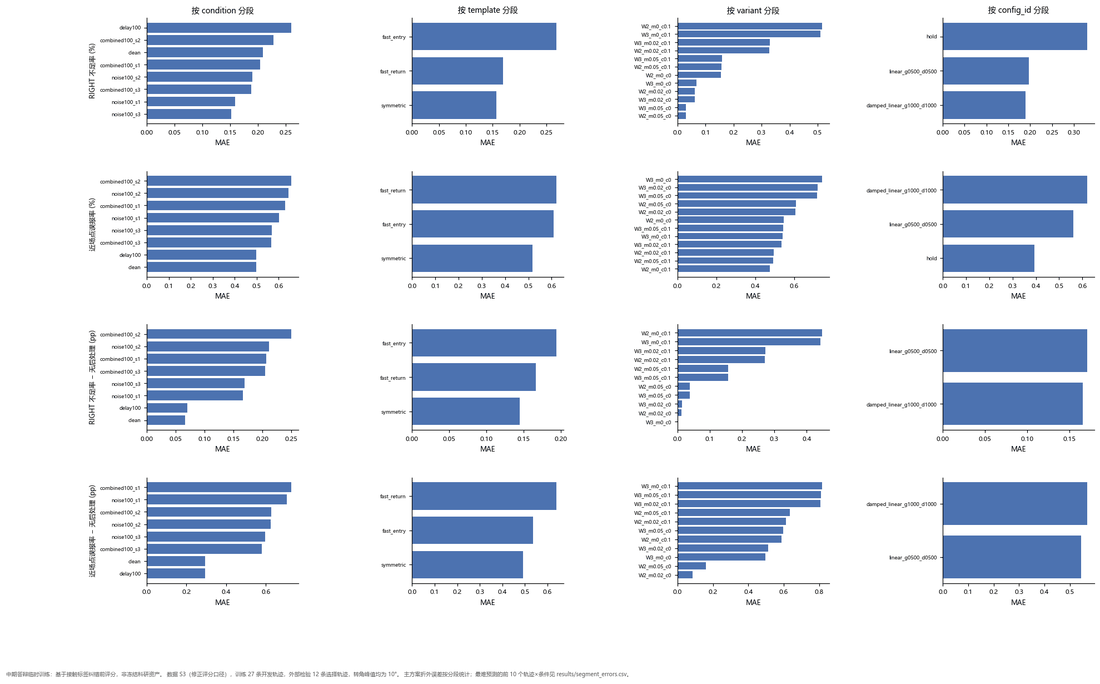

tavotoo 文件：06_M3_二级处理联合\M3__fig04_分段误差.pdf（独立入口 06_M3_二级处理联合\M3__fig04_分段误差.py）
原始程序：M3_二级处理联合/train.py（训练）+ common/figures.py（出图） → family_figures()；数据：_data/M3_二级处理联合/


In [50]:
show("M3__fig04_分段误差")

**读出来的结论**：RIGHT 不足率及其相对无后处理的变化，在 W2_m0_c0.1 上误差最大，正是出现窗口漏报最多的变体（图 13）；误报类任务在出弯窗口 3 s 的变体上最难。按模板，迟报类在较快入弯、误报类在较快回正上最难。

**用法**：提示“确认但不膨胀”的组合是代理模型最不可靠的区域，恰好也是安全上最危险的组合。

### 图 35　M3 置换重要性

- **结论**：后处理是最重要的一组输入，其中确认时间最重要；方法类别排不进前列。
- **证据**：4 个关键回归任务的置换重要性（橙色为成组置换）。**类型**：quantitative grid。**口径**：同上，全部 A 档。

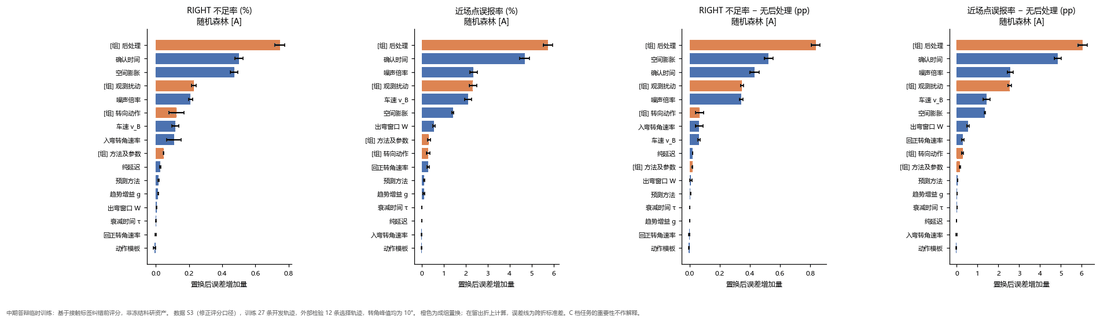

tavotoo 文件：06_M3_二级处理联合\M3__fig05_置换重要性.pdf（独立入口 06_M3_二级处理联合\M3__fig05_置换重要性.py）
原始程序：M3_二级处理联合/train.py（训练）+ common/figures.py（出图） → family_figures()；数据：_data/M3_二级处理联合/


In [51]:
show("M3__fig05_置换重要性")

**读出来的结论**：RIGHT 不足率：后处理组 0.747、确认时间 0.502、空间膨胀 0.472、观测扰动组 0.228。近场误报率：后处理组 5.74、确认时间 4.69、噪声倍率 2.36。与 图 13 和 图 7 的排序一致。

**用法**：支持“后处理参数比方法细节更值得调”的说法。

In [52]:
cm = json.loads((DATA / "M3_二级处理联合" / "confusion_matrices.json").read_text(encoding="utf-8"))


def cm_table(cm):
    rows = []
    for task, v in cm.items():
        for name, x in v.items():
            if name == "source":
                continue
            (tn, fp), (fn, tp) = x["matrix"]
            lo, hi = x.get("threshold_range", [x["threshold"]] * 2)
            rows.append({"任务": target_label(task), "阈值": name.split("（")[0],
                         "取值": f"{x['threshold']:.3f}" if abs(hi - lo) < 1e-9 else f"{lo:.3f}–{hi:.3f}",
                         "真阴性": tn, "假阳性": fp, "假阴性": fn, "真阳性": tp, "召回": x["recall"], "精确率": x["precision"]})
    return pd.DataFrame(rows).set_index(["任务", "阈值"]).round(3)


print("数据来源：", next(iter(cm.values()))["source"])
display(cm_table(cm))

数据来源： 外部检验（阈值只用开发集折外预测确定）


取值   真阴性  假阳性  假阴性  真阳性     召回    精确率
任务       阈值                                                
出现窗口漏报   默认阈值 0.5  0.500  1830  112    0  458  1.000  0.804
         安全优先      0.512  1830  112    0  458  1.000  0.804
接触前完全无报警 默认阈值 0.5  0.500  1898  103   16  383  0.960  0.788
         安全优先      0.399  1876  125    5  394  0.987  0.759
误报预算达标   默认阈值 0.5  0.500  1312  135    3  950  0.997  0.876
         安全优先      0.800  1359   88   28  925  0.971  0.913

### 图 36　M3 分类任务的混淆矩阵（外部检验）

- **结论**：在 12 条没见过的轨迹上，“这组设置会不会出现窗口漏报”能被 100% 召回，代价是约五分之一的误警。
- **证据**：3 行（出现窗口漏报、接触前完全无报警、误报预算达标）× 2 列（默认阈值 0.5、安全优先阈值）的 2 × 2 混淆矩阵。**类型**：quantitative grid。**口径**：外部检验 2,400 行；阈值只用开发集折外预测确定。

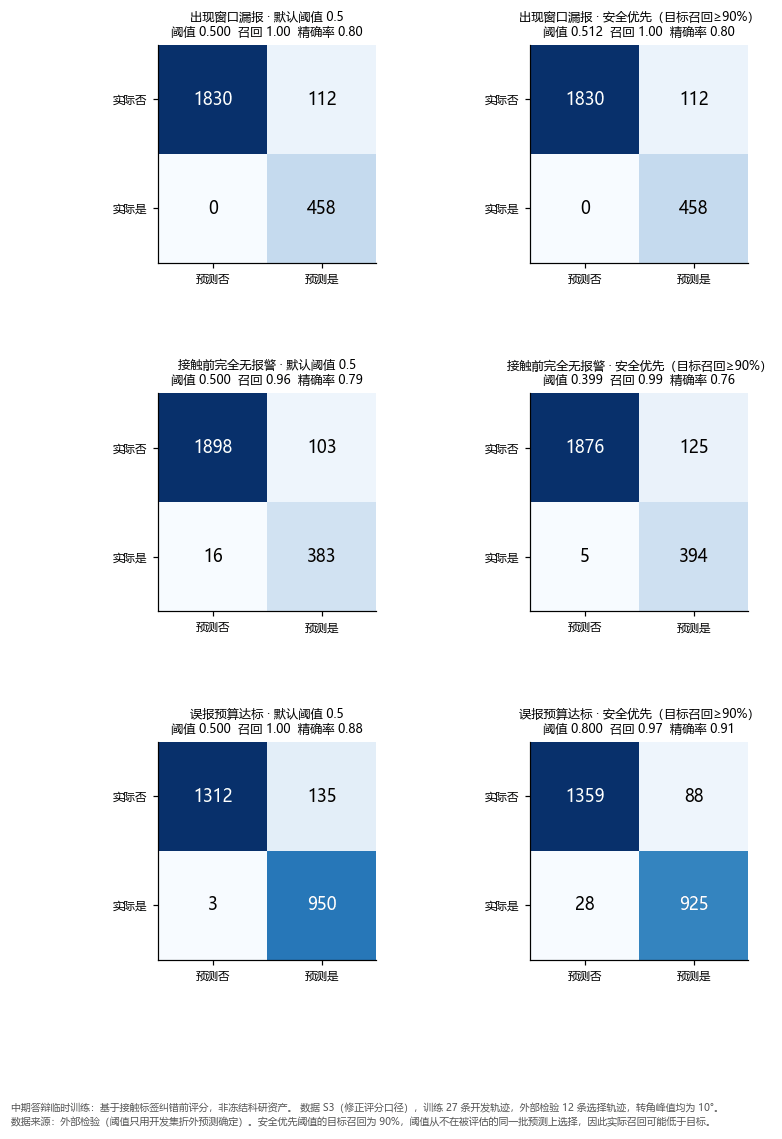

tavotoo 文件：06_M3_二级处理联合\M3__fig06_混淆矩阵.pdf（独立入口 06_M3_二级处理联合\M3__fig06_混淆矩阵.py）
原始程序：M3_二级处理联合/train.py（训练）+ common/figures.py（出图） → family_figures()；数据：_data/M3_二级处理联合/


In [53]:
show("M3__fig06_混淆矩阵")

**读出来的结论**：出现窗口漏报：两种阈值结果相同，458 个正例全部抓到（召回 1.00），另有 112 个误警（精确率 0.80）。接触前完全无报警：默认阈值召回 0.96；安全优先阈值 0.399 把召回提到 0.987（只漏 5 个），精确率 0.76。误报预算达标：安全优先阈值 0.800 下召回 0.971、精确率 0.913。

**用法**：说明代理模型可以作为“设置筛查器”：先排除很可能出现漏报的组合，再做仿真确认。一行是一个评分行，不是一次独立事故。

### 图 37　M3 分类任务的 ROC 与 PR 曲线（外部检验）

- **结论**：三个分类任务在外部检验上 AUC 都约 0.99。
- **证据**：a ROC 曲线（图例含 AUC），b 精确率–召回曲线（图例含正例比例）。**类型**：quantitative grid。**口径**：同上；曲线由保存的原图曲线数组重放，与原图逐点一致。

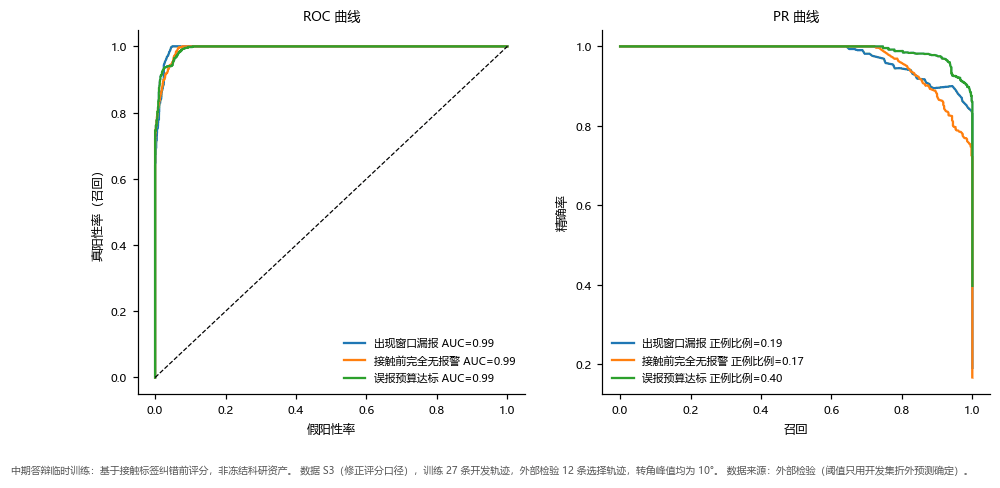

tavotoo 文件：06_M3_二级处理联合\M3__fig07_ROC_PR.pdf（独立入口 06_M3_二级处理联合\M3__fig07_ROC_PR.py）
原始程序：M3_二级处理联合/train.py（训练）+ common/figures.py（出图） → family_figures()；数据：_data/M3_二级处理联合/


In [54]:
show("M3__fig07_ROC_PR")

**读出来的结论**：外部 AUC：出现窗口漏报 0.994、接触前完全无报警 0.994、误报预算达标 0.994。PR 曲线在召回接近 1 时精确率仍较高。

**用法**：与 fig06 一起说明分类器的区分能力；具体阈值下的取舍看 fig06。

### 图 38　M3 外部检验：预测与仿真值

- **结论**：用 27 条开发轨迹训练的模型，在 12 条从未见过的选择轨迹上依然贴近对角线。
- **证据**：4 个面板为 4 个关键回归任务，颜色区分 12 条选择轨迹，标题给出外部 skill 与 R²。**类型**：quantitative grid。**口径**：外部检验 2,400 行，每个任务只评一次。

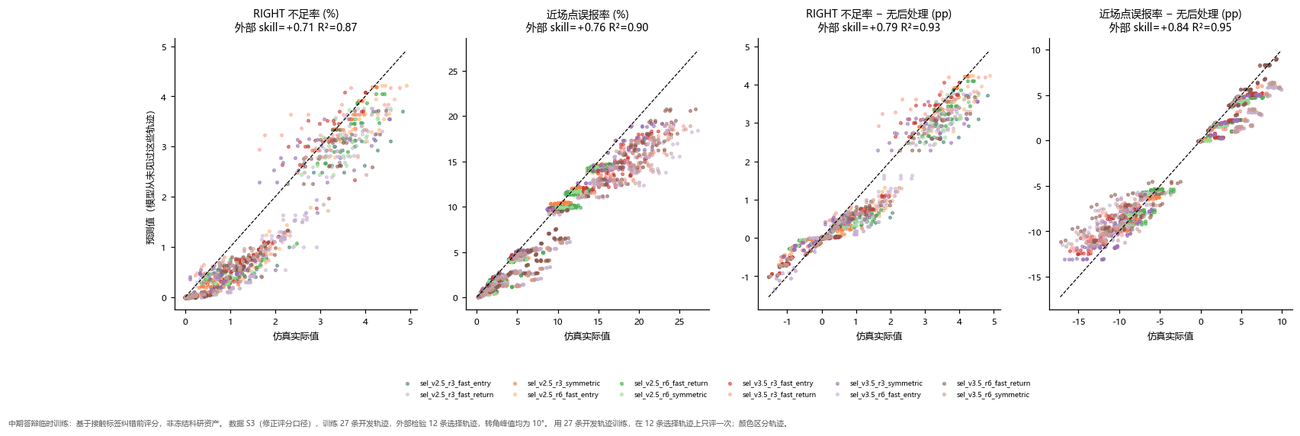

tavotoo 文件：06_M3_二级处理联合\M3__fig08_外部检验_预测vs实际.pdf（独立入口 06_M3_二级处理联合\M3__fig08_外部检验_预测vs实际.py）
原始程序：M3_二级处理联合/train.py（训练）+ common/figures.py（出图） → family_figures()；数据：_data/M3_二级处理联合/


In [55]:
show("M3__fig08_外部检验_预测vs实际", width=1300)

**读出来的结论**：外部 skill / R²：RIGHT 不足率 0.71 / 0.87，近场误报率 0.76 / 0.90，相对无后处理的 RIGHT 变化 0.79 / 0.93，误报变化 0.84 / 0.95。与 fig02 相比点更散，但没有哪条轨迹整体偏离。

**用法**：推广性的直接证据。注意选择集与开发集是同一种转弯几何（车速、速率取在开发集的网格之间），这是内插，不说明对新路口几何的推广。

In [56]:
lc = load("M3_二级处理联合/learning_curve")
print("学习曲线：每折训练用的轨迹数 → 留出折 skill（每个规模抽 2 次取平均）")
display(lc.groupby(["task", "n_label"], sort=False).skill.mean().unstack()[["5", "10", "15", "20", "全部"]].rename(index=target_label).round(3))

学习曲线：每折训练用的轨迹数 → 留出折 skill（每个规模抽 2 次取平均）


n_label,5,10,15,20,全部
task,,,,,
RIGHT 不足率 (%),0.636,0.725,0.747,0.775,0.780
近场点误报率 (%),0.802,0.864,0.893,0.905,0.906
近场点误报率 − 无后处理 (pp),0.836,0.880,0.891,0.914,0.916
出现窗口漏报,0.787,0.803,0.810,0.817,0.821


### 图 39　M3 学习曲线

- **结论**：训练轨迹从 5 条增加到约 21 条，误差下降逐渐变平：再加同类轨迹收益有限，下一步应增加新的转弯几何，而不是同一几何下的更多轨迹。
- **证据**：4 个面板（RIGHT 不足率、近场误报率、出现窗口漏报、相对无后处理的误报变化），横轴为每折训练用的轨迹数，阴影为两次抽样的最小–最大，虚线为基线。**类型**：quantitative grid。**口径**：只在开发集内部完成，外部集不参与；模型类别与超参数与最终模型一致。

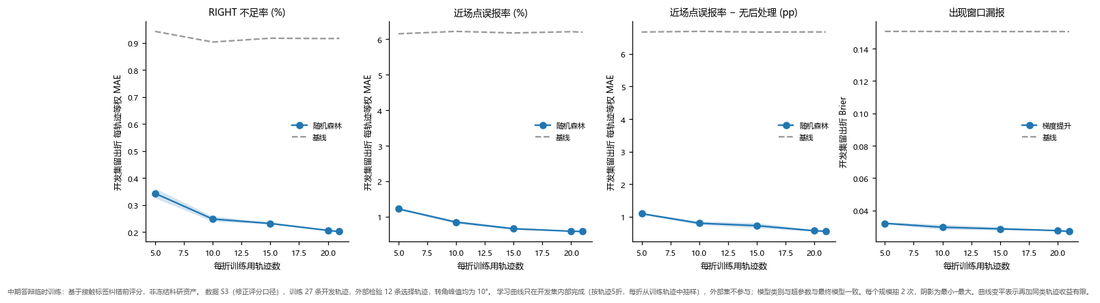

tavotoo 文件：06_M3_二级处理联合\M3__fig09_学习曲线.pdf（独立入口 06_M3_二级处理联合\M3__fig09_学习曲线.py）
原始程序：M3_二级处理联合/train.py（训练）+ common/figures.py（出图） → family_figures()；数据：_data/M3_二级处理联合/


In [57]:
show("M3__fig09_学习曲线")

**读出来的结论**（上表）：RIGHT 不足率的 skill 在 5 / 10 / 15 / 20 / 全部条轨迹时为 0.636 / 0.725 / 0.747 / 0.775 / 0.780；近场误报率 0.802 / 0.864 / 0.893 / 0.905 / 0.906；出现窗口漏报 0.787 / 0.803 / 0.810 / 0.817 / 0.821。从 20 条到全部几乎不再提高。

**用法**：支持“数据量在当前几何内已基本够用”的判断，以及扩展到新几何的下一步计划。

In [58]:
pdp = json.loads((DATA / "M3_二级处理联合" / "pdp.json").read_text(encoding="utf-8"))
rows = []
for task in ("right_pct", "negative_fp_pct"):
    for f in ("EXIT_W_s", "margin_m", "confirmation_s", "noise_level"):
        rows.append({"任务": target_label(task), "输入": FEATURE_LABEL[f], "取值": " / ".join(f"{x:g}" for x in pdp[task][f]["grid"]),
                     "模型平均预测": " / ".join(f"{y:.2f}" for y in pdp[task][f]["avg"])})
display(pd.DataFrame(rows).set_index(["任务", "输入"]))
for task in ("right_pct", "negative_fp_pct"):
    two = pdp[task]["margin_m×confirmation_s"]
    t2 = pd.DataFrame(two["avg"], index=[f"膨胀 {m:g} m" for m in two["grid"][0]], columns=[f"确认 {c:g} s" for c in two["grid"][1]])
    print(target_label(task) + "：膨胀 × 确认的二维部分依赖")
    display(t2.round(2))

取值               模型平均预测
任务            输入                                          
RIGHT 不足率 (%) 出弯窗口 W            2 / 3          0.79 / 0.74
              空间膨胀    0 / 0.02 / 0.05   1.52 / 0.63 / 0.20
              确认时间            0 / 0.1          0.20 / 1.40
              噪声倍率              0 / 1          0.83 / 0.75
近场点误报率 (%)    出弯窗口 W            2 / 3          7.74 / 9.38
              空间膨胀    0 / 0.02 / 0.05  6.73 / 8.19 / 10.77
              确认时间            0 / 0.1         13.55 / 3.40
              噪声倍率              0 / 1         3.62 / 10.18

RIGHT 不足率 (%)：膨胀 × 确认的二维部分依赖


,确认 0 s,确认 0.1 s
膨胀 0 m,0.28,2.81
膨胀 0.02 m,0.23,1.03
膨胀 0.05 m,0.08,0.30


近场点误报率 (%)：膨胀 × 确认的二维部分依赖


,确认 0 s,确认 0.1 s
膨胀 0 m,11.62,1.69
膨胀 0.02 m,13.22,3.04
膨胀 0.05 m,15.84,5.54


### 图 40　M3 部分依赖：后处理参数

- **结论**：模型学到的规律与描述性统计一致：确认压误报、抬迟报；膨胀抬误报、压迟报；“确认 + 膨胀”组合能同时把两者控制在较低水平。
- **证据**：7 行（7 个关键任务）× 5 列：前 4 列为出弯窗口、膨胀、确认、噪声的一维部分依赖，最右列为膨胀 × 确认的二维部分依赖（格中为模型平均预测）。**类型**：quantitative grid。**口径**：开发集上的模型规律，不是因果效应。

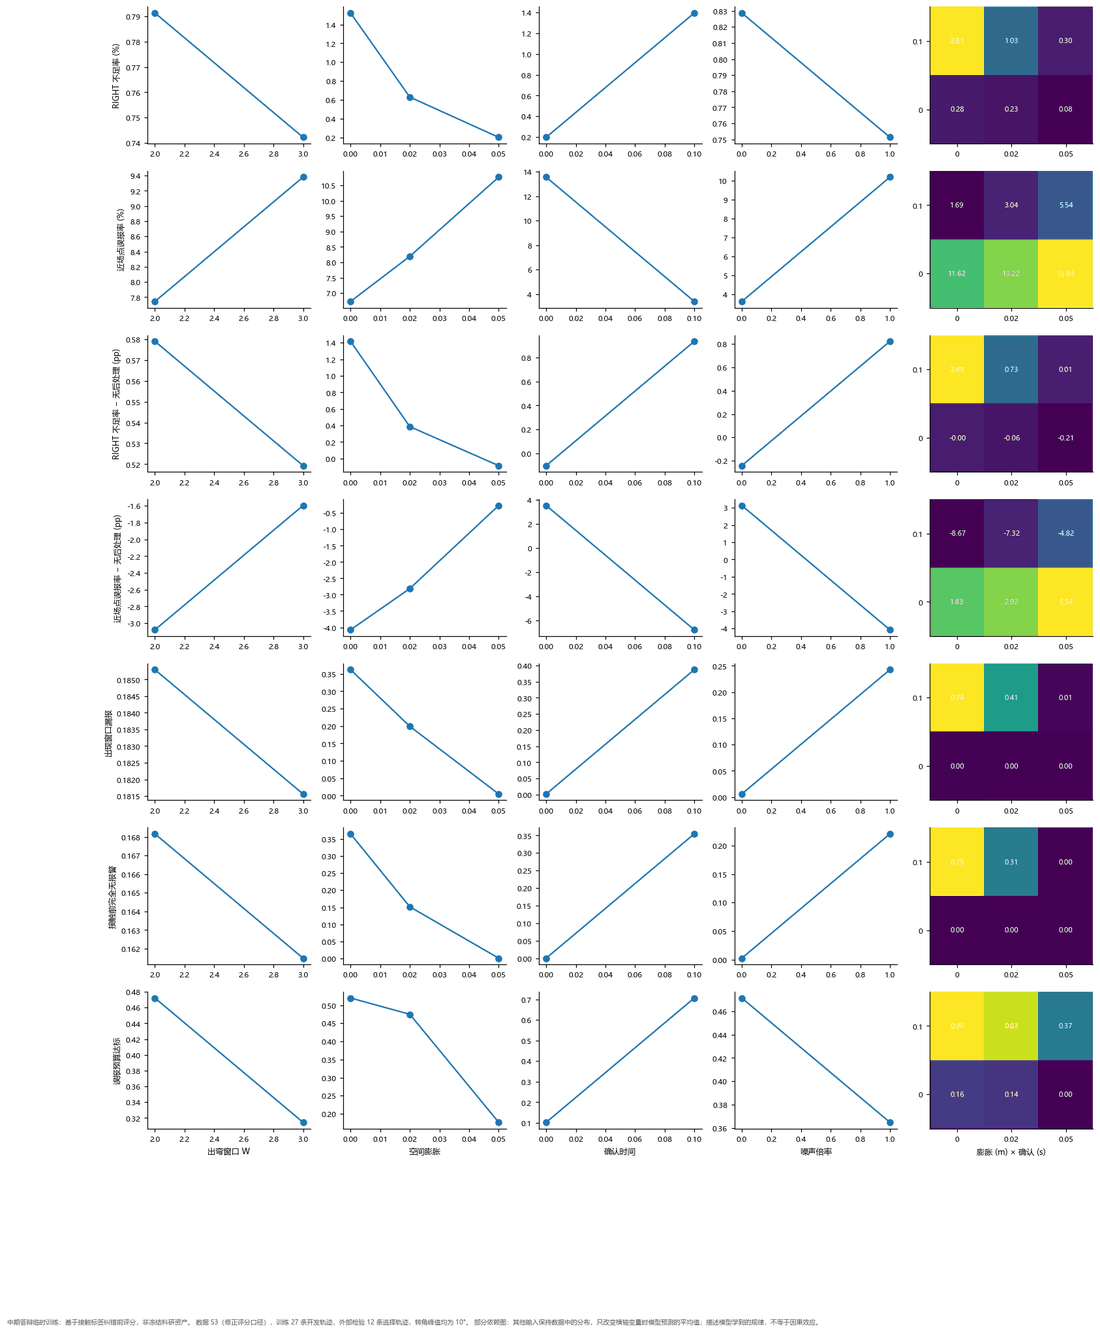

tavotoo 文件：06_M3_二级处理联合\M3__fig10_部分依赖_后处理.pdf（独立入口 06_M3_二级处理联合\M3__fig10_部分依赖_后处理.py）
原始程序：M3_二级处理联合/train.py（训练）+ common/figures.py（出图） → family_figures()；数据：_data/M3_二级处理联合/


In [59]:
show("M3__fig10_部分依赖_后处理")

**读出来的结论**：RIGHT 不足率的模型平均预测：确认 0 → 0.1 s 为 0.20% → 1.40%；膨胀 0 / 0.02 / 0.05 m 为 1.52% / 0.63% / 0.20%。二维图中，“确认 0.1 s + 膨胀 0”为 2.81%，加上 0.05 m 膨胀降到 0.30%。近场误报率：确认 0 → 0.1 s 为 13.55% → 3.40%，噪声 0 → 1 倍为 3.62% → 10.18%；“确认 0.1 s + 膨胀 0.05 m”为 5.54%。

**用法**：给出可操作的参数方向：确认时间必须配合膨胀使用。部分依赖是在其他输入保持数据分布时的平均，不能当成单个工况的预测。

### 6.8 M4 趋势增益精化

用 S4 联合精化（D5：8,064 行、12 条选择轨迹、修正口径）训练，输入同 M3，增益细档为线性 g ∈ {0.375, 0.5, 0.625}、衰减线性 g ∈ {0.75, 1, 1.25}。12 条轨迹按轨迹 4 折验证，另做留一动作模板。这 12 条轨迹同时是调参数据，没有外部检验。

In [60]:
family_overview("M4_趋势增益精化")
family_details("M4_趋势增益精化")

M4 趋势增益精化：19 个任务，分档 A 19；主验证方案 按轨迹4折
口径： 数据 S4 联合精化（修正评分口径），12 条选择轨迹（属于调参数据），增益细档效应只来自这 12 条轨迹。


,口径,最优模型,档,主方案 skill,R²,AUC,skill[留一动作模板]
目标,,,,,,,
RIGHT 不足率 (%),绝对值,随机森林,A,0.828,0.941,NaN,0.845
窗口漏报率 (%),绝对值,随机森林,A,0.770,0.821,NaN,0.787
提前量 P10 (s),绝对值,随机森林,A,0.881,0.972,NaN,0.877
近场点误报率 (%),绝对值,随机森林,A,0.900,0.984,NaN,0.920
逐帧误报率 (%),绝对值,随机森林,A,0.893,0.985,NaN,0.908
共同 2 s 逐帧误报率 (%),绝对值,梯度提升,A,0.893,0.985,NaN,0.860
RIGHT 不足率 − 保持 (pp),配对差,梯度提升,A,0.640,0.829,NaN,0.640
提前量 P10 − 保持 (s),配对差,随机森林,A,0.583,0.696,NaN,0.609
近场点误报率 − 保持 (pp),配对差,随机森林,A,0.755,0.935,NaN,0.790


,档,最重要的三个输入（置换后误差增加量）,R²,残差偏度,MAE 最大的分段,最难预测（轨迹 | 条件）
任务,,,,,,
RIGHT 不足率 (%),A,[组] 后处理 0.983；确认时间 0.637；空间膨胀 0.609,0.941,-0.11,观测条件 delay100；动作模板 fast_entry；后处理变体 W2_m0_c0.1；配置 hold,sel_v3.5_r6_fast_entry | delay100
近场点误报率 (%),A,[组] 后处理 5.46；确认时间 4.24；[组] 观测扰动 2.06,0.984,0.61,观测条件 combined100_s1；动作模板 fast_return；后处理变体 W3_m0_c0；配置 damped_linear_g1250_d1000,sel_v3.5_r6_fast_return | combined100_s1
RIGHT 不足率 − 保持 (pp),A,[组] 后处理 0.688；确认时间 0.48；空间膨胀 0.306,0.829,-0.31,观测条件 combined100_s2；动作模板 fast_entry；后处理变体 W3_m0.02_c0.1；配置 damped_linear_g1250_d1000,sel_v3.5_r6_fast_entry | combined100_s1
近场点误报率 − 保持 (pp),A,[组] 后处理 1.62；确认时间 1.31；车速 v_B 0.815,0.935,0.32,观测条件 combined100_s1；动作模板 fast_return；后处理变体 W3_m0_c0.1；配置 damped_linear_g1250_d1000,sel_v3.5_r6_fast_return | combined100_s1


### 图 41　M4 模型对比与分档

- **结论**：19 个任务全部 A 档；相对保持的配对差最难预测。
- **证据**：每个任务三种模型在按轨迹 4 折下的 skill；黑色记号为最优模型在留一动作模板下的 skill。**类型**：quantitative grid。**口径**：D5、修正口径，没有外部检验。

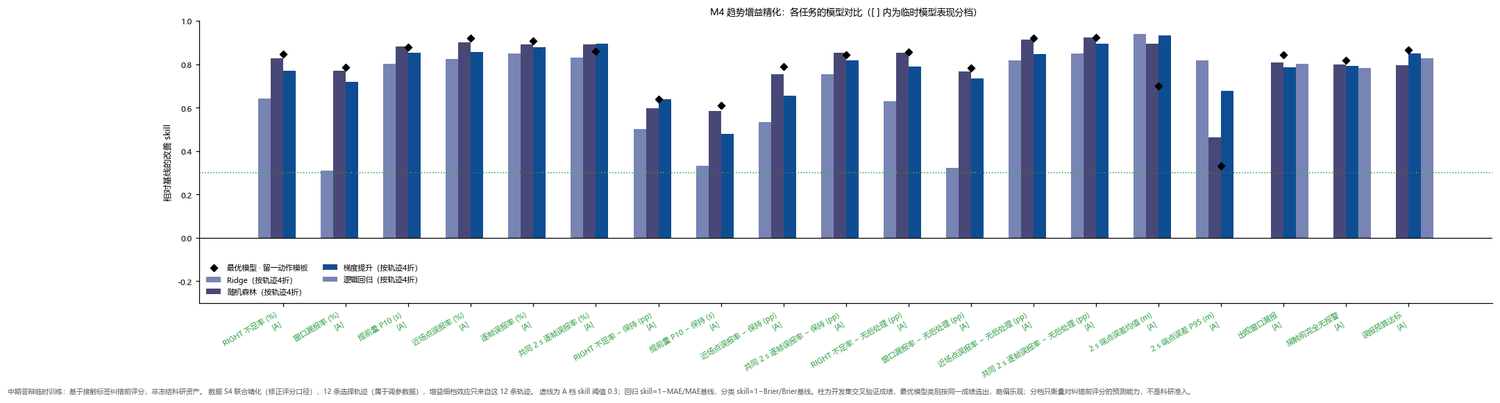

tavotoo 文件：07_M4_趋势增益精化\M4__fig01_模型对比与分档.pdf（独立入口 07_M4_趋势增益精化\M4__fig01_模型对比与分档.py）
原始程序：M4_趋势增益精化/train.py（训练）+ common/figures.py（出图） → family_figures()；数据：_data/M4_趋势增益精化/


In [61]:
show("M4__fig01_模型对比与分档", width=1500)

**读出来的结论**：主方案 skill 0.58–0.94；最低的是提前量 P10 − 保持（0.58）和 RIGHT 不足率 − 保持（0.64）。留一动作模板下端点误差 P95 降到 0.33、端点误差均值降到 0.70（都是 Ridge）。

**用法**：说明增益细调数据上的规律也稳定；但只有 12 条轨迹、没有外部检验，推广性弱于 M3。

### 图 42　M4 折外预测与仿真值

- **结论**：4 个关键回归任务的折外预测贴近对角线。
- **证据**：4 个面板依次为 RIGHT 不足率、近场误报率、RIGHT 不足率 − 保持、近场误报率 − 保持。**类型**：quantitative grid。**口径**：按轨迹 4 折折外预测。

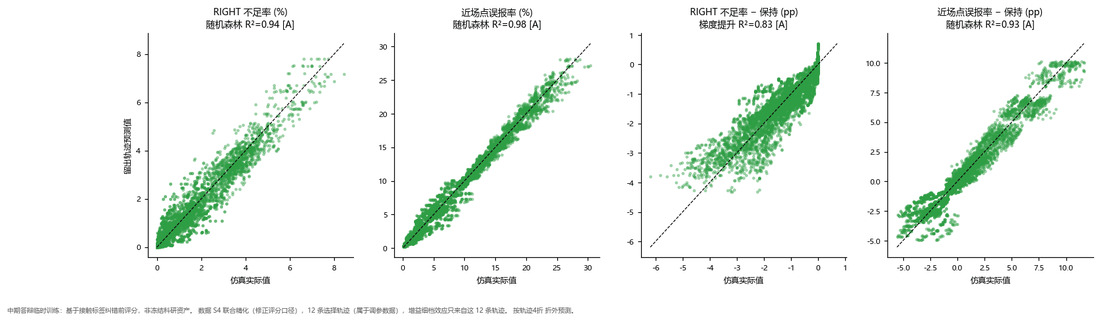

tavotoo 文件：07_M4_趋势增益精化\M4__fig02_预测vs实际_折外.pdf（独立入口 07_M4_趋势增益精化\M4__fig02_预测vs实际_折外.py）
原始程序：M4_趋势增益精化/train.py（训练）+ common/figures.py（出图） → family_figures()；数据：_data/M4_趋势增益精化/


In [62]:
show("M4__fig02_预测vs实际_折外")

**读出来的结论**：R² 依次为 0.94、0.98、0.83、0.94。

**用法**：同 M3 fig02。

### 图 43　M4 残差诊断

- **结论**：残差围绕 0，偏度小。
- **证据**：上排残差对预测值，下排残差直方图与偏度。**类型**：quantitative grid。**口径**：同上。

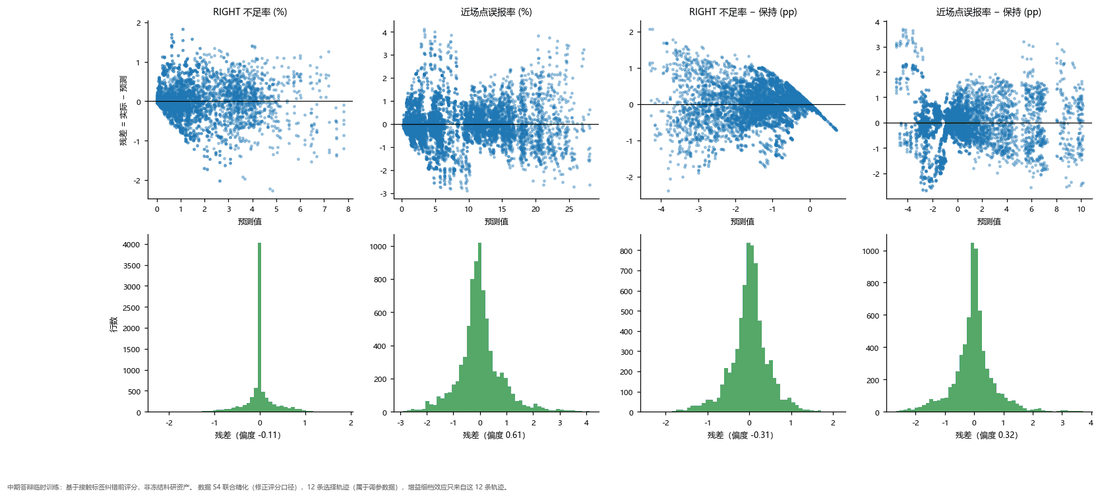

tavotoo 文件：07_M4_趋势增益精化\M4__fig03_残差诊断.pdf（独立入口 07_M4_趋势增益精化\M4__fig03_残差诊断.py）
原始程序：M4_趋势增益精化/train.py（训练）+ common/figures.py（出图） → family_figures()；数据：_data/M4_趋势增益精化/


In [63]:
show("M4__fig03_残差诊断")

**读出来的结论**：4 个任务的残差偏度在 −0.31 到 0.61 之间，近场误报率略右偏（0.61）。

**用法**：说明没有明显的系统偏差。

### 图 44　M4 分段误差

- **结论**：最难预测的是 sel_v3.5_r6 的较快入弯 / 回正轨迹，以及“确认 0.1 s”的变体。
- **证据**：4 行 × 4 列（按观测条件、动作模板、后处理变体、配置）的折外 MAE。**类型**：quantitative grid。**口径**：同上。

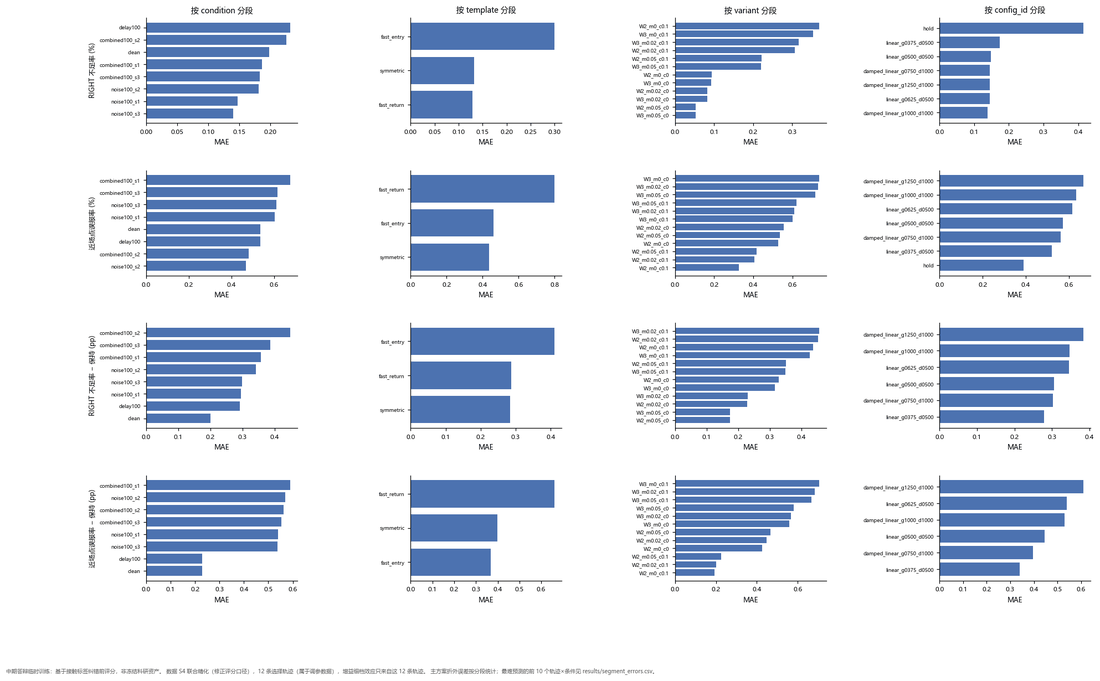

tavotoo 文件：07_M4_趋势增益精化\M4__fig04_分段误差.pdf（独立入口 07_M4_趋势增益精化\M4__fig04_分段误差.py）
原始程序：M4_趋势增益精化/train.py（训练）+ common/figures.py（出图） → family_figures()；数据：_data/M4_趋势增益精化/


In [64]:
show("M4__fig04_分段误差")

**读出来的结论**：RIGHT 不足率在 W2_m0_c0.1、较快入弯、延迟条件上误差最大；近场误报率在出弯窗口 3 s、较快回正、combined 条件上最大。按配置，保持的 RIGHT 不足率最难预测，增益最大的衰减线性 g = 1.25 的误报最难预测。

**用法**：同 M3 fig04。

### 图 45　M4 置换重要性

- **结论**：即使专门细调了增益，后处理仍是最重要的输入，增益排不进前列。
- **证据**：4 个关键任务的置换重要性。**类型**：quantitative grid。**口径**：同上，全部 A 档。

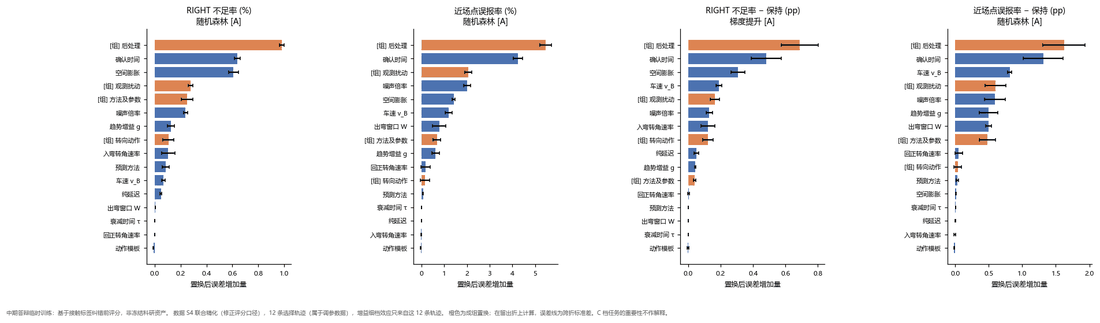

tavotoo 文件：07_M4_趋势增益精化\M4__fig05_置换重要性.pdf（独立入口 07_M4_趋势增益精化\M4__fig05_置换重要性.py）
原始程序：M4_趋势增益精化/train.py（训练）+ common/figures.py（出图） → family_figures()；数据：_data/M4_趋势增益精化/


In [65]:
show("M4__fig05_置换重要性")

**读出来的结论**：RIGHT 不足率：后处理组 0.983、确认时间 0.637、空间膨胀 0.609。RIGHT 不足率 − 保持：后处理组 0.688、确认 0.48、膨胀 0.306、车速 0.189。与 图 14 一致：增益细调的作用远小于后处理。

**用法**：支持“增益不必精调”的结论。

In [66]:
cm4 = json.loads((DATA / "M4_趋势增益精化" / "confusion_matrices.json").read_text(encoding="utf-8"))
print("数据来源：", next(iter(cm4.values()))["source"])
display(cm_table(cm4))

数据来源： 按轨迹4折 折外预测（阈值交叉拟合：每折阈值只用其余折确定）


取值   真阴性  假阳性  假阴性   真阳性     召回    精确率
任务       阈值                                                       
出现窗口漏报   默认阈值 0.5        0.500  6228  257  192  1387  0.878  0.844
         安全优先      0.468–0.540  6241  244  194  1385  0.877  0.850
接触前完全无报警 默认阈值 0.5        0.500  6556   95  272  1141  0.808  0.923
         安全优先      0.331–0.377  6381  270  153  1260  0.892  0.824
误报预算达标   默认阈值 0.5        0.500  4764  199  191  2910  0.938  0.936
         安全优先      0.637–0.654  4844  119  315  2786  0.898  0.959

### 图 46　M4 分类任务的混淆矩阵（交叉拟合阈值）

- **结论**：没有外部集时，用交叉拟合选出的“安全优先”阈值，实际召回 0.88–0.90，略低于 90% 的目标，这是诚实估计应有的结果。
- **证据**：3 行 × 2 列的 2 × 2 混淆矩阵；安全优先阈值标出 4 折中的取值范围。**类型**：quantitative grid。**口径**：按轨迹 4 折折外预测，每折的阈值只用其余折确定。

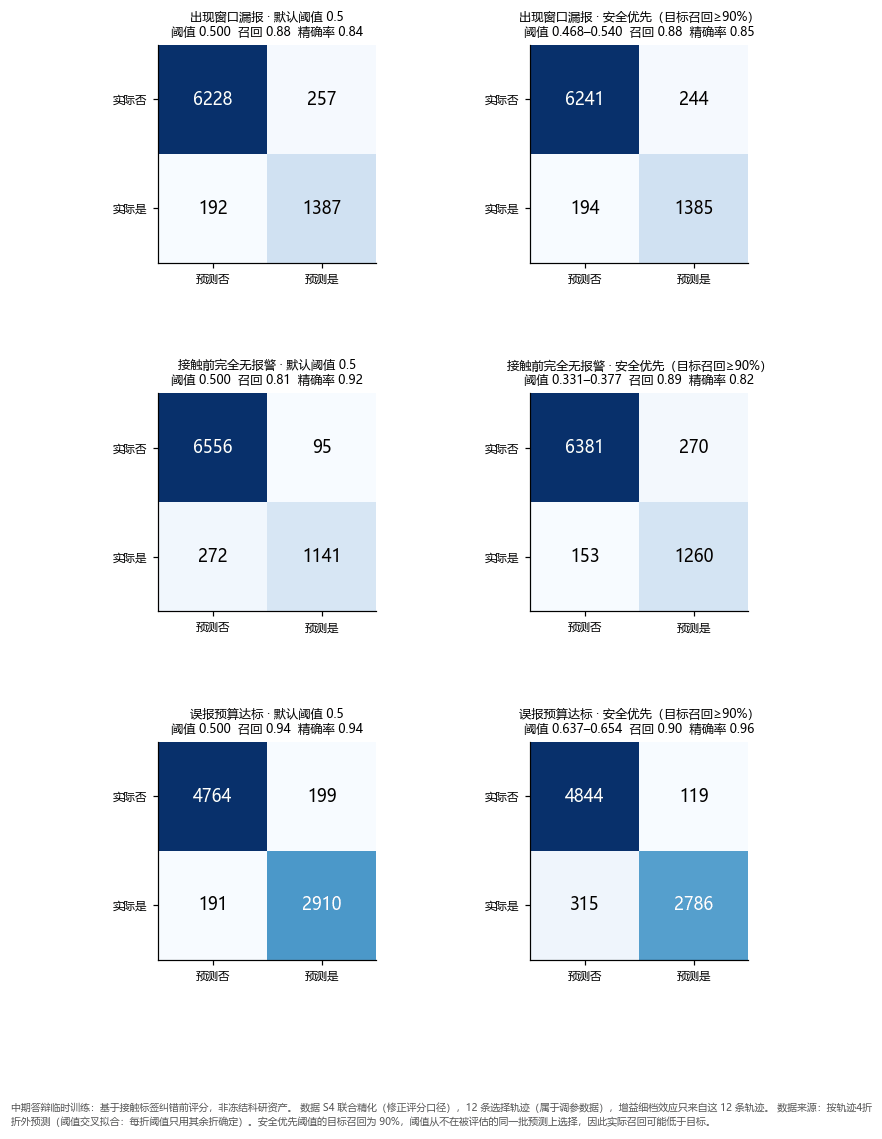

tavotoo 文件：07_M4_趋势增益精化\M4__fig06_混淆矩阵.pdf（独立入口 07_M4_趋势增益精化\M4__fig06_混淆矩阵.py）
原始程序：M4_趋势增益精化/train.py（训练）+ common/figures.py（出图） → family_figures()；数据：_data/M4_趋势增益精化/


In [67]:
show("M4__fig06_混淆矩阵")

**读出来的结论**：安全优先阈值下：出现窗口漏报召回 0.877（阈值 0.468–0.540），接触前完全无报警召回 0.892（0.331–0.377），误报预算达标召回 0.898（0.637–0.654）。

**用法**：说明分类器的阈值是怎么选的、实际能达到什么召回。不要把它当作车载报警的阈值。

### 图 47　M4 分类任务的 ROC 与 PR 曲线

- **结论**：三个分类任务的 AUC 都约 0.99。
- **证据**：a ROC 曲线，b 精确率–召回曲线。**类型**：quantitative grid。**口径**：按轨迹 4 折折外预测；曲线由保存的原图曲线数组重放。

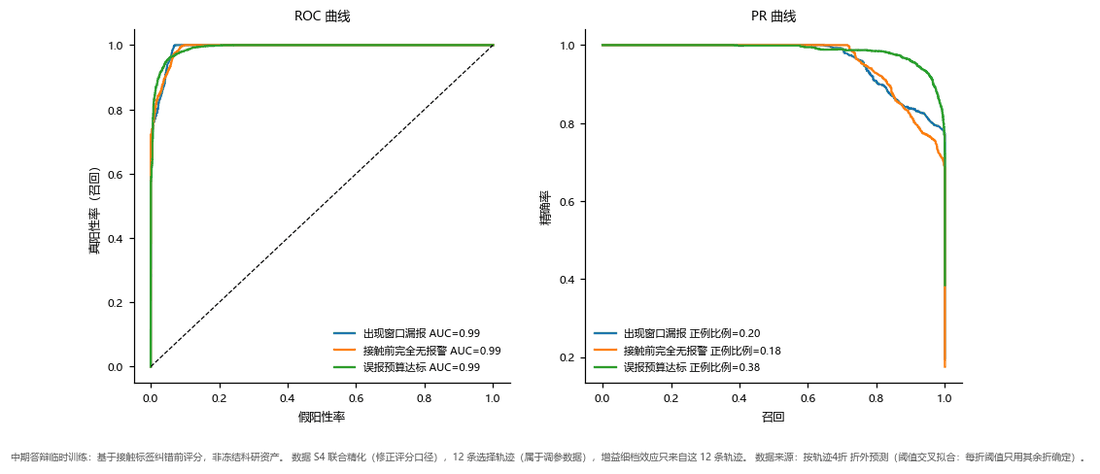

tavotoo 文件：07_M4_趋势增益精化\M4__fig07_ROC_PR.pdf（独立入口 07_M4_趋势增益精化\M4__fig07_ROC_PR.py）
原始程序：M4_趋势增益精化/train.py（训练）+ common/figures.py（出图） → family_figures()；数据：_data/M4_趋势增益精化/


In [68]:
show("M4__fig07_ROC_PR")

**读出来的结论**：AUC：出现窗口漏报 0.990、接触前完全无报警 0.990、误报预算达标 0.991。

**用法**：同 M3 fig07；这是折外成绩，不是外部检验。

### 6.9 全部代理模型总览

### 图 48　全部 64 个任务的临时表现分档

**图表契约**
- **结论**：5 个模型族共 64 个任务，57 个 A 档、7 个 B 档、没有 C 档；B 档全部来自只有 6 条轨迹的 M2a 和 M2b。
- **证据**：单面板：每根柱是一个任务主方案下的 skill，颜色为分档（绿 A / 橙 B / 红 C），黑色菱形为 M3 的外部检验 skill，绿色点线为 A 档阈值 0.3。
- **类型**：quantitative grid。
- **口径**：柱为开发集交叉验证成绩（含模型类别选择，略偏乐观）；分档只衡量对纠错前评分的预测能力，不是科研准入。

**怎么读**：横轴标签为“模型族 · 目标”，字号很小，请看 PDF 或下表。

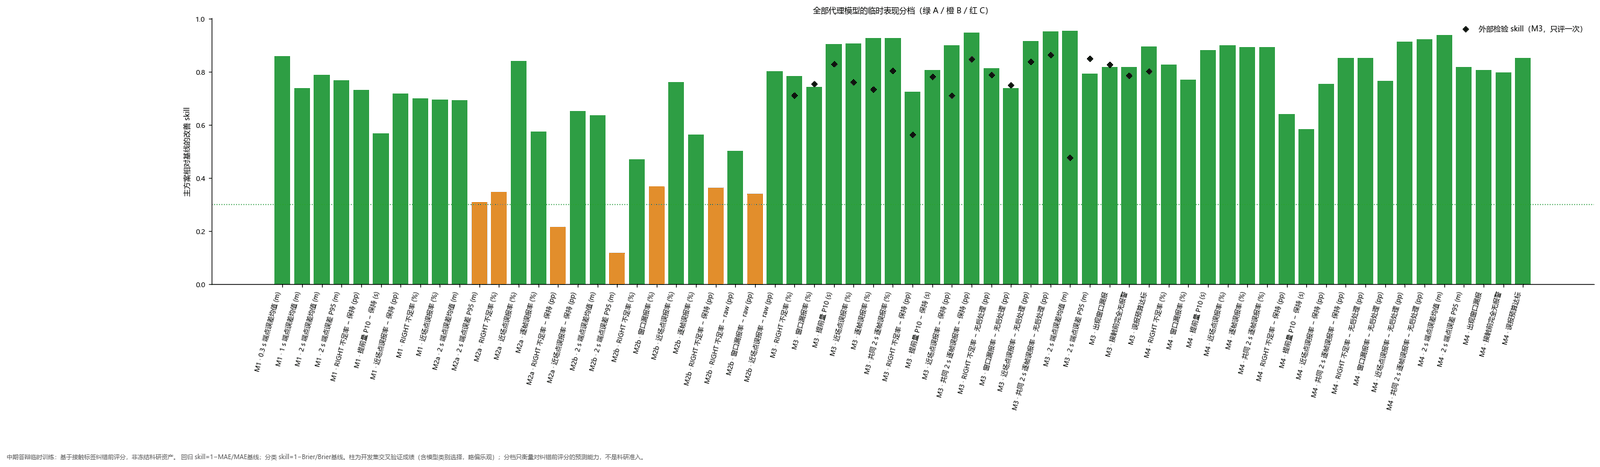

tavotoo 文件：08_汇总\fig11_全部模型临时表现分档总图.pdf（独立入口 08_汇总\fig11_全部模型临时表现分档总图.py）
原始程序：汇总/summarize.py → work()；数据：_data/M*/tiers.csv


tier,A,B
family,,
M1,9,0
M2a,4,3
M2b,6,4
M3,19,0
M4,19,0
合计,57,7


共 64 个任务；M3 外部检验 skill 0.476–0.864


In [69]:
show("fig11_全部模型临时表现分档总图", width=1600)
tiers = pd.concat([load(f"{f}/tiers") for f in FAMILIES], ignore_index=True)
counts = tiers.pivot_table(index="family", columns="tier", values="task", aggfunc="count", fill_value=0)
counts.loc["合计"] = counts.sum()
display(counts)
print(f"共 {len(tiers)} 个任务；M3 外部检验 skill {tiers.external_skill.min():.3f}–{tiers.external_skill.max():.3f}")

**读出来的结论**：M1 9 / 0、M2a 4 / 3、M2b 6 / 4、M3 19 / 0、M4 19 / 0（A / B）。M3 的外部检验 skill（黑色菱形）普遍略低于柱，印证主方案略偏乐观；但最低也有 0.48。

**用法**：答辩时概括“代理模型能学到什么”的一张总图。逐项数值见 `汇总/临时模型表现分档总表.md`。

## 7 讨论与局限

**主要发现**（都只在单一转弯几何、低速、静态目标的运动学仿真内成立）：

1. **趋势外推有效**：S1 中除 linear_g200 外的 17 个配置在 27/27 条轨迹上 RIGHT 不足率都低于保持，衰减线性 τ = 1 s 平均降低 1.36 pp（图 9）；收益随车速和转向速率增大（图 11）；几何上适度外推的端点误差最小（图 8），机制见案例（图 1）。
2. **迟报与误报此消彼长**：适度外推两方面都优于保持，但外推配置之间没有同时最优的（图 10）。
3. **噪声主要推高误报、延迟主要推高迟报**；状态估计能大幅降误报，但带来窗口漏报（图 12）。
4. **后处理是最强的旋钮**：确认 0.1 s 大幅降误报，但明显增加迟报和漏报；膨胀 0.05 m 正好相反；两者合用接近折中（图 13）。代理模型的置换重要性和部分依赖给出同样的排序（图 35、图 40）。
5. **增益细调空间很小**：在选定方法附近，迟报只变化约 0.1 pp，误报变化更大（图 14）。
6. **剩下的迟报主要来自“开始转向后不到 1 s 就接触”的目标**，只用历史数据的方法都无法提前 1 s（图 2）。
7. **这些规律能被代理模型学到，并推广到同一几何内没见过的轨迹**：64 个任务中 57 个 A 档，M3 外部检验 skill 0.48–0.86（图 48）。它证明的是“规律稳定”，不是“评分正确”。

**局限**：

- 只有一种转弯几何（90°、转角峰值 10°）、2–4 m/s、静态目标、无侧滑；结论不能外推到其他路口形状和车速。学习曲线已经变平（图 39），下一步应增加新的转弯几何，而不是同一几何下的更多轨迹。
- 接触标签纠错尚未完成：绝对值会变；配对差方向有区间旁证，但旁证只覆盖一条轨迹，且噪声条件下方向不确定（图 15）。
- 评分行、目标点和帧都不是独立的车辆试验；最接近独立样本的是轨迹（开发 27 条 + 选择 12 条）。
- S1、S2 为 v3 口径，S3、S4 为修正口径，误报类数值不能跨阶段直接比较。
- M2a、M2b 只有 6 条轨迹；M4 的 12 条轨迹同时是调参数据，没有外部检验。
- 主方案成绩含“按同一成绩选模型类别”的乐观偏差，M3 外部检验没有。
- 这里的模型不直接转为正式模型：正式研究要等纠错完成、全部实验完成后，重新冻结数据、分组、评估协议和训练版本，再训练正式模型。

## 附录 A　其余四张数据表的探索图

与 图 3–图 5 同样的三种图，分别画 D1（S1）、D2（S2）、D4（S4 状态估计）、D5（S4 联合精化）。图的读法见 4.3 节，这里只写每张表各自的特点。

### D1（S1 方法对照，513 行，27 条轨迹，clean，v3 口径）

### 图 49　D1 的 8 个主要指标分布

**图表契约**：结论见下；证据为 8 个指标的直方图；类型 quantitative grid；口径为 D1（S1 方法对照，513 行，27 条轨迹，clean，v3 口径），绝对值只作描述，端点误差按作业去重。

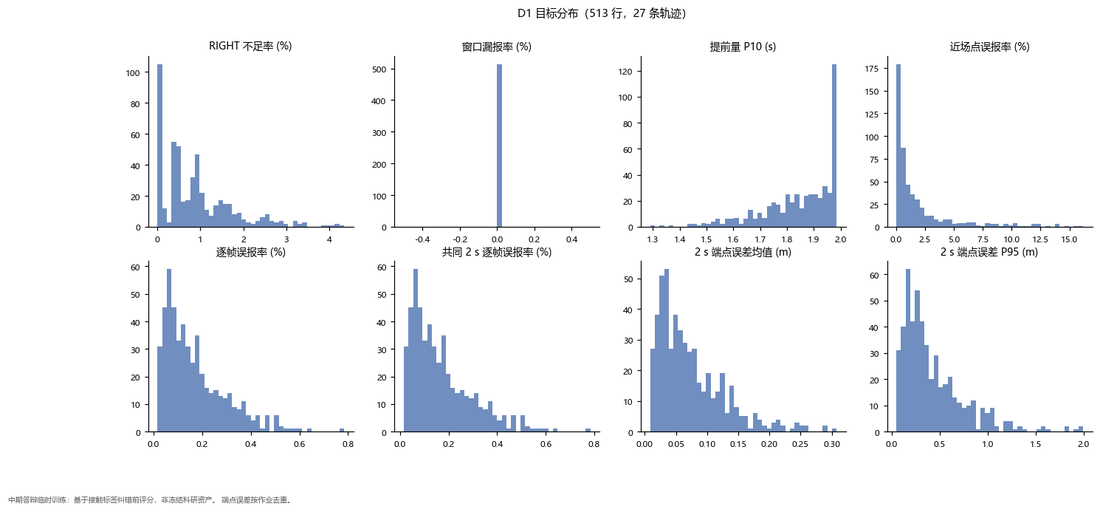

tavotoo 文件：01_数据探索\01_目标分布_D1.pdf（独立入口 01_数据探索\01_目标分布_D1.py）
原始程序：P0_数据整理/build_all.py → explore()；数据：_data/D1.csv


,n,中位数,P90,最大,取 0 的比例
RIGHT 不足率 (%),513.0,0.732,2.008,4.340,0.0
窗口漏报率 (%),513.0,0.000,0.000,0.000,1.0
提前量 P10 (s),513.0,1.880,1.985,1.985,0.0
近场点误报率 (%),513.0,0.776,5.710,16.166,0.0
逐帧误报率 (%),513.0,0.136,0.348,0.784,0.0
共同 2 s 逐帧误报率 (%),513.0,0.136,0.348,0.784,0.0
2 s 端点误差均值 (m),513.0,0.058,0.144,0.308,0.0
2 s 端点误差 P95 (m),513.0,0.322,0.867,1.993,0.0


出现窗口漏报的行占 0.0%（0 行）；误报预算达标 88.5%
近场误报率最高的行：v4_r8_fast_entry · second_a1000 · clean · raw · W2_m0_c0（16.2%）


In [70]:
show("01_目标分布_D1")
d = D["D1"]
display(dist_table(d))
mx = d.loc[d.negative_fp_pct.idxmax()]
print(f"出现窗口漏报的行占 {d.any_window_miss.mean():.1%}（{int(d.any_window_miss.sum())} 行）；误报预算达标 {d.fp_budget_pass.mean():.1%}")
print(f"近场误报率最高的行：{mx.case_id} · {mx.config_id} · {mx.condition} · {mx.processor} · {mx.variant}（{mx.negative_fp_pct:.1f}%）")

**读出来的结论**：S1 clean 中没有一行出现窗口漏报（窗口漏报率恒为 0，所以 图 51 里没有它）；RIGHT 不足率中位数 0.73%、P90 2.01%、最大 4.34%；近场误报率中位数 0.78%、P90 5.71%、最大 16.2%；误报预算达标 88.5%。

**用法**：说明 S1 的误报整体很低、差异主要在迟报上；数值为 v3 口径，只作描述。

### 图 50　D1 输入之间的相关性

**图表契约**：结论见下；证据为输入（含方法 / 输入处理哑变量）之间的 Spearman 相关矩阵；类型 quantitative grid；口径为 D1（S1 方法对照，513 行，27 条轨迹，clean，v3 口径）。下表列出 |ρ| ≥ 0.3 的变量对。

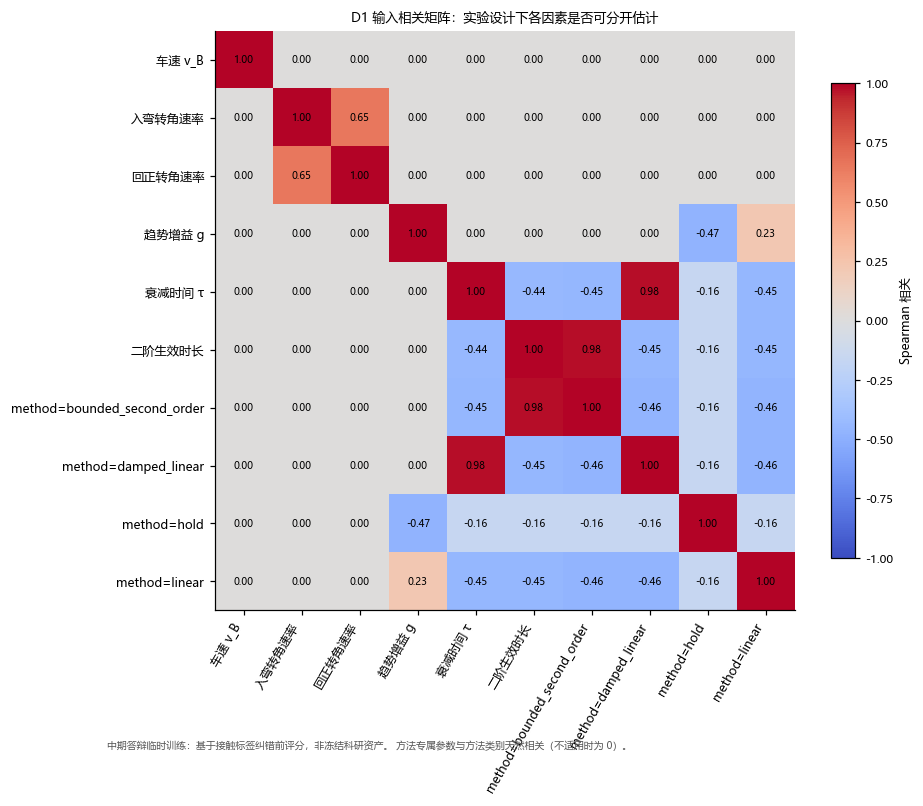

tavotoo 文件：01_数据探索\02_输入相关矩阵_D1.pdf（独立入口 01_数据探索\02_输入相关矩阵_D1.py）
原始程序：P0_数据整理/build_all.py → explore()；数据：_data/D1.csv


,变量 1,变量 2,Spearman ρ
6,二阶生效时长,方法=bounded_second_order,0.98
4,衰减时间 τ,方法=damped_linear,0.98
0,入弯转角速率,回正转角速率,0.65
1,趋势增益 g,方法=hold,-0.47
11,方法=damped_linear,方法=linear,-0.46
9,方法=bounded_second_order,方法=damped_linear,-0.46
10,方法=bounded_second_order,方法=linear,-0.46
3,衰减时间 τ,方法=bounded_second_order,-0.45
7,二阶生效时长,方法=damped_linear,-0.45
5,衰减时间 τ,方法=linear,-0.45


In [71]:
show("02_输入相关矩阵_D1")
display(strong_pairs(input_corr(D["D1"])))

**读出来的结论**：除方法参数与方法类别的编码绑定（τ 与衰减线性、T_a 与受限二阶均为 0.98，各方法哑变量之间 −0.46）外，只有入弯—回正转角速率 0.65。τ 与 T_a 的 −0.44 也来自编码：两者不会同时非零。

**用法**：说明 S1 的驾驶因素与方法因素可以分开估计。

### 图 51　D1 输出指标之间的相关性

**图表契约**：结论见下；证据为输出指标之间的 Spearman 相关矩阵；类型 quantitative grid；口径为 D1（S1 方法对照，513 行，27 条轨迹，clean，v3 口径），绝对值之间的相关只作描述。

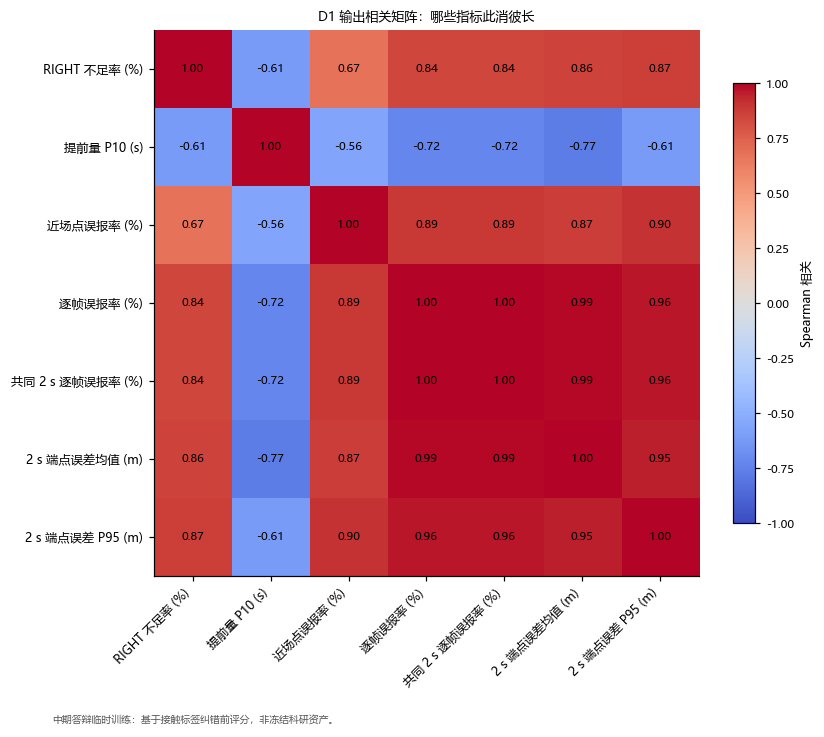

tavotoo 文件：01_数据探索\03_输出相关矩阵_D1.pdf（独立入口 01_数据探索\03_输出相关矩阵_D1.py）
原始程序：P0_数据整理/build_all.py → explore()；数据：_data/D1.csv


,指标 1,指标 2,Spearman ρ
0,RIGHT 不足率 (%),近场点误报率 (%),0.67
1,RIGHT 不足率 (%),逐帧误报率 (%),0.84
2,RIGHT 不足率 (%),提前量 P10 (s),-0.61
3,RIGHT 不足率 (%),2 s 端点误差均值 (m),0.86
4,近场点误报率 (%),2 s 端点误差均值 (m),0.87
5,2 s 端点误差 P95 (m),逐帧误报率 (%),0.96


In [72]:
show("03_输出相关矩阵_D1")
c = output_corr(D["D1"])
pairs = [("right_pct", "negative_fp_pct"), ("right_pct", "frame_fpr_pct"), ("right_pct", "right_lead_p10_s"),
         ("right_pct", "geom_2.0_mean"), ("negative_fp_pct", "geom_2.0_mean"), ("geom_2.0_p95", "frame_fpr_pct")]
if "right_miss_rate" in [t for t in TARGETS if D["D1"][t].nunique() > 1]:
    pairs.append(("right_pct", "right_miss_rate"))
display(pick_pairs(c, pairs))

**读出来的结论**：与 D3 相反，这里所有指标同向变化：RIGHT 不足率与近场误报 +0.67、与逐帧误报 +0.84、与 2 s 端点误差 +0.86。没有后处理变化时，难的轨迹（快、急）迟报多、误报也多、几何误差也大；D3 中的“此消彼长”主要来自后处理。

**用法**：提醒读者相关性取决于数据里变化的是什么因素，不能脱离实验设计解读。

### D2（S2 观测扰动，864 行，6 条轨迹，v3 口径）

### 图 52　D2 的 8 个主要指标分布

**图表契约**：结论见下；证据为 8 个指标的直方图；类型 quantitative grid；口径为 D2（S2 观测扰动，864 行，6 条轨迹，v3 口径），绝对值只作描述，端点误差按作业去重。

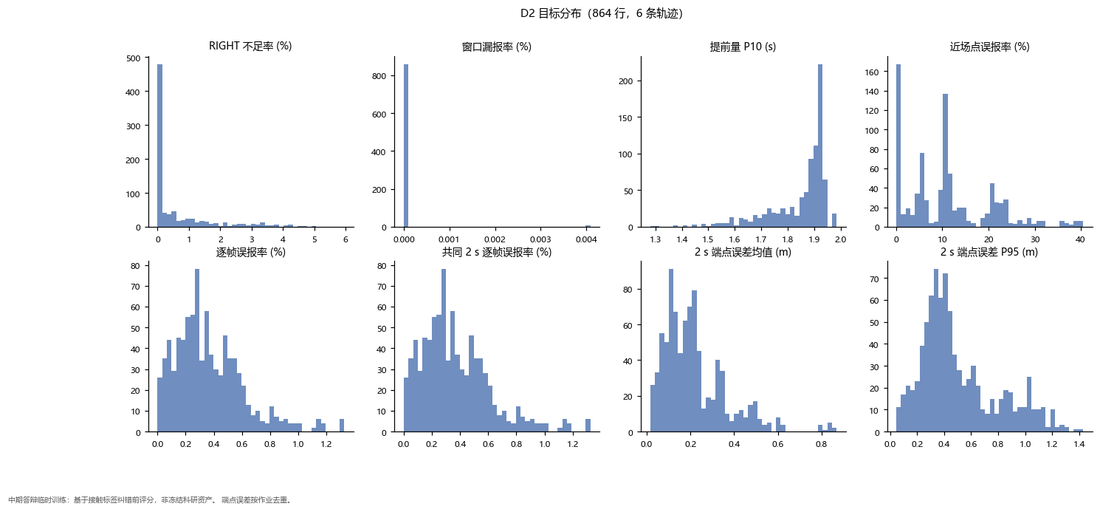

tavotoo 文件：01_数据探索\01_目标分布_D2.pdf（独立入口 01_数据探索\01_目标分布_D2.py）
原始程序：P0_数据整理/build_all.py → explore()；数据：_data/D2.csv


,n,中位数,P90,最大,取 0 的比例
RIGHT 不足率 (%),864.0,0.066,2.545,5.950,0.385
窗口漏报率 (%),864.0,0.000,0.000,0.004,0.993
提前量 P10 (s),864.0,1.895,1.930,1.985,0.000
近场点误报率 (%),864.0,10.412,23.413,40.449,0.000
逐帧误报率 (%),864.0,0.319,0.672,1.326,0.000
共同 2 s 逐帧误报率 (%),864.0,0.319,0.672,1.326,0.000
2 s 端点误差均值 (m),864.0,0.188,0.434,0.868,0.000
2 s 端点误差 P95 (m),864.0,0.421,0.983,1.428,0.000


出现窗口漏报的行占 0.7%（6 行）；误报预算达标 26.4%
近场误报率最高的行：v4_r2_fast_return · damped_d1000 · noise200_s3 · raw · W2_m0_c0（40.4%）


In [73]:
show("01_目标分布_D2")
d = D["D2"]
display(dist_table(d))
mx = d.loc[d.negative_fp_pct.idxmax()]
print(f"出现窗口漏报的行占 {d.any_window_miss.mean():.1%}（{int(d.any_window_miss.sum())} 行）；误报预算达标 {d.fp_budget_pass.mean():.1%}")
print(f"近场误报率最高的行：{mx.case_id} · {mx.config_id} · {mx.condition} · {mx.processor} · {mx.variant}（{mx.negative_fp_pct:.1f}%）")

**读出来的结论**：近场误报率中位数 10.4%、P90 23.4%、最大 40.4%；RIGHT 不足率 39% 的行为 0；出现窗口漏报的行只占 0.7%（6 行）；误报预算达标只有 26.4%：噪声是误报的主因。

**用法**：说明加入观测扰动后，误报成为主要矛盾。

### 图 53　D2 输入之间的相关性

**图表契约**：结论见下；证据为输入（含方法 / 输入处理哑变量）之间的 Spearman 相关矩阵；类型 quantitative grid；口径为 D2（S2 观测扰动，864 行，6 条轨迹，v3 口径）。下表列出 |ρ| ≥ 0.3 的变量对。

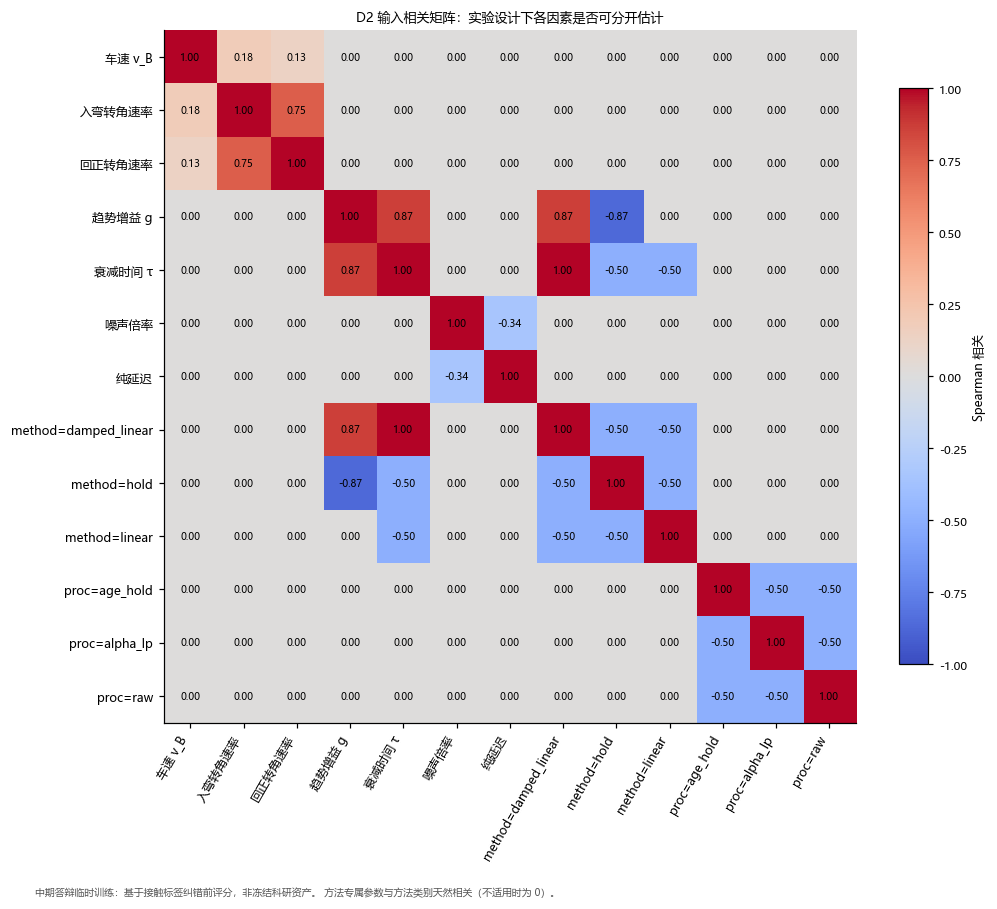

tavotoo 文件：01_数据探索\02_输入相关矩阵_D2.pdf（独立入口 01_数据探索\02_输入相关矩阵_D2.py）
原始程序：P0_数据整理/build_all.py → explore()；数据：_data/D2.csv


,变量 1,变量 2,Spearman ρ
4,衰减时间 τ,方法=damped_linear,1.00
1,趋势增益 g,衰减时间 τ,0.87
3,趋势增益 g,方法=hold,-0.87
2,趋势增益 g,方法=damped_linear,0.87
0,入弯转角速率,回正转角速率,0.75
5,衰减时间 τ,方法=hold,-0.50
6,衰减时间 τ,方法=linear,-0.50
8,方法=damped_linear,方法=hold,-0.50
9,方法=damped_linear,方法=linear,-0.50
10,方法=hold,方法=linear,-0.50


In [74]:
show("02_输入相关矩阵_D2")
display(strong_pairs(input_corr(D["D2"])))

**读出来的结论**：除编码绑定外，入弯—回正转角速率 0.75（6 条代表轨迹的组合），噪声与延迟 −0.34：观测条件要么加噪声、要么加延迟，只有 combined 两者都有，这是条件设计造成的。

**用法**：分析噪声和延迟的作用时要意识到两者在设计上轻度负相关。

### 图 54　D2 输出指标之间的相关性

**图表契约**：结论见下；证据为输出指标之间的 Spearman 相关矩阵；类型 quantitative grid；口径为 D2（S2 观测扰动，864 行，6 条轨迹，v3 口径），绝对值之间的相关只作描述。

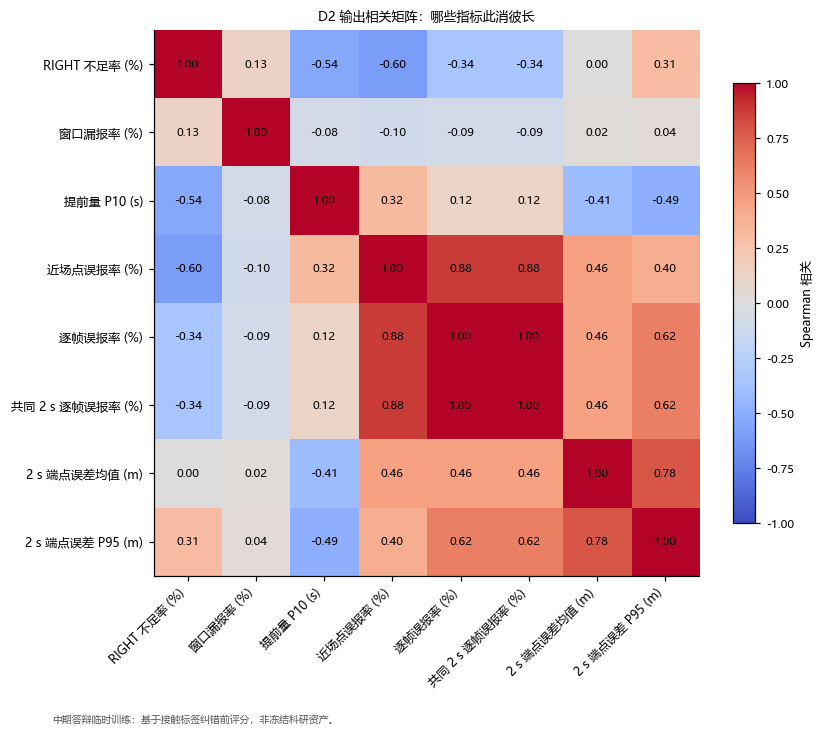

tavotoo 文件：01_数据探索\03_输出相关矩阵_D2.pdf（独立入口 01_数据探索\03_输出相关矩阵_D2.py）
原始程序：P0_数据整理/build_all.py → explore()；数据：_data/D2.csv


,指标 1,指标 2,Spearman ρ
0,RIGHT 不足率 (%),近场点误报率 (%),-0.60
1,RIGHT 不足率 (%),逐帧误报率 (%),-0.34
2,RIGHT 不足率 (%),提前量 P10 (s),-0.54
3,RIGHT 不足率 (%),2 s 端点误差均值 (m),0.00
4,近场点误报率 (%),2 s 端点误差均值 (m),0.46
5,2 s 端点误差 P95 (m),逐帧误报率 (%),0.62
6,RIGHT 不足率 (%),窗口漏报率 (%),0.13


In [75]:
show("03_输出相关矩阵_D2")
c = output_corr(D["D2"])
pairs = [("right_pct", "negative_fp_pct"), ("right_pct", "frame_fpr_pct"), ("right_pct", "right_lead_p10_s"),
         ("right_pct", "geom_2.0_mean"), ("negative_fp_pct", "geom_2.0_mean"), ("geom_2.0_p95", "frame_fpr_pct")]
if "right_miss_rate" in [t for t in TARGETS if D["D2"][t].nunique() > 1]:
    pairs.append(("right_pct", "right_miss_rate"))
display(pick_pairs(c, pairs))

**读出来的结论**：RIGHT 不足率与近场误报 −0.60；2 s 端点误差均值与 RIGHT 不足率无关（0.00），与近场误报正相关（0.46）：噪声同时抬高了几何误差和误报。

**用法**：说明噪声条件下几何误差主要反映在误报上，而不是迟报上。

### D4（S4 状态估计筛选，576 行，6 条轨迹，修正口径）

### 图 55　D4 的 8 个主要指标分布

**图表契约**：结论见下；证据为 8 个指标的直方图；类型 quantitative grid；口径为 D4（S4 状态估计筛选，576 行，6 条轨迹，修正口径），绝对值只作描述，端点误差按作业去重。

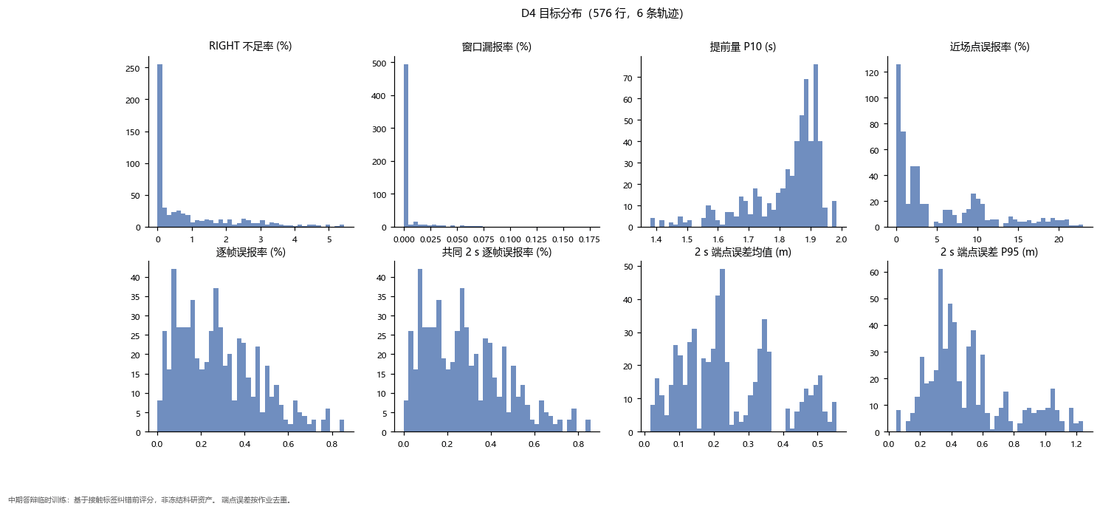

tavotoo 文件：01_数据探索\01_目标分布_D4.pdf（独立入口 01_数据探索\01_目标分布_D4.py）
原始程序：P0_数据整理/build_all.py → explore()；数据：_data/D4.csv


,n,中位数,P90,最大,取 0 的比例
RIGHT 不足率 (%),576.0,0.294,2.950,5.449,0.304
窗口漏报率 (%),576.0,0.000,0.014,0.176,0.844
提前量 P10 (s),576.0,1.865,1.925,1.985,0.000
近场点误报率 (%),576.0,2.586,15.047,22.937,0.000
逐帧误报率 (%),576.0,0.261,0.536,0.856,0.000
共同 2 s 逐帧误报率 (%),576.0,0.261,0.536,0.856,0.000
2 s 端点误差均值 (m),576.0,0.219,0.476,0.555,0.000
2 s 端点误差 P95 (m),576.0,0.429,0.984,1.242,0.000


出现窗口漏报的行占 15.6%（90 行）；误报预算达标 59.5%
近场误报率最高的行：v4_r8_fast_entry · damped_linear_g1000_d1000 · combined100_s3 · raw · W2_m0_c0（22.9%）


In [76]:
show("01_目标分布_D4")
d = D["D4"]
display(dist_table(d))
mx = d.loc[d.negative_fp_pct.idxmax()]
print(f"出现窗口漏报的行占 {d.any_window_miss.mean():.1%}（{int(d.any_window_miss.sum())} 行）；误报预算达标 {d.fp_budget_pass.mean():.1%}")
print(f"近场误报率最高的行：{mx.case_id} · {mx.config_id} · {mx.condition} · {mx.processor} · {mx.variant}（{mx.negative_fp_pct:.1f}%）")

**读出来的结论**：近场误报率中位数 2.59%、最大 22.9%；出现窗口漏报的行占 15.6%（raw 一行都没有，全来自状态估计）；误报预算达标 59.5%。

**用法**：与 图 12 c 一起看状态估计的代价。

### 图 56　D4 输入之间的相关性

**图表契约**：结论见下；证据为输入（含方法 / 输入处理哑变量）之间的 Spearman 相关矩阵；类型 quantitative grid；口径为 D4（S4 状态估计筛选，576 行，6 条轨迹，修正口径）。下表列出 |ρ| ≥ 0.3 的变量对。

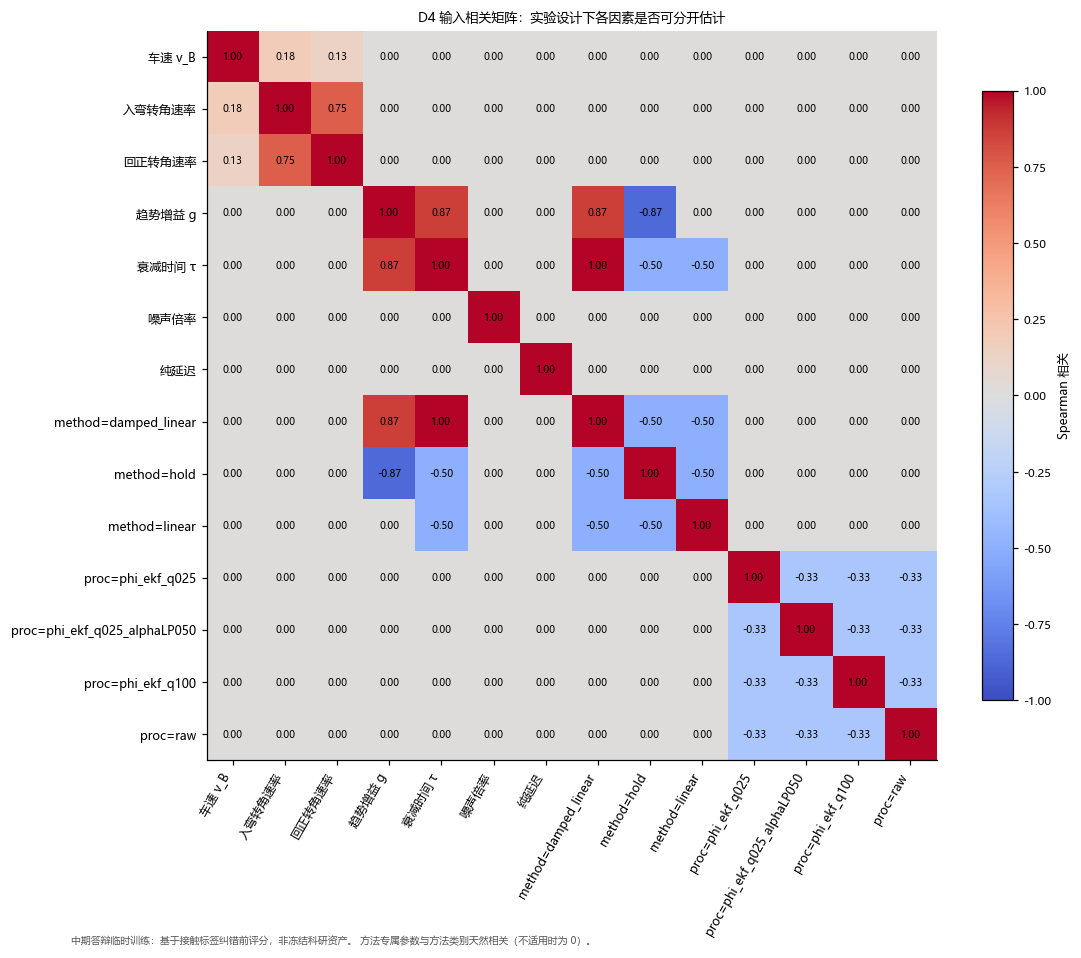

tavotoo 文件：01_数据探索\02_输入相关矩阵_D4.pdf（独立入口 01_数据探索\02_输入相关矩阵_D4.py）
原始程序：P0_数据整理/build_all.py → explore()；数据：_data/D4.csv


,变量 1,变量 2,Spearman ρ
4,衰减时间 τ,方法=damped_linear,1.00
1,趋势增益 g,衰减时间 τ,0.87
3,趋势增益 g,方法=hold,-0.87
2,趋势增益 g,方法=damped_linear,0.87
0,入弯转角速率,回正转角速率,0.75
5,衰减时间 τ,方法=hold,-0.50
6,衰减时间 τ,方法=linear,-0.50
7,方法=damped_linear,方法=hold,-0.50
8,方法=damped_linear,方法=linear,-0.50
9,方法=hold,方法=linear,-0.50


In [77]:
show("02_输入相关矩阵_D4")
display(strong_pairs(input_corr(D["D4"])))

**读出来的结论**：结构与 D2 相同：入弯—回正转角速率 0.75；4 种输入处理的哑变量两两 −0.33，是编码造成的。

**用法**：说明 S4 状态估计的设计是平衡的。

### 图 57　D4 输出指标之间的相关性

**图表契约**：结论见下；证据为输出指标之间的 Spearman 相关矩阵；类型 quantitative grid；口径为 D4（S4 状态估计筛选，576 行，6 条轨迹，修正口径），绝对值之间的相关只作描述。

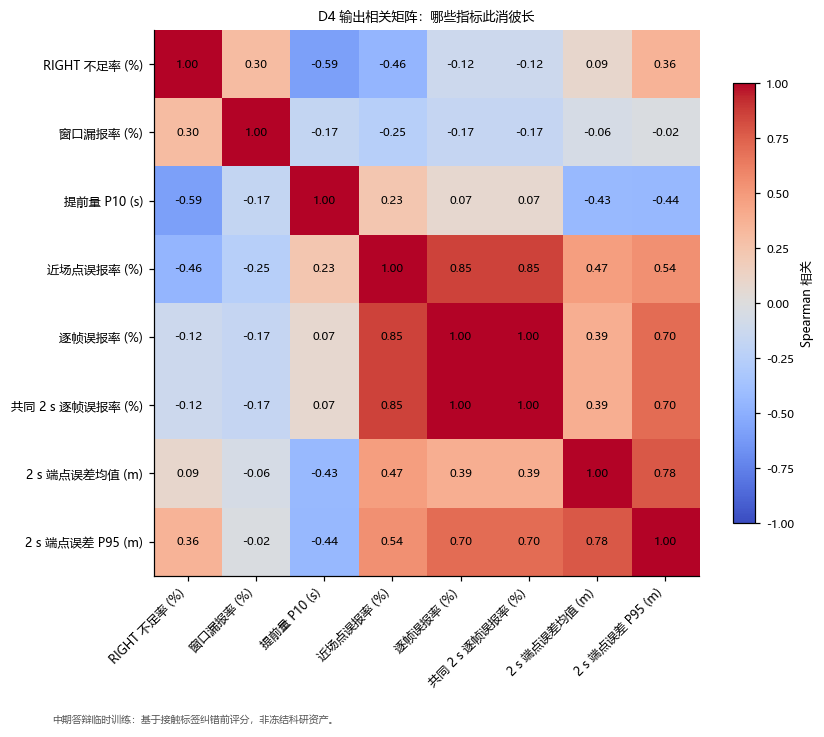

tavotoo 文件：01_数据探索\03_输出相关矩阵_D4.pdf（独立入口 01_数据探索\03_输出相关矩阵_D4.py）
原始程序：P0_数据整理/build_all.py → explore()；数据：_data/D4.csv


,指标 1,指标 2,Spearman ρ
0,RIGHT 不足率 (%),近场点误报率 (%),-0.46
1,RIGHT 不足率 (%),逐帧误报率 (%),-0.12
2,RIGHT 不足率 (%),提前量 P10 (s),-0.59
3,RIGHT 不足率 (%),2 s 端点误差均值 (m),0.09
4,近场点误报率 (%),2 s 端点误差均值 (m),0.47
5,2 s 端点误差 P95 (m),逐帧误报率 (%),0.70
6,RIGHT 不足率 (%),窗口漏报率 (%),0.30


In [78]:
show("03_输出相关矩阵_D4")
c = output_corr(D["D4"])
pairs = [("right_pct", "negative_fp_pct"), ("right_pct", "frame_fpr_pct"), ("right_pct", "right_lead_p10_s"),
         ("right_pct", "geom_2.0_mean"), ("negative_fp_pct", "geom_2.0_mean"), ("geom_2.0_p95", "frame_fpr_pct")]
if "right_miss_rate" in [t for t in TARGETS if D["D4"][t].nunique() > 1]:
    pairs.append(("right_pct", "right_miss_rate"))
display(pick_pairs(c, pairs))

**读出来的结论**：RIGHT 不足率与近场误报 −0.46、与窗口漏报率 +0.30；2 s 端点误差 P95 与逐帧误报 +0.70。

**用法**：同 D2：误报与几何尾部误差相关，迟报与误报此消彼长。

### D5（S4 联合精化，8,064 行，12 条选择轨迹，修正口径）

### 图 58　D5 的 8 个主要指标分布

**图表契约**：结论见下；证据为 8 个指标的直方图；类型 quantitative grid；口径为 D5（S4 联合精化，8,064 行，12 条选择轨迹，修正口径），绝对值只作描述，端点误差按作业去重。

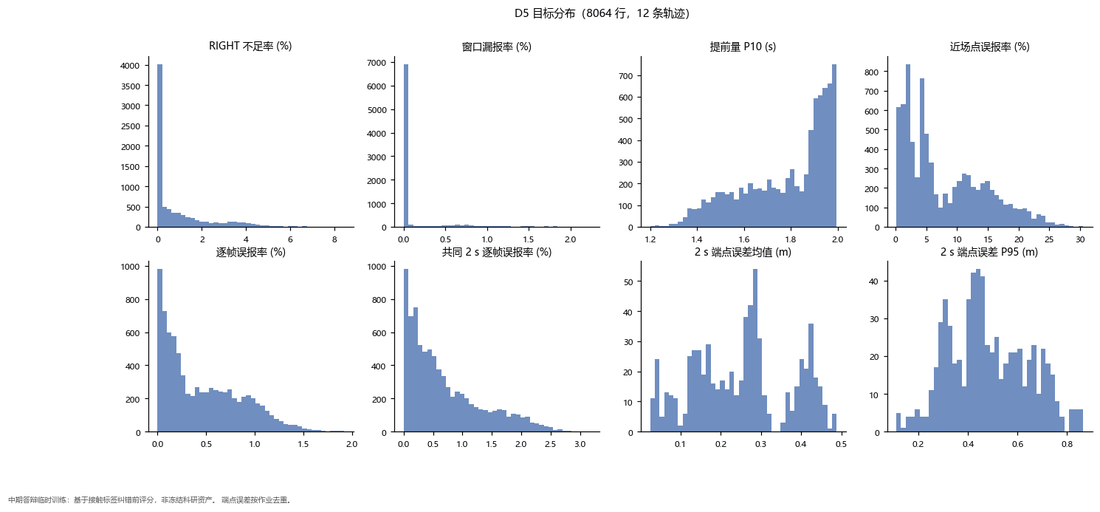

tavotoo 文件：01_数据探索\01_目标分布_D5.pdf（独立入口 01_数据探索\01_目标分布_D5.py）
原始程序：P0_数据整理/build_all.py → explore()；数据：_data/D5.csv


,n,中位数,P90,最大,取 0 的比例
RIGHT 不足率 (%),8064.0,0.214,3.319,8.433,0.347
窗口漏报率 (%),8064.0,0.000,0.551,2.238,0.804
提前量 P10 (s),8064.0,1.845,1.975,1.995,0.000
近场点误报率 (%),8064.0,5.452,17.726,30.442,0.000
逐帧误报率 (%),8064.0,0.363,1.040,1.918,0.000
共同 2 s 逐帧误报率 (%),8064.0,0.494,1.708,3.178,0.000
2 s 端点误差均值 (m),672.0,0.260,0.423,0.488,0.000
2 s 端点误差 P95 (m),672.0,0.458,0.707,0.864,0.000


出现窗口漏报的行占 19.6%（1579 行）；误报预算达标 38.5%
近场误报率最高的行：sel_v3.5_r6_fast_return · damped_linear_g1250_d1000 · combined100_s1 · raw · W3_m0.05_c0（30.4%）


In [79]:
show("01_目标分布_D5")
d = D["D5"]
display(dist_table(d))
mx = d.loc[d.negative_fp_pct.idxmax()]
print(f"出现窗口漏报的行占 {d.any_window_miss.mean():.1%}（{int(d.any_window_miss.sum())} 行）；误报预算达标 {d.fp_budget_pass.mean():.1%}")
print(f"近场误报率最高的行：{mx.case_id} · {mx.config_id} · {mx.condition} · {mx.processor} · {mx.variant}（{mx.negative_fp_pct:.1f}%）")

**读出来的结论**：RIGHT 不足率中位数 0.21%、P90 3.32%、最大 8.43%；出现窗口漏报的行占 19.6%；近场误报率中位数 5.45%；误报预算达标 38.5%。

**用法**：与 D3 的分布（图 3）相近，说明选择集与开发集的评分量级一致。

### 图 59　D5 输入之间的相关性

**图表契约**：结论见下；证据为输入（含方法 / 输入处理哑变量）之间的 Spearman 相关矩阵；类型 quantitative grid；口径为 D5（S4 联合精化，8,064 行，12 条选择轨迹，修正口径）。下表列出 |ρ| ≥ 0.3 的变量对。

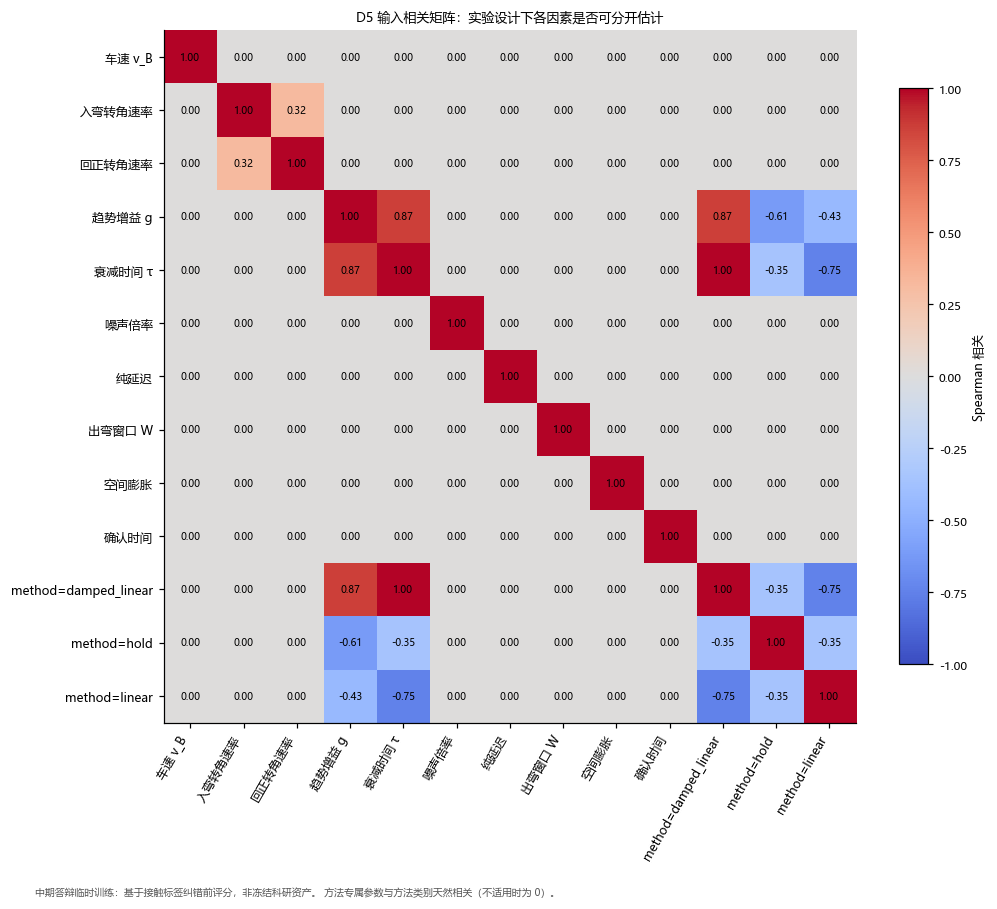

tavotoo 文件：01_数据探索\02_输入相关矩阵_D5.pdf（独立入口 01_数据探索\02_输入相关矩阵_D5.py）
原始程序：P0_数据整理/build_all.py → explore()；数据：_data/D5.csv


,变量 1,变量 2,Spearman ρ
5,衰减时间 τ,方法=damped_linear,1.00
2,趋势增益 g,方法=damped_linear,0.87
1,趋势增益 g,衰减时间 τ,0.87
9,方法=damped_linear,方法=linear,-0.75
7,衰减时间 τ,方法=linear,-0.75
3,趋势增益 g,方法=hold,-0.61
4,趋势增益 g,方法=linear,-0.43
8,方法=damped_linear,方法=hold,-0.35
6,衰减时间 τ,方法=hold,-0.35
10,方法=hold,方法=linear,-0.35


In [80]:
show("02_输入相关矩阵_D5")
display(strong_pairs(input_corr(D["D5"])))

**读出来的结论**：入弯—回正转角速率只有 0.32（选择集只有 r = 3、6 两档）；其余 |ρ| ≥ 0.3 的都是方法编码。

**用法**：说明增益细档与后处理、观测条件可以分开估计。

### 图 60　D5 输出指标之间的相关性

**图表契约**：结论见下；证据为输出指标之间的 Spearman 相关矩阵；类型 quantitative grid；口径为 D5（S4 联合精化，8,064 行，12 条选择轨迹，修正口径），绝对值之间的相关只作描述。

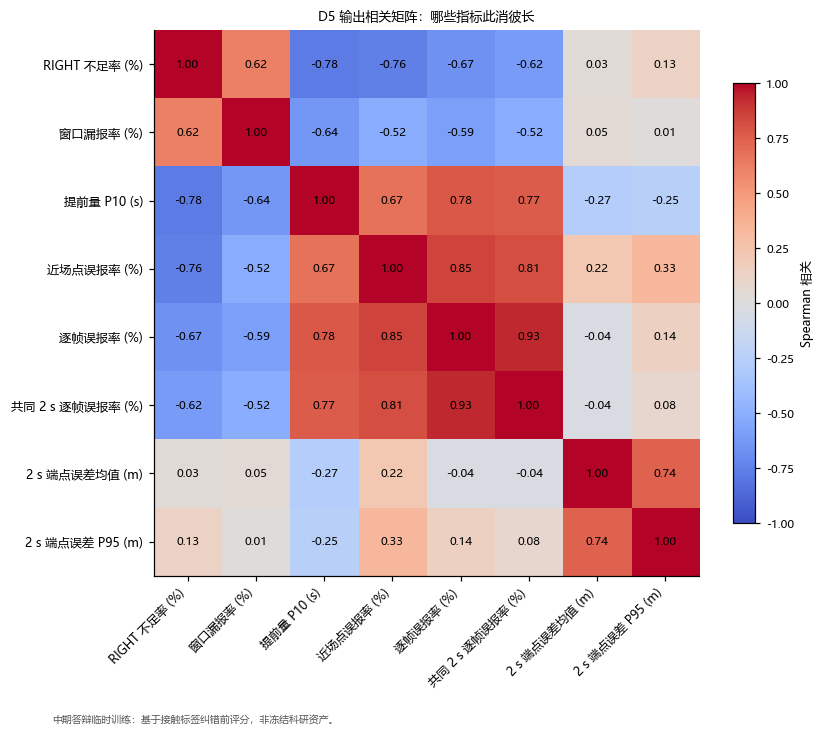

tavotoo 文件：01_数据探索\03_输出相关矩阵_D5.pdf（独立入口 01_数据探索\03_输出相关矩阵_D5.py）
原始程序：P0_数据整理/build_all.py → explore()；数据：_data/D5.csv


,指标 1,指标 2,Spearman ρ
0,RIGHT 不足率 (%),近场点误报率 (%),-0.76
1,RIGHT 不足率 (%),逐帧误报率 (%),-0.67
2,RIGHT 不足率 (%),提前量 P10 (s),-0.78
3,RIGHT 不足率 (%),2 s 端点误差均值 (m),0.03
4,近场点误报率 (%),2 s 端点误差均值 (m),0.22
5,2 s 端点误差 P95 (m),逐帧误报率 (%),0.14
6,RIGHT 不足率 (%),窗口漏报率 (%),0.62


In [81]:
show("03_输出相关矩阵_D5")
c = output_corr(D["D5"])
pairs = [("right_pct", "negative_fp_pct"), ("right_pct", "frame_fpr_pct"), ("right_pct", "right_lead_p10_s"),
         ("right_pct", "geom_2.0_mean"), ("negative_fp_pct", "geom_2.0_mean"), ("geom_2.0_p95", "frame_fpr_pct")]
if "right_miss_rate" in [t for t in TARGETS if D["D5"][t].nunique() > 1]:
    pairs.append(("right_pct", "right_miss_rate"))
display(pick_pairs(c, pairs))

**读出来的结论**：与 D3 几乎相同：RIGHT 不足率与近场误报 −0.76、与提前量 P10 −0.78；2 s 端点误差与 RIGHT 不足率几乎无关（0.03）。

**用法**：说明 D3 中观察到的权衡在选择集上同样成立。

## 附录 B　60 张图索引

按本 notebook 的图号排列：所在节、tavotoo 中的 PDF、独立入口、重建方式（original_plot_code = 原绘图代码重画；existing_svg_vector_replay = 从原 SVG 重建；existing_summary_table = 用已保存的分档表重画）和原始程序。

In [82]:
NB_ORDER = [('fig13_案例_预测区叠加', '3'), ('fig14_案例_报警接触时间轴', '3'), ('01_目标分布_D3', '4.3'), ('02_输入相关矩阵_D3', '4.3'), ('03_输出相关矩阵_D3', '4.3'), ('04_轨迹相似度_D3', '4.3'), ('05_特征与目标关系_D3', '4.3'), ('fig01_端点误差_各配置', '5.1'), ('fig02_配对迟报差_相对保持', '5.1'), ('fig03_迟报误报权衡', '5.1'), ('fig04_驾驶因素_配对收益热图', '5.1'), ('fig05_噪声延迟与状态估计', '5.2'), ('fig06_后处理三因素交互', '5.3'), ('fig07_趋势增益曲线', '5.4'), ('fig12_标签区间旁证', '5.5'), ('M1__fig01_模型对比与分档', '6.4'), ('M1__fig02_预测vs实际_折外', '6.4'), ('M1__fig03_残差诊断', '6.4'), ('M1__fig04_分段误差', '6.4'), ('M1__fig05_置换重要性', '6.4'), ('M2a__fig01_模型对比与分档', '6.5'), ('M2a__fig02_预测vs实际_折外', '6.5'), ('M2a__fig03_残差诊断', '6.5'), ('M2a__fig04_分段误差', '6.5'), ('M2a__fig05_置换重要性', '6.5'), ('M2b__fig01_模型对比与分档', '6.6'), ('M2b__fig02_预测vs实际_折外', '6.6'), ('M2b__fig03_残差诊断', '6.6'), ('M2b__fig04_分段误差', '6.6'), ('M2b__fig05_置换重要性', '6.6'), ('M3__fig01_模型对比与分档', '6.7'), ('M3__fig02_预测vs实际_折外', '6.7'), ('M3__fig03_残差诊断', '6.7'), ('M3__fig04_分段误差', '6.7'), ('M3__fig05_置换重要性', '6.7'), ('M3__fig06_混淆矩阵', '6.7'), ('M3__fig07_ROC_PR', '6.7'), ('M3__fig08_外部检验_预测vs实际', '6.7'), ('M3__fig09_学习曲线', '6.7'), ('M3__fig10_部分依赖_后处理', '6.7'), ('M4__fig01_模型对比与分档', '6.8'), ('M4__fig02_预测vs实际_折外', '6.8'), ('M4__fig03_残差诊断', '6.8'), ('M4__fig04_分段误差', '6.8'), ('M4__fig05_置换重要性', '6.8'), ('M4__fig06_混淆矩阵', '6.8'), ('M4__fig07_ROC_PR', '6.8'), ('fig11_全部模型临时表现分档总图', '6.9'), ('01_目标分布_D1', '附录 A'), ('02_输入相关矩阵_D1', '附录 A'), ('03_输出相关矩阵_D1', '附录 A'), ('01_目标分布_D2', '附录 A'), ('02_输入相关矩阵_D2', '附录 A'), ('03_输出相关矩阵_D2', '附录 A'), ('01_目标分布_D4', '附录 A'), ('02_输入相关矩阵_D4', '附录 A'), ('03_输出相关矩阵_D4', '附录 A'), ('01_目标分布_D5', '附录 A'), ('02_输入相关矩阵_D5', '附录 A'), ('03_输出相关矩阵_D5', '附录 A')]

assert sorted(s for s, _ in NB_ORDER) == sorted(ENTRY), "索引与 tavotoo 登记的图不一致"
idx = pd.DataFrame([{"图": i, "节": sec, "tavotoo PDF": ENTRY[s]["pdf"], "重建方式": ENTRY[s]["mode"],
                     "原始程序": "{} → {}".format(*origin(s)[:2])} for i, (s, sec) in enumerate(NB_ORDER, 1)]).set_index("图")
with pd.option_context("display.max_rows", 100, "display.max_colwidth", 80):
    display(idx)

,节,tavotoo PDF,重建方式,原始程序
图,,,,
1,3,02_描述性图表\fig13_案例_预测区叠加.pdf,existing_svg_vector_replay,描述性图表/make_case_figures.py → main()
2,3,02_描述性图表\fig14_案例_报警接触时间轴.pdf,existing_svg_vector_replay,描述性图表/make_case_figures.py → main()
3,4.3,01_数据探索\01_目标分布_D3.pdf,original_plot_code,P0_数据整理/build_all.py → explore()
4,4.3,01_数据探索\02_输入相关矩阵_D3.pdf,original_plot_code,P0_数据整理/build_all.py → explore()
5,4.3,01_数据探索\03_输出相关矩阵_D3.pdf,original_plot_code,P0_数据整理/build_all.py → explore()
6,4.3,01_数据探索\04_轨迹相似度_D3.pdf,original_plot_code,P0_数据整理/build_all.py → explore()
7,4.3,01_数据探索\05_特征与目标关系_D3.pdf,original_plot_code,P0_数据整理/build_all.py → explore()
8,5.1,02_描述性图表\fig01_端点误差_各配置.pdf,original_plot_code,描述性图表/make_figures.py → fig01()
9,5.1,02_描述性图表\fig02_配对迟报差_相对保持.pdf,original_plot_code,描述性图表/make_figures.py → fig02()


## 附录 C　如何重画与改图

| 想做什么 | 怎么做 | 会改动哪些文件 |
|---|---|---|
| 看图、读数（本 notebook） | Run All | 不改任何文件 |
| 调字号、颜色、图例、版式 | 打开 Tavotto，把整个 `tavotoo` 文件夹设为图库，把 PDF 拖到画布上双击编辑；提示连接源程序时选同名 `.py`，入口为 `__main__`（详见 `tavotoo/README.md`） | 只写 `tavotoo/tavottofile/` 中的修改记录 |
| 单独重画包内的一张图 | 运行该图的独立入口，例如 `python -X utf8 -B tavotoo/02_描述性图表/fig01_端点误差_各配置.py` | 覆盖包内同名 PDF |
| 从头重跑全部训练与出图 | 在 `06_中期答辩临时训练/` 下运行 `powershell -ExecutionPolicy Bypass -File run_all.ps1`（约 25 分钟） | 重写各步骤的 `data/`、`results/`、`model/`、`figures/` 和 `全部图表/` 下 8 个子目录的 PNG；不碰 `tavotoo/`，但重跑后包内副本会过时，需要重新同步 |

- `汇总/collect_figures.py` 只清理和写入 `全部图表/` 下它管理的 8 个子目录，不会删除 `tavotoo/` 里的 PNG 预览。
- 修改模型参数、案例选择、数据或统计数值，必须回到原程序和对应的受控流程，不能在 Tavotto 里改。
- 各模型族 `results/run_manifest.json` 记录了训练时的代码哈希、依赖版本和数据哈希；本 notebook 不重新训练，所以不改变这些记录。
- 图的样式：两张案例图（图 1、图 2）按 nature-figure 规范绘制；其余 58 张沿用中期训练时的原绘图样式（尺寸偏大、部分用 matplotlib 默认配色）。按规范统一改版的绘图脚本草稿保存在 git 分支 `dev/nature-figure-restyle`，尚未应用；应用后需要重新生成 tavotoo 包，图内元素顺序会变，已在 Tavotto 里做的修改需要复核。

## 附录 D　自检

核对三件事：60 张图都在本次运行中重画过；tavotoo 包内的文件一个都没有被改动或新增（Tavotto 自己的编辑记录 `tavottofile/` 不计）；重画用了多长时间。

In [83]:
missing = [s for s in ENTRY if s not in RENDERED]
changed = [str(p.relative_to(TAV)) for p, t in SNAPSHOT.items() if not p.exists() or p.stat().st_mtime_ns != t]
new = [str(p.relative_to(TAV)) for p in TAV.rglob("*") if p.is_file() and "tavottofile" not in p.parts and p not in SNAPSHOT]
print(f"本次重画 {len(RENDERED)} / {len(ENTRY)} 张；未重画：{missing or '无'}")
print(f"tavotoo 包内被改动的文件：{changed or '无'}；新增的文件：{new or '无'}")
print(f"重画总耗时 {sum(RENDERED.values()):.1f} s，最慢的一张 {max(RENDERED, key=RENDERED.get)}（{max(RENDERED.values()):.1f} s）")
assert not missing and not changed and not new, "自检未通过"
print("自检通过")

本次重画 60 / 60 张；未重画：无
tavotoo 包内被改动的文件：无；新增的文件：无
重画总耗时 110.7 s，最慢的一张 M3__fig10_部分依赖_后处理（5.7 s）
自检通过
